# Dog OCD genes and human GWAS signal

Human OCD, coronary artery disease (CAD), bipolar disorder (BIP), ADHD, major depressive disorder (MDD), and schizophrenia (SCZ)
associations near the 83 TOGA one-to-one
human orthologs of dog compulsive-disorder GWAS genes, plus the 48 ST6 Human genes.

Run the notebook from top to bottom using the project Python environment.
The default run reuses the existing gene-window tables, recalculates gene ranks
and 36 dog-set plus 12 Human-set Mann–Whitney tests, and redraws the CDFs. Tables and figures
are embedded below and exported to `notebook/results/ipynb/toga/`.
All generated plots and tables are also saved as PDFs and TSVs in the project-root
`plots_and_tables/` directory, each with a matching `.txt` explanation.
Set `REBUILD_WINDOWS = True` to rescan the GWAS inputs and recompute window scores;
set `REBUILD_LIFTOVER = True` as well to rebuild the OCD coordinate cache.
The supplied data files and original ST6 workbook must remain in this project.
BIP, ADHD, MDD and SCZ gene windows and permutations are built on first use and cached
under `notebook/results/ipynb/toga/`; subsequent default runs reuse verified caches.

This notebook converts the analysis in `src/`; the original scripts and results
remain available. See [the existing methods](notebook/results/METHODS.md) for
input provenance and the original interpretation. Dog-gene selection used human
OCD results, so this comparison is exploratory rather than independent replication.

## 1. Libraries and basic functions

In [1]:
import gzip
import hashlib
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)

In [2]:
# Locate the project even if the kernel starts in a child directory.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'dog_ocd_analysis.ipynb').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Start this notebook from the dog_ocd project directory.')
DATA = ROOT / 'data'
GWAS_DATA = DATA / 'downloaded/gwas'
OUT = ROOT / 'notebook/results'  # Established results used as inputs/checks.
WINDOW_CACHE = OUT / 'ipynb'
NOTEBOOK_OUT = WINDOW_CACHE / 'toga'
NOTEBOOK_OUT.mkdir(parents=True, exist_ok=True)
PLOTS_DIR = ROOT / 'plots_and_tables'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_plot(fig, path, **kwargs):
    """Save the existing figure output and a PDF copy in plots/."""
    fig.savefig(path, **kwargs)
    pdf_path = PLOTS_DIR / Path(path).with_suffix('.pdf').name
    fig.savefig(pdf_path, **kwargs)
    write_plot_explanation(pdf_path)

GWAS = GWAS_DATA / 'daner_OCD_full_wo23andMe_190522.gz'
GTF = DATA / 'downloaded/annotation/gencode.v50.annotation.gtf.gz'
CAD = GWAS_DATA / 'GCST90132314.h.tsv.gz'
CHAIN = Path.home() / 'data/liftover/hg19ToHg38.over.chain'
MAPPED = DATA / 'generated/mapped_grch38'
CAD_MD5 = '82e19c1817c52d5a94c8f42d9f48ccd0'
AUTOSOMES = {str(i) for i in range(1, 23)}
WINDOWS = (('1mb', 1_000_000, ''), ('500kb', 500_000, '_500kb'))
WINDOW_LABELS = {'1mb': '±1 Mb', '500kb': '±500 kb'}
DOG_SETS = (('significant', 'dog_significant'),
            ('suggestive', 'dog_suggestive'), ('combined', 'dog'))
SEED = 20261013
PLOT_MAX_LOGP = 15

REBUILD_WINDOWS = False
REBUILD_LIFTOVER = False  # Requires REBUILD_WINDOWS and the UCSC chain above.
RUN_PERMUTATIONS = False  # Recompute the original 10,000 circular shifts.
SHOW_ADDITIONAL_PLOTS = True
if REBUILD_LIFTOVER and not REBUILD_WINDOWS:
    raise ValueError('Set REBUILD_WINDOWS = True when rebuilding liftover.')

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.compare_psychiatric import (
    PSYCHIATRIC_GWAS, load_psychiatric_gene_windows, read_psychiatric_chunks
)
from src.toga_gene_set import read_toga_gene_set, apply_dog_labels, dog_circular_shifts, adjust_ocd_tests

from src.plot_explanations import write_plot_explanation
from src.notebook_exports import export_table, saved_table_explanation

def display_export(table, stem, explanation):
    export_table(table, PLOTS_DIR, stem, explanation)
    display(table)


def save_analysis_table(table, path, **kwargs):
    table.to_csv(path, **kwargs)
    export_table(table, PLOTS_DIR, Path(path).stem,
                 saved_table_explanation(Path(path).stem), index=kwargs.get('index', True))


### Coordinate and annotation helpers

These functions come from `compare_ocd.py`. OCD, BIP, ADHD, MDD and SCZ SNP positions are lifted from
1-based GRCh37 to 1-based GRCh38 via 0-based chain coordinates. Gene TSS is the
GENCODE start on the plus strand and end on the minus strand. Only autosomal
protein-coding genes are retained.

In [3]:
def chain_segments(path):
    """Nonoverlapping hg19 0-based segments; overlapping chains are ambiguous."""
    events = defaultdict(list)
    with open(path) as fh:
        for line in fh:
            if not line.strip():
                continue
            if line.startswith("chain "):
                a = line.split()
                tchr, ts, qchr, qs, qsize, strand = a[2], int(a[5]), a[7], int(a[10]), int(a[8]), a[9]
                continue
            a = list(map(int, line.split()))
            size = a[0]
            if tchr.startswith('chr') and tchr[3:] in {str(i) for i in range(1,23)}:
                # q coordinates in the chain are relative to its strand.
                if strand == '+':
                    offset = qs - ts
                    sign = 1
                else:
                    offset = qsize - qs - 1 + ts
                    sign = -1
                block = (tchr[3:], qchr.removeprefix('chr'), sign, offset)
                events[tchr[3:]].append((ts, 1, block))
                events[tchr[3:]].append((ts + size, -1, block))
            if len(a) == 3:
                ts += size + a[1]
                qs += size + a[2]
    out = {}
    for chrom, ev in events.items():
        ev.sort(key=lambda x: x[0])
        active = Counter()
        seg = []
        prev = None
        for pos, group in __import__('itertools').groupby(ev, key=lambda x:x[0]):
            if prev is not None and pos > prev and active:
                mapping = next(iter(active)) if sum(active.values()) == 1 else None
                seg.append((prev, pos, mapping))
            for _, typ, block in group:
                active[block] += typ
                if active[block] == 0:
                    del active[block]
            prev = pos
        out[chrom] = seg
    return out

In [4]:
def lift_positions(chrom, bp, segments):
    """Map 1-based GRCh37 SNP BP to 1-based GRCh38; status 0/1/2 = unmapped/mapped/ambiguous."""
    seg = segments.get(str(chrom), [])
    starts = np.array([x[0] for x in seg], dtype=np.int64)
    ends = np.array([x[1] for x in seg], dtype=np.int64)
    idx = np.searchsorted(starts, np.asarray(bp, dtype=np.int64)-1, side='right')-1
    valid = idx >= 0
    safe = np.maximum(idx, 0)
    valid &= np.asarray(bp)-1 < ends[safe] if len(ends) else False
    status = np.zeros(len(bp), dtype=np.int8)
    mapped = np.zeros(len(bp), dtype=np.int64)
    dest = np.full(len(bp), '', dtype='<U3')
    if not len(seg):
        return dest, mapped, status
    signs=np.array([s[2][2] if s[2] else 0 for s in seg],dtype=np.int8)
    offsets=np.array([s[2][3] if s[2] else 0 for s in seg],dtype=np.int64)
    targets=np.array([s[2][1] if s[2] else '' for s in seg],dtype='<U3')
    status[valid]=np.where(signs[safe[valid]]==0,2,1)
    good=status==1
    dest[good]=targets[safe[good]]
    mapped[good]=signs[safe[good]]*(np.asarray(bp)[good]-1)+offsets[safe[good]]+1
    return dest, mapped, status

In [5]:
def read_genes(path):
    rows = []
    with gzip.open(path, 'rt') as fh:
        for line in fh:
            if line.startswith('#'):
                continue
            a = line.rstrip().split('\t')
            if len(a) != 9 or a[2] != 'gene' or a[0].removeprefix('chr') not in {str(i) for i in range(1,23)} or 'gene_type "protein_coding"' not in a[8]:
                continue
            attrs = dict(__import__('re').findall(r'(\w+) "([^"]+)"', a[8]))
            rows.append(dict(chrom=a[0].removeprefix('chr'), start=int(a[3]), end=int(a[4]), strand=a[6], gene_id=attrs['gene_id'].split('.')[0], symbol=attrs['gene_name'], tss=int(a[3]) if a[6]=='+' else int(a[4])))
    return pd.DataFrame(rows)


def read_dog(path):
    d = pd.read_excel(path, sheet_name='ST6', header=1)
    d = d[d['Species'].eq('Dog')].copy()
    d['TOGA'] = d['TOGA (Human:Dog)**'].astype(str).str.strip()
    return d

### Window scoring and inference helpers

Both endpoints of `[max(1, TSS − width), TSS + width]` are included. Each gene's
score is its **smallest** SNP p-value, equivalently its largest `−log10(p)`.
Genes without SNPs are excluded from ranking. Genome-wide ranks use average
ranks for ties; rank 1 is strongest. Mann–Whitney tests compare each dog set
against the same covered non-dog genes, excluding all 83 TOGA dog genes.

In [6]:
def window_min(tss, positions, pvalues, snps, width=1000000):
    left=max(1,tss-width); right=tss+width
    lo=np.searchsorted(positions,left,'left'); hi=np.searchsorted(positions,right,'right')
    if lo==hi:
        return (np.nan,'',np.nan,0)
    j=lo+np.argmin(pvalues[lo:hi])
    return (pvalues[j],snps[j],positions[j],hi-lo)

In [7]:
def rank_and_test(frame, trait, window, suffix, width):
    """Rank covered genes and test three dog sets against the same non-dog genes."""
    required = {'gene_id', 'symbol', 'chrom', 'dog', 'dog_significant',
                'dog_suggestive', f'min_p{suffix}', f'n_snps{suffix}'}
    if missing := required.difference(frame):
        raise ValueError(f'{trait} is missing columns: {sorted(missing)}')
    if frame.gene_id.duplicated().any():
        raise ValueError(f'{trait} has duplicate gene IDs')
    if not frame.dog.eq(frame.dog_significant | frame.dog_suggestive).all():
        raise ValueError(f'{trait} dog labels do not match significant/suggestive union')
    if (frame.dog_significant & frame.dog_suggestive).any():
        raise ValueError(f'{trait} significant and suggestive dog sets overlap')

    p_col, count_col = f'min_p{suffix}', f'n_snps{suffix}'
    covered = frame.loc[frame[count_col].gt(0),
                        ['gene_id', 'symbol', 'chrom', 'dog', 'dog_significant',
                         'dog_suggestive', p_col, count_col]].copy()
    p = covered[p_col].to_numpy(dtype=float)
    if not np.isfinite(p).all() or ((p <= 0) | (p > 1)).any():
        raise ValueError(f'{trait} {window} has invalid covered-gene p-values')
    covered = covered.rename(columns={p_col: 'min_p', count_col: 'n_snps'})
    covered.insert(0, 'trait', trait)
    covered.insert(1, 'window', window)
    covered.insert(2, 'width_each_side_bp', width)
    covered['max_neg_log10_p'] = -np.log10(p)
    covered['rank'] = covered.max_neg_log10_p.rank(
        ascending=False, method='average')
    covered = covered.sort_values(['rank', 'gene_id'], kind='mergesort')

    other = covered.loc[~covered.dog, 'max_neg_log10_p'].to_numpy()
    summaries = []
    for set_name, mask_col in DOG_SETS:
        dog = covered.loc[covered[mask_col], 'max_neg_log10_p'].to_numpy()
        if len(dog) == 0 or len(other) == 0:
            raise ValueError(f'{trait} {window} {set_name} needs both dog and other covered genes')
        test = mannwhitneyu(dog, other, alternative='greater', method='asymptotic')
        summaries.append(dict(
            trait=trait, window=window, dog_set=set_name,
            width_each_side_bp=width, n_dog=len(dog), n_other=len(other),
            median_dog_min_p=float(np.median(covered.loc[covered[mask_col], 'min_p'])),
            median_other_min_p=float(np.median(covered.loc[~covered.dog, 'min_p'])),
            median_dog_rank=float(covered.loc[covered[mask_col], 'rank'].median()),
            median_other_rank=float(covered.loc[~covered.dog, 'rank'].median()),
            u_statistic=float(test.statistic),
            probability_dog_stronger=float(test.statistic / (len(dog) * len(other))),
            one_sided_p=float(test.pvalue)))
    return covered, summaries

The original circular-shift analysis uses a different rank: the percentile
within a chromosome and SNP-count stratum. It is retained as an optional
comparison below and does not supply the ranks used in the CDF.

In [8]:
def rank_and_permute(d, n=10000, p_col='min_p', count_col='n_snps'):
    return dog_circular_shifts(d, n=n, p_col=p_col, count_col=count_col, seed=SEED)


## 2. Reading in GWAS

### Human genes and TOGA dog orthologs

Select the 83 Dog rows labeled `1:1` in ST6's `TOGA (Human:Dog)**` column.
Map these symbols to the human GENCODE scoring annotation, using NALF1 for
the former symbol FAM155A. The set has 43 significant and 40 suggestive genes.
Ensembl homology calls do not filter this selection. The five restored genes
are EMC2, PPA2, SH3GL3, PLXNA2 and PROSER3.


In [9]:
genes = read_genes(GTF)
dog, selected = read_toga_gene_set(ROOT / 'data/downloaded/supplementary/NATURE_SupplementaryTables.xlsx', genes)
DOG_N = len(selected)
DOG_COUNTS = selected['dogCD significance'].value_counts().to_dict()
assert len(dog) == 87 and DOG_N == 83
assert DOG_COUNTS == {'significant': 43, 'suggestive': 40}
genes = apply_dog_labels(genes, selected)
assert genes.gene_id.is_unique and genes.dog.sum() == DOG_N
save_analysis_table(selected, NOTEBOOK_OUT / 'toga_dog_gene_set.csv', index=False)
display_export(dog.TOGA.value_counts().rename_axis('ST6 TOGA label').to_frame('Genes'), 'st6_toga_label_counts', 'Counts of original ST6 Dog genes by their supplied TOGA orthology label, before the one-to-one restriction.')
display_export(selected[['Gene*', 'human_symbol', 'human_gene_id', 'dogCD significance']], 'toga_dog_gene_set_display', 'The 83 selected TOGA one-to-one dog-to-human orthologs and their significant/suggestive dog GWAS categories.')


,Genes
ST6 TOGA label,
1:1,83
Not 1:1,4


,Gene*,human_symbol,human_gene_id,dogCD significance
0,ADCY2,ADCY2,ENSG00000078295,suggestive
1,ADGRG1,ADGRG1,ENSG00000205336,significant
2,AEBP2,AEBP2,ENSG00000139154,suggestive
3,ANTXR2,ANTXR2,ENSG00000163297,significant
4,ARGLU1,ARGLU1,ENSG00000134884,significant
...,...,...,...,...
78,UBR2,UBR2,ENSG00000024048,significant
79,UTP20,UTP20,ENSG00000120800,suggestive
80,VSNL1,VSNL1,ENSG00000163032,suggestive
81,ZFHX3,ZFHX3,ENSG00000140836,suggestive


### OCD summary statistics and GRCh38 cache

The full OCD input is `data/downloaded/gwas/daner_OCD_full_wo23andMe_190522.gz`; the small `.xls`
file in the project root contains cohort metadata. The reader below checks the
published checksum and coordinate/p-value fields before lifting SNPs. A rebuild
uses the 22 existing chromosome Parquet files unless `REBUILD_LIFTOVER` is enabled
or the cache is incomplete. A default run reads only a small raw-data preview
and the saved audit; it loads the already scored genes in section 3.

In [10]:
def read_gwas(segments):
    expected = '9ab61cb7412c42a0ba207856af6da0f8'
    h = hashlib.md5()
    with open(GWAS, 'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024), b''):
            h.update(b)
    if h.hexdigest() != expected:
        raise ValueError('GWAS MD5 mismatch')
    batches = defaultdict(list)
    audit = Counter()
    samples = []
    for chunk in pd.read_csv(GWAS, sep='\t', compression='gzip', usecols=['CHR','SNP','BP','P'], chunksize=300000, dtype={'CHR':str,'SNP':str,'BP':str,'P':str}):
        audit['total'] += len(chunk)
        for chrom, sub in chunk.groupby('CHR'):
            if chrom not in {str(i) for i in range(1,23)}:
                audit['nonautosomal'] += len(sub)
                continue
            bp = pd.to_numeric(sub.BP, errors='coerce').to_numpy(dtype=float)
            p = pd.to_numeric(sub.P, errors='coerce').to_numpy(dtype=float)
            valid = np.isfinite(bp) & (bp >= 1) & (bp == np.floor(bp)) & np.isfinite(p) & (p > 0) & (p <= 1)
            audit['invalid_fields'] += int((~valid).sum())
            if not valid.any():
                continue
            sub = sub.iloc[np.flatnonzero(valid)]
            bp = bp[valid].astype(np.int64)
            p = p[valid]
            dest, pos, status = lift_positions(chrom, bp, segments)
            audit['unmapped'] += int((status==0).sum())
            audit['ambiguous'] += int((status==2).sum())
            good = (status==1) & np.isin(dest,list(map(str,range(1,23)))) & (pos>=1)
            audit['cross_chromosome_mapped'] += int((good & (dest!=chrom)).sum())
            audit['mapped_nonautosomal_or_invalid'] += int(((status==1) & ~good).sum())
            audit['mapped'] += int(good.sum())
            if len(samples)<20:
                ix=np.flatnonzero(good)[:20-len(samples)]
                samples.extend([dict(chrom=chrom, grch38_chrom=str(dest[i]), grch37=int(bp[i]), grch38=int(pos[i]), snp=sub.SNP.iloc[i]) for i in ix])
            for target in np.unique(dest[good]):
                take=good & (dest==target)
                batches[target].append(pd.DataFrame({'pos':pos[take], 'p':p[take], 'snp':sub.SNP.to_numpy()[take]}))
    bychr = {}
    for chrom, parts in batches.items():
        d=pd.concat(parts,ignore_index=True).sort_values(['pos','p'],kind='mergesort')
        bychr[chrom]=(d.pos.to_numpy(),d.p.to_numpy(),d.snp.to_numpy())
    return bychr, dict(audit), samples

In [11]:
def load_mapped_ocd():
    audit_path = OUT / 'gwas_liftover_audit.json'
    cache_complete = audit_path.exists() and all(
        (MAPPED / f'chr{chrom}.parquet').exists() for chrom in range(1, 23))
    if cache_complete and not REBUILD_LIFTOVER:
        mapped = {}
        for chrom in map(str, range(1, 23)):
            frame = pd.read_parquet(MAPPED / f'chr{chrom}.parquet')
            mapped[chrom] = (frame.pos.to_numpy(), frame.p.to_numpy(), frame.snp.to_numpy())
        info = json.loads(audit_path.read_text())
    else:
        mapped, counts, samples = read_gwas(chain_segments(CHAIN))
        info = {'counts': counts, 'samples': samples}
        MAPPED.mkdir(parents=True, exist_ok=True)
        for chrom, (pos, p, snp) in mapped.items():
            pd.DataFrame({'pos': pos, 'p': p, 'snp': snp}).to_parquet(
                MAPPED / f'chr{chrom}.parquet', index=False)
        audit_path.write_text(json.dumps(info, indent=2))
    # Preserve the original reverse-mapping sample check.
    segments = chain_segments(CHAIN)
    for sample in info['samples']:
        back = []
        for chrom, pieces in segments.items():
            for start, end, block in pieces:
                if block is None or block[1] != sample['grch38_chrom']:
                    continue
                _, _, sign, offset = block
                zero = sign * (sample['grch38'] - 1 - offset)
                if start <= zero < end:
                    back.append((chrom, int(zero + 1)))
        if back != [(sample['chrom'], sample['grch37'])]:
            raise ValueError(f"Liftover reverse check failed: {sample['snp']}")
    return mapped, info


ocd_preview = pd.read_csv(GWAS, sep='\t', usecols=['CHR', 'SNP', 'BP', 'P'], nrows=5)
display_export(ocd_preview, 'ocd_input_preview', 'First five rows of the human OCD GWAS input: CHR is chromosome, SNP the variant identifier, BP the 1-based GRCh37 position, and P the association p-value. This is an input preview, not a full result table.')
ocd_audit = json.loads((OUT / 'gwas_liftover_audit.json').read_text())
display_export(pd.Series(ocd_audit['counts'], name='SNP rows').to_frame(), 'ocd_liftover_counts', 'OCD input-validation and GRCh37-to-GRCh38 liftover audit. Row labels identify processing categories; SNP rows gives the corresponding count, including retained or rejected SNP records.')

,CHR,SNP,BP,P
0,8,rs117278216,100516008,0.9116
1,8,rs62513865,101592213,0.4319
2,8,rs79643588,106973048,0.5405
3,8,rs17396518,108690829,0.5454
4,8,rs983166,108681675,0.8769


,SNP rows
total,6791632
invalid_fields,0
unmapped,2794
ambiguous,0
cross_chromosome_mapped,6
mapped_nonautosomal_or_invalid,771
mapped,6788067


### CAD summary statistics

`data/downloaded/gwas/GCST90132314.h.tsv.gz` already supplies 1-based GRCh38 coordinates in
`chromosome` and `base_pair_location`; its original `markername` is not used.
The reader from `compare_cad.py` scans the file in chunks and scores windows
one chromosome at a time. Checksum, valid fields, chromosome grouping and
position sorting are checked on a rebuild.

In [12]:
def verify_checksum(path):
    digest = hashlib.md5()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    actual = digest.hexdigest()
    if actual != CAD_MD5:
        raise ValueError(f'CAD checksum mismatch: {actual}')
    return actual

In [13]:
def read_cad_gene_windows(path, genes, chunksize=300000):
    """Scan the chromosome-sorted GRCh38 file, retaining one chromosome at a time."""
    by_chrom = {chrom: group for chrom, group in genes.groupby('chrom')}
    results = {key: {} for key, _, _ in WINDOWS}
    audit = Counter()
    current_chrom = None
    chunks = []
    last_pos = 0
    seen_chroms = set()

    def finish_chrom():
        if current_chrom is None or not chunks:
            return
        all_rows = pd.concat(chunks, ignore_index=True)
        positions = all_rows.pos.to_numpy(dtype=np.int64)
        pvalues = all_rows.p.to_numpy(dtype=float)
        snps = all_rows.snp.to_numpy(dtype=str)
        for row in by_chrom.get(current_chrom, pd.DataFrame()).itertuples(index=False):
            for key, width, _ in WINDOWS:
                results[key][row.gene_id] = window_min(row.tss, positions, pvalues, snps, width)

    columns = ['chromosome', 'base_pair_location', 'p_value', 'rsid',
               'effect_allele', 'other_allele']
    for chunk in pd.read_csv(path, sep='\t', compression='gzip', usecols=columns,
                             dtype=str, chunksize=chunksize, keep_default_na=False):
        audit['total'] += len(chunk)
        for chrom, sub in chunk.groupby('chromosome', sort=False):
            chrom = str(chrom)
            if chrom not in AUTOSOMES:
                audit['nonautosomal'] += len(sub)
                continue
            if chrom != current_chrom:
                finish_chrom()
                chunks = []
                last_pos = 0
                if chrom in seen_chroms:
                    raise ValueError(f'CAD chromosome {chrom} is not grouped contiguously')
                seen_chroms.add(chrom)
                current_chrom = chrom
            bp = pd.to_numeric(sub.base_pair_location, errors='coerce').to_numpy(dtype=float)
            p = pd.to_numeric(sub.p_value, errors='coerce').to_numpy(dtype=float)
            valid = (np.isfinite(bp) & (bp >= 1) & (bp == np.floor(bp)) &
                     np.isfinite(p) & (p >= 0) & (p <= 1))
            audit['invalid_fields'] += int((~valid).sum())
            if not valid.any():
                continue
            bp = bp[valid].astype(np.int64)
            p = p[valid]
            if (bp[0] < last_pos or np.any(np.diff(bp) < 0)):
                raise ValueError(f'CAD chromosome {chrom} is not position-sorted')
            last_pos = int(bp[-1])
            sub = sub.iloc[np.flatnonzero(valid)]
            rsid = sub.rsid.to_numpy(dtype=str)
            fallback = (np.char.add(np.char.add(np.char.add(chrom + ':', bp.astype(str)), ':'),
                                   np.char.add(sub.effect_allele.to_numpy(dtype=str),
                                               np.char.add(':', sub.other_allele.to_numpy(dtype=str)))))
            snp = np.where((rsid != '') & (rsid != 'NA'), rsid, fallback)
            chunks.append(pd.DataFrame({'pos': bp, 'p': p, 'snp': snp}))
            audit['valid_autosomal'] += len(bp)
            audit['p_zero'] += int((p == 0).sum())
    finish_chrom()
    if audit['valid_autosomal'] == 0:
        raise ValueError('No valid autosomal CAD variants')
    out = genes[['gene_id']].copy()
    for key, _, suffix in WINDOWS:
        vals = [results[key].get(gid, (np.nan, '', np.nan, 0)) for gid in out.gene_id]
        out[[f'min_p{suffix}', f'lead_snp{suffix}',
             f'lead_pos_grch38{suffix}', f'n_snps{suffix}']] = pd.DataFrame(vals, index=out.index)
    return out, dict(audit)

In [14]:
cad_preview = pd.read_csv(CAD, sep='\t', nrows=5,
                          usecols=['chromosome', 'base_pair_location', 'p_value', 'rsid'])
display_export(cad_preview, 'cad_input_preview', 'First five rows of the human CAD GWAS input. chromosome and base_pair_location specify 1-based GRCh38 coordinates, rsid is the variant identifier, and p_value is the association p-value. This is an input preview.')
cad_summary = json.loads((OUT / 'cad_summary.json').read_text())
display_export(pd.Series(cad_summary['gwas'], name='SNP rows').to_frame(), 'cad_validation_counts', 'CAD full-file validation audit. Row labels identify processing categories; SNP rows gives counts of retained or rejected records.')

,chromosome,base_pair_location,p_value,rsid
0,1,61743,0.1409,rs184286948
1,1,82138,0.6817,rs1409886697
2,1,88370,0.9005,rs185487977
3,1,108382,0.1302,rs539092881
4,1,125719,0.9535,rs1226043328


,SNP rows
total,19520119
invalid_fields,0
valid_autosomal,19520119
p_zero,0


### Bipolar disorder, ADHD, MDD and schizophrenia summary statistics

1. **Bipolar disorder (BIP):** `data/downloaded/gwas/bip2024_multianc_no23andMe.gz`, the supplied
   multi-ancestry meta-analysis excluding 23andMe, from
   [PGC bip2024, Figshare file 49760775](https://figshare.com/articles/dataset/bip2024/27216117?file=49760775).
   The [study README](https://ndownloader.figshare.com/files/49760763) specifies
   hg19; a local copy is `data/bip2024_README_sumstats.txt`.
2. **ADHD:** `data/downloaded/gwas/ADHD2022_iPSYCH_deCODE_PGC.meta.gz`, the iPSYCH + deCODE + PGC
   meta-analysis, from [PGC adhd2022](https://figshare.com/articles/dataset/adhd2022/22564390)
   (file 40036684). See Demontis et al., *Nature Genetics* (2023),
   [doi:10.1038/s41588-022-01285-8](https://doi.org/10.1038/s41588-022-01285-8).
   The [data README](https://ndownloader.figshare.com/files/40036699) describes
   `CHR` and `BP` as hg19; a local copy is `data/ADHD2022_README.pdf`.

3. **Major depressive disorder (MDD):**
   `data/downloaded/gwas/pgc-mdd2025_no23andMe_div_v3-49-46-01.tsv.gz`, the
   multi-ancestry meta-analysis excluding 23andMe, from
   [PGC MDD2025, Figshare file 51487010](https://figshare.com/articles/dataset/GWAS_summary_statistics_for_major_depression_PGC_MDD2025_/27061255?file=51487010).
   The embedded header specifies GRCh37 and uncorrected `PVAL` values.
   See [Adams et al., *Cell* (2025)](https://doi.org/10.1016/j.cell.2024.12.002).
4. **Schizophrenia (SCZ):**
   `data/downloaded/gwas/PGC3_SCZ_wave3.primary.autosome.public.v3.vcf.tsv.gz`, the
   primary multi-ancestry autosomal meta-analysis, from
   [PGC scz2022, Figshare file 34517861](https://figshare.com/articles/dataset/scz2022/19426775?file=34517861).
   The embedded header specifies GRCh37. See
   [Trubetskoy et al., *Nature* (2022)](https://doi.org/10.1038/s41586-022-04434-5).

All six GWAS summary files used in this notebook are in `data/downloaded/gwas/`;
`manifest.json` records their paths, sizes and checksums. MDD/SCZ embedded
metadata and Figshare snapshots are retained in `data/`. The reader skips only
leading `##` metadata lines, preserves MDD's `#CHROM` header, and maps
`#CHROM`/`CHROM`, `POS`, `ID` and `PVAL` to `CHR`, `BP`, `SNP` and `P`.

The four psychiatric files are whitespace-delimited; the reader accepts
any chromosome/position order. The reader
in `src/compare_psychiatric.py` validates `CHR`, `BP`, and `P`, lifts 1-based
GRCh37 SNP positions to 1-based GRCh38 with the same UCSC chain used for OCD,
then sorts mapped SNPs before scoring the same GENCODE TSS windows. Unmapped,
ambiguous, nonautosomal, invalid-coordinate and invalid-p-value rows are excluded
and counted. As in the OCD reader, p-values must satisfy `0 < P <= 1`; zero
p-values are reported separately. No additional INFO, MAF or LD filter is applied.
SNP rows remain the scoring unit, as in the established OCD/CAD analyses.

Published Figshare MD5 checksums are checked against the local summary files.
Gene-score caches record source, chain and score-file checksums; window coverage
and dog-gene annotations are checked below. The original 10,000-row reader pilots and environment are recorded under `notebook/results/ipynb/` in
`psychiatric_pilot_validation.json` (BIP/ADHD) and
`mdd_scz_pilot_validation.json` (MDD/SCZ). Complete Figshare
metadata snapshots are saved under `data/`.

An independent raw-file check verified all 166 dog-gene windows per psychiatric trait (664 total)
using direct interval masks, plus genome-wide ranks, Mann–Whitney tests and
reverse liftover samples. Run `.venv/bin/python src/validate_psychiatric_results.py`
after executing the notebook to repeat these checks; the report is
`notebook/results/ipynb/toga/psychiatric_independent_validation.json`.


In [15]:
for trait, spec in PSYCHIATRIC_GWAS.items():
    display(Markdown(f"**{spec['name']} ({trait})** — [source]({spec['source']})"))
    display_export(next(read_psychiatric_chunks(GWAS_DATA / spec['filename'],
        columns=spec.get('columns'), nrows=5)), f'{trait.lower()}_input_preview', 'First five rows of this psychiatric GWAS input, with source column names retained. CHR/chromosome gives chromosome, BP/POS/base_pair_location gives the source 1-based GRCh37 position, SNP/ID/rsid the variant identifier, and P/PVAL/p_value the association p-value where present. This is an input preview.')

**Bipolar disorder (BIP)** — [source](https://figshare.com/articles/dataset/bip2024/27216117?file=49760775)

,SNP,CHR,BP,P
0,rs10,7,92383888,0.5187
1,rs1000000,12,126890980,0.3767
2,rs10000003,4,57561647,0.1492
3,rs10000006,4,108826383,0.1928
4,rs10000008,4,172776204,0.9934


**ADHD (ADHD)** — [source](https://figshare.com/articles/dataset/adhd2022/22564390)

,CHR,SNP,BP,P
0,8,rs62513865,101592213,0.8325
1,8,rs79643588,106973048,0.7967
2,8,rs17396518,108690829,0.6876
3,8,rs983166,108681675,0.5956
4,8,rs28842593,103044620,0.2081


**Major depressive disorder (MDD)** — [source](https://figshare.com/articles/dataset/GWAS_summary_statistics_for_major_depression_PGC_MDD2025_/27061255?file=51487010)

,CHR,BP,SNP,P
0,1,846078,rs28612348,0.08262
1,1,846338,rs4970334,0.3043
2,1,846808,rs4475691,0.09898
3,1,846864,rs950122,0.09026
4,1,847228,rs3905286,0.128


**Schizophrenia (SCZ)** — [source](https://figshare.com/articles/dataset/scz2022/19426775?file=34517861)

,CHR,SNP,BP,P
0,8,rs117278216,100516008,0.7762
1,8,rs62513865,101592213,0.4053
2,8,rs79643588,106973048,0.7819
3,8,rs17396518,108690829,0.8681
4,8,rs983166,108681675,0.5014


## 3. Ranking genes based on windows

### Score ±1 Mb and ±500 kb TSS windows

With the default settings, read `per_gene_ocd.csv` and `per_gene_cad.csv`,
and build or reuse verified BIP/ADHD/MDD/SCZ score caches in `notebook/results/ipynb/toga/`.
With `REBUILD_WINDOWS = True`, calculate the same window minimum, lead SNP,
lead GRCh38 position and SNP count from the GWAS inputs. Outputs of a rebuild
are saved separately under `notebook/results/ipynb/toga/`.

In [16]:
if REBUILD_WINDOWS:
    by_chrom, ocd_audit = load_mapped_ocd()
    ocd = genes.copy()
    for window, width, suffix in WINDOWS:
        scores = []
        for row in genes.itertuples(index=False):
            variants = by_chrom.get(row.chrom,
                (np.array([], dtype=int), np.array([]), np.array([], dtype=str)))
            scores.append(window_min(row.tss, *variants, width=width))
        columns = [f'min_p{suffix}', f'lead_snp{suffix}',
                   f'lead_pos_grch38{suffix}', f'n_snps{suffix}']
        ocd[columns] = pd.DataFrame(scores, index=ocd.index)
    del by_chrom
    cad_checksum = verify_checksum(CAD)
    cad_scores, cad_audit = read_cad_gene_windows(CAD, genes)
    cad = genes.merge(cad_scores, on='gene_id', validate='one_to_one')
    save_analysis_table(ocd, NOTEBOOK_OUT / 'per_gene_ocd.csv', index=False)
    save_analysis_table(cad, NOTEBOOK_OUT / 'per_gene_cad.csv', index=False)
    (NOTEBOOK_OUT / 'gwas_input_audits.json').write_text(json.dumps(
        {'OCD': ocd_audit, 'CAD': {'counts': cad_audit, 'md5': cad_checksum}}, indent=2))
else:
    ocd = pd.read_csv(OUT / 'per_gene_ocd.csv', dtype={'chrom': str})
    cad = pd.read_csv(OUT / 'per_gene_cad.csv', dtype={'chrom': str})

trait_frames = {'OCD': ocd, 'CAD': cad}
psychiatric_summaries = {}
rebuilt_psychiatric = set()
for trait in PSYCHIATRIC_GWAS:
    frame, summary, rebuilt = load_psychiatric_gene_windows(
        trait, ROOT, genes, CHAIN,
        NOTEBOOK_OUT if REBUILD_WINDOWS or (NOTEBOOK_OUT / f'per_gene_{trait.lower()}.csv').exists() else WINDOW_CACHE,
        rebuild=REBUILD_WINDOWS)
    trait_frames[trait] = frame
    psychiatric_summaries[trait] = summary
    if rebuilt:
        rebuilt_psychiatric.add(trait)
    display(Markdown(f'**{trait}: full-file validation and liftover**'))
    display_export(pd.Series(summary['gwas']['counts'], name='SNP rows').to_frame(), f'{trait.lower()}_liftover_counts', 'Psychiatric GWAS full-file validation and GRCh37-to-GRCh38 liftover audit for this trait. Row labels identify processing categories; SNP rows gives the corresponding count.')
coverage_rows = []
for trait, frame in trait_frames.items():
    # Reuse scores for every human gene, replacing only the selected dog labels.
    frame = apply_dog_labels(frame, selected)
    trait_frames[trait] = frame
    save_analysis_table(frame, NOTEBOOK_OUT / f'per_gene_{trait.lower()}.csv', index=False)
    if trait in PSYCHIATRIC_GWAS:
        summary = psychiatric_summaries[trait]
        summary['scores_md5'] = hashlib.md5(
            (NOTEBOOK_OUT / f'per_gene_{trait.lower()}.csv').read_bytes()).hexdigest()
        summary['dog_eligible'] = DOG_N
        summary['dog_orthology_source'] = 'ST6 TOGA 1:1'
    # Ensure saved genomic annotation and new dog-set selection agree.
    annotation_columns = ['gene_id', 'symbol', 'chrom', 'start', 'end', 'strand',
                          'tss', 'dog', 'dog_significant', 'dog_suggestive']
    pd.testing.assert_frame_equal(
        frame[annotation_columns].sort_values('gene_id').reset_index(drop=True),
        genes[annotation_columns].sort_values('gene_id').reset_index(drop=True),
        check_dtype=False)
    assert frame.n_snps_500kb.le(frame.n_snps).all()
    narrow_covered = frame.n_snps_500kb.gt(0)
    assert frame.loc[narrow_covered, 'min_p_500kb'].ge(
        frame.loc[narrow_covered, 'min_p']).all()
    for window, width, suffix in WINDOWS:
        covered = frame[f'n_snps{suffix}'].gt(0)
        coverage_rows.append({'Trait': trait, 'Window': WINDOW_LABELS[window],
            'Covered genes': int(covered.sum()),
            'Covered dog genes': int((covered & frame.dog).sum()),
            'Non-dog genes': int((covered & ~frame.dog).sum())})
coverage = pd.DataFrame(coverage_rows)
display_export(coverage.style.hide(axis='index'), 'gene_window_coverage', 'Covered gene counts for every human GWAS trait and TSS window. Covered means at least one valid SNP within the inclusive ±1 Mb or ±500 kb window. Covered dog genes are members of the 83-gene TOGA set; non-dog genes are the remaining covered genes.')
ocd, cad = trait_frames['OCD'], trait_frames['CAD']


**BIP: full-file validation and liftover**

,SNP rows
total,6360788
nonautosomal,0
invalid_fields,0
p_zero,0
valid_autosomal,6360788
unmapped,3014
ambiguous,0
mapped_nonautosomal_or_invalid,117
cross_chromosome_mapped,4
mapped,6357657


**ADHD: full-file validation and liftover**

,SNP rows
total,6774224
nonautosomal,0
invalid_fields,0
p_zero,0
valid_autosomal,6774224
unmapped,2659
ambiguous,0
mapped_nonautosomal_or_invalid,734
cross_chromosome_mapped,1
mapped,6770831


**MDD: full-file validation and liftover**

,SNP rows
total,5918521
nonautosomal,163673
invalid_fields,0
p_zero,0
valid_autosomal,5754848
unmapped,14
ambiguous,0
mapped_nonautosomal_or_invalid,0
cross_chromosome_mapped,0
mapped,5754834


**SCZ: full-file validation and liftover**

,SNP rows
total,7585077
nonautosomal,0
invalid_fields,0
p_zero,0
valid_autosomal,7585077
unmapped,3812
ambiguous,0
mapped_nonautosomal_or_invalid,941
cross_chromosome_mapped,26
mapped,7580324


Trait,Window,Covered genes,Covered dog genes,Non-dog genes
OCD,±1 Mb,19144,83,19061
OCD,±500 kb,19119,83,19036
CAD,±1 Mb,19166,83,19083
CAD,±500 kb,19166,83,19083
BIP,±1 Mb,19143,83,19060
BIP,±500 kb,19119,83,19036
ADHD,±1 Mb,19145,83,19062
ADHD,±500 kb,19126,83,19043
MDD,±1 Mb,19136,83,19053
MDD,±500 kb,19115,83,19032


### Rank all covered genes

Calculate all 36 dog-set Mann–Whitney tests. The primary Holm family contains
only the **six OCD tests**: two window sizes × three dog sets. CAD, BIP, ADHD,
MDD and SCZ are controls and retain raw p-values; their Holm values are blank.
Repeated OCD tables show the same six tests. The CDF uses genome-wide ranks,
separately from the chromosome/SNP-count-stratified circular-shift ranks.


In [17]:
rank_tables, test_rows = [], []
for trait, frame in trait_frames.items():
    for window, width, suffix in WINDOWS:
        ranks, tests = rank_and_test(frame, trait, window, suffix, width)
        rank_tables.append(ranks)
        test_rows.extend(tests)
ranked = pd.concat(rank_tables, ignore_index=True)
mw_results = pd.DataFrame(test_rows)
assert len(mw_results) == len(trait_frames) * len(WINDOWS) * len(DOG_SETS)
mw_results = adjust_ocd_tests(mw_results)
save_analysis_table(ranked, NOTEBOOK_OUT / 'mann_whitney_gene_ranks.csv', index=False)
save_analysis_table(mw_results, NOTEBOOK_OUT / 'mann_whitney_results.csv', index=False)

# Validate unchanged genome-wide ranks against the earlier OCD/CAD results.
saved_ranks = pd.read_csv(OUT / 'mann_whitney_gene_ranks.csv', dtype={'chrom': str})
columns = ['trait', 'window', 'gene_id', 'min_p', 'n_snps', 'rank']
keys = ['trait', 'window', 'gene_id']
pd.testing.assert_frame_equal(
    ranked.loc[ranked.trait.isin(['OCD', 'CAD']), columns].sort_values(keys).reset_index(drop=True),
    saved_ranks[columns].sort_values(keys).reset_index(drop=True), check_dtype=False,
    check_exact=False, rtol=1e-12, atol=1e-15)
# Independently test numerical p-values in the opposite direction to -log10(p).
for row in mw_results.itertuples():
    frame = ranked.loc[ranked.trait.eq(row.trait) & ranked.window.eq(row.window)]
    mask = dict(DOG_SETS)[row.dog_set]
    direct = mannwhitneyu(frame.loc[frame[mask], 'min_p'],
                          frame.loc[~frame.dog, 'min_p'], alternative='less', method='asymptotic')
    np.testing.assert_allclose(direct.pvalue, row.one_sided_p, rtol=1e-12, atol=1e-15)
print('Genome-wide OCD/CAD ranks reproduce saved scores; all 36 TOGA tests independently verified.')

display_export(ranked.loc[ranked.dog, ['trait', 'window', 'symbol', 'min_p', 'rank']]
        .groupby(['trait', 'window'], sort=False).head(5).style
        .format({'min_p': '{:.3g}', 'rank': '{:,.1f}'}).hide(axis='index'), 'strongest_dog_genes_preview', 'The five strongest dog genes per trait and window, selected by genome-wide association rank. This displayed subset is a preview; mann_whitney_gene_ranks.tsv contains all covered genes.')

Genome-wide OCD/CAD ranks reproduce saved scores; all 36 TOGA tests independently verified.


trait,window,symbol,min_p,rank
OCD,1mb,RNF144A,1.43e-06,342.5
OCD,1mb,RORB,2.43e-06,591.5
OCD,1mb,NTRK2,3.99e-06,"1,006.0"
OCD,1mb,CDH8,4.28e-06,"1,041.0"
OCD,1mb,SLIT2,4.32e-06,"1,042.0"
OCD,500kb,RORB,2.43e-06,325.0
OCD,500kb,CDH8,4.28e-06,549.0
OCD,500kb,KATNIP,1.15e-05,860.5
OCD,500kb,PBX1,1.27e-05,920.0
OCD,500kb,MLN,1.98e-05,"1,142.0"


## 4. Comparing OCD to other traits

### A. OCD vs. CAD

#### Mann–Whitney tables

Each test compares a dog-gene set with other covered protein-coding genes
within the same trait and window. `P(dog stronger)` is `U / (n_dog × n_non-dog)`,
with ties contributing one half. Values above 0.5 indicate stronger dog-set signal.
Holm p-values apply only to the **six OCD tests** (two windows × three dog sets).
The five control traits report raw p-values and show a dash for Holm p.
Repeated OCD tables do not add tests to the correction family.


In [18]:
def display_mann_whitney(trait):
    table = mw_results.loc[mw_results.trait.eq(trait), [
        'window', 'dog_set', 'n_dog', 'n_other', 'u_statistic',
        'probability_dog_stronger', 'one_sided_p', 'holm_adjusted_p']].copy()
    table['window'] = table.window.map(WINDOW_LABELS)
    table = table.rename(columns={
        'window': 'Window', 'dog_set': 'Dog set', 'n_dog': 'Dog genes',
        'n_other': 'Non-dog genes', 'u_statistic': 'U',
        'probability_dog_stronger': 'P(dog stronger)',
        'one_sided_p': 'One-sided p', 'holm_adjusted_p': 'Holm p'})
    display_export(table.style.format({'U': '{:,.1f}', 'P(dog stronger)': '{:.4f}',
        'One-sided p': '{:.3g}', 'Holm p': '{:.3g}', 'Non-dog genes': '{:,}'}, na_rep='—')
        .hide(axis='index').set_caption(f'{trait}: dog genes versus non-dog genes · Holm applies only to six OCD tests'), f'{trait.lower()}_mann_whitney_display', 'Dog-set Mann–Whitney tests for this trait. Significant, suggestive and combined TOGA sets contain 43, 40 and 83 genes; each is compared with non-dog covered genes. The one-sided alternative is stronger association in dog genes. P(dog stronger) counts tied pairs as one-half. Holm correction applies only to the six OCD tests across two windows and three dog sets; control traits have blank Holm values.')


display_mann_whitney('OCD')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
±1 Mb,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
±1 Mb,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
±500 kb,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
±500 kb,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
±500 kb,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06


In [19]:
display_mann_whitney('CAD')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,083","337,251.0",0.4110,0.978,—
±1 Mb,suggestive,40,"19,083","370,756.0",0.4857,0.623,—
±1 Mb,combined,83,"19,083","708,007.0",0.4470,0.952,—
±500 kb,significant,43,"19,083","311,499.5",0.3796,0.997,—
±500 kb,suggestive,40,"19,083","376,670.0",0.4935,0.557,—
±500 kb,combined,83,"19,083","688,169.5",0.4345,0.98,—


#### Cumulative gene-rank distributions: four lines plus diagonal

This reproduces `plot_dog_gene_rank_overlay.py` with its original colors, axes
and legend layout. Each curve contains all 83 TOGA one-to-one dog orthologs. At rank
*r*, the y-value is the fraction of those genes with rank ≤ *r*. The black
diagonal joins `(1, 0)` to `(19,166, 1)` as in the established plot. Each curve
uses its own covered-gene background (19,119–19,166 genes), so that common
diagonal is a visual reference rather than an exact trait-specific null CDF.

Sections B, C, F and G repeat this plot for BIP, ADHD, MDD and SCZ using the same colors and
layout; each comparison uses its own maximum covered-gene rank for the diagonal.

In [20]:
SERIES = (('OCD · ±1 Mb', 'OCD', '1mb', '#d55e00'),
          ('OCD · ±500 kb', 'OCD', '500kb', '#cc79a7'),
          ('CAD · ±1 Mb', 'CAD', '1mb', '#0072b2'),
          ('CAD · ±500 kb', 'CAD', '500kb', '#009e73'))

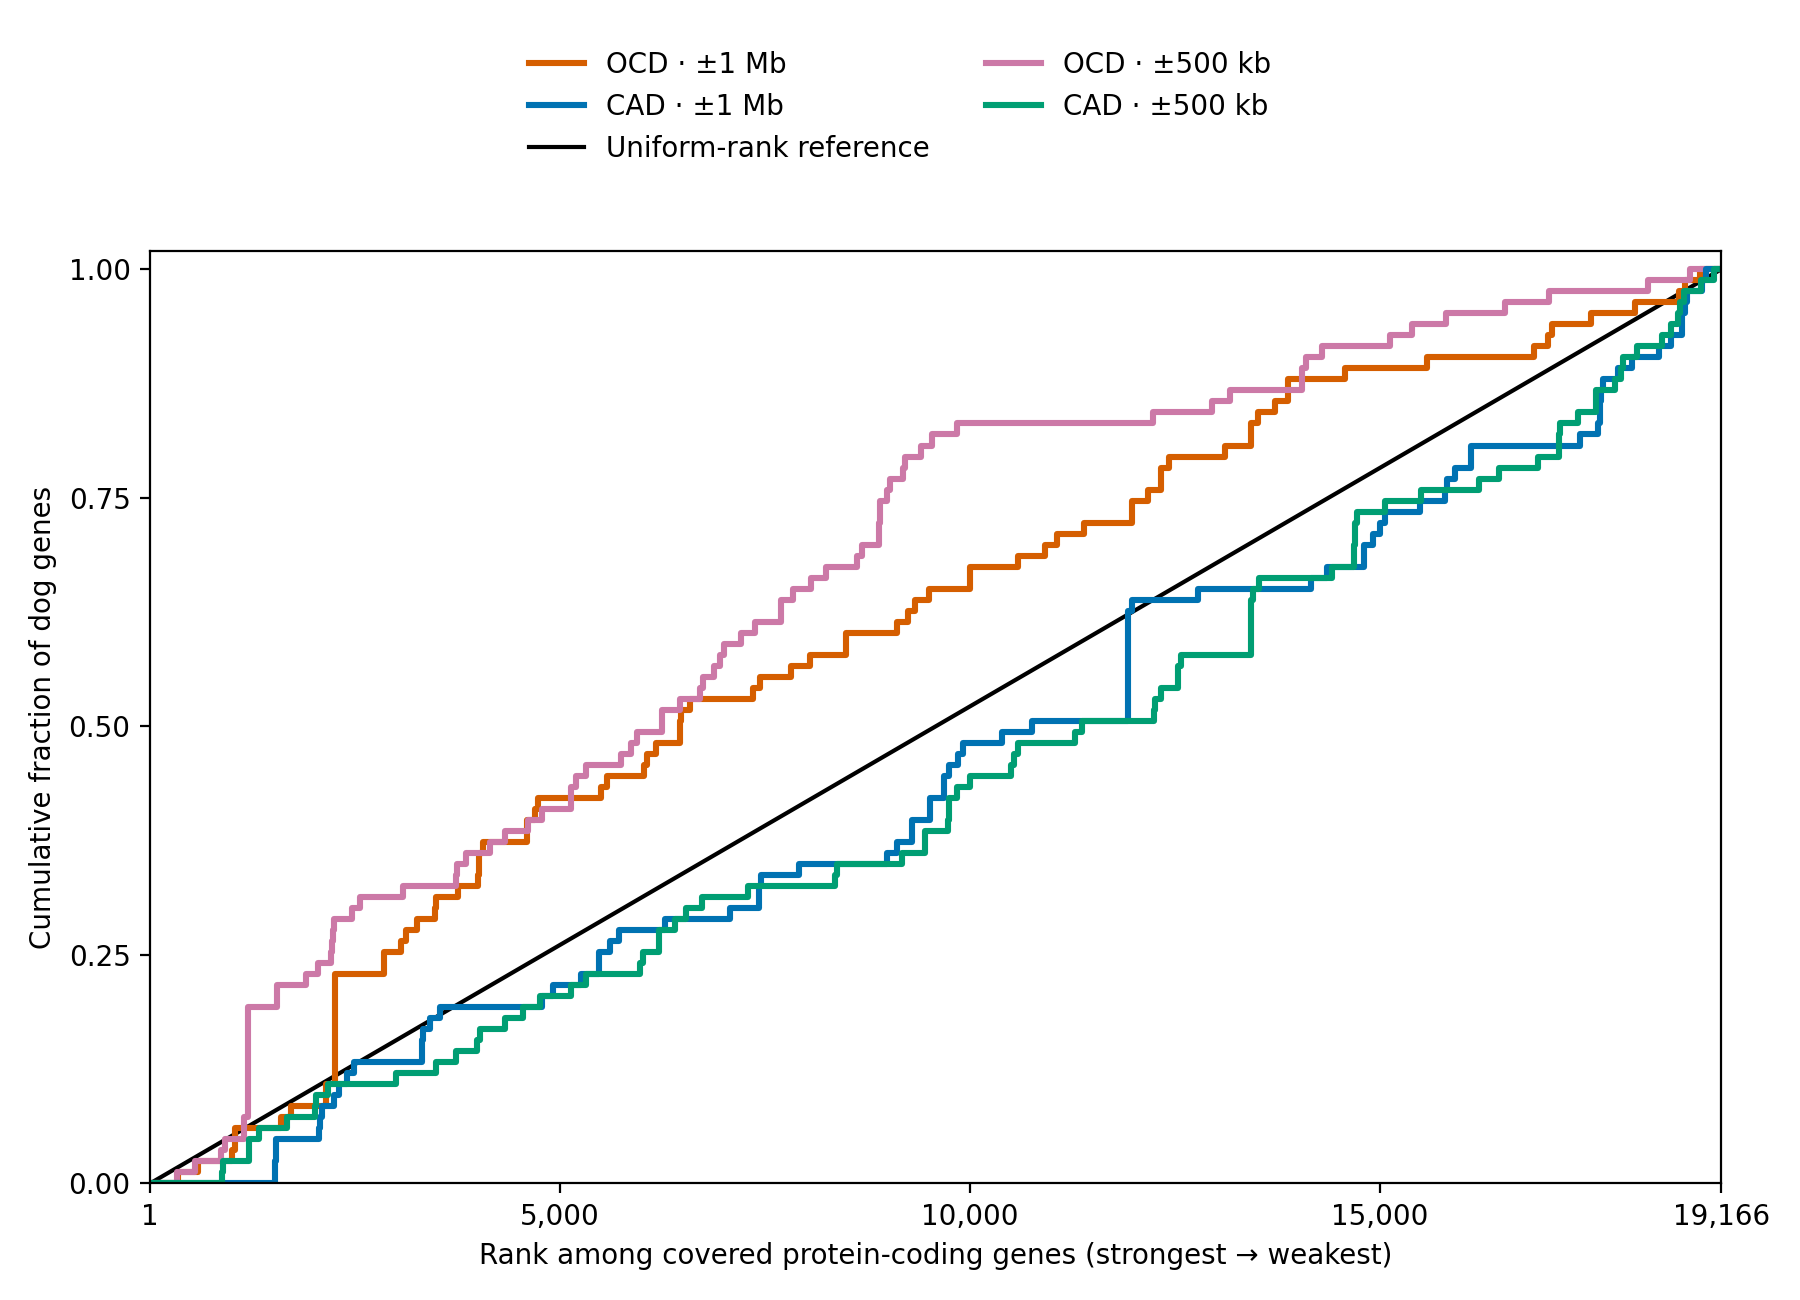

In [21]:
def plot_rank_overlay(ranked, comparison_trait='CAD',
                      filename='dog_gene_rank_overlay.png', ax=None):
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(9, 6.5))
    else:
        fig = ax.figure
    max_rank = 0
    dog_ids = None
    for label, trait, window, color in SERIES:
        if trait == 'CAD':
            trait = comparison_trait
            label = label.replace('CAD', comparison_trait)
        frame = ranked.loc[(ranked.trait == trait) & (ranked.window == window)]
        if frame.empty or frame.gene_id.duplicated().any():
            raise ValueError(f"Missing or duplicate {trait} {window} gene ranks")
        if not frame["rank"].between(1, len(frame)).all():
            raise ValueError(f"Invalid {trait} {window} gene ranks")
        dog = frame.loc[frame.dog]
        if len(dog) != DOG_N:
            raise ValueError(f"Expected {DOG_N} dog genes in {trait} {window}; got {len(dog)}")
        ids = set(dog.gene_id)
        if dog_ids is not None and ids != dog_ids:
            raise ValueError("Dog-gene IDs differ across traits or windows")
        dog_ids = ids
        ranks = np.sort(dog["rank"].to_numpy(dtype=float))
        fraction = np.arange(1, len(ranks) + 1) / len(ranks)
        ax.step(np.r_[1, ranks, len(frame)], np.r_[0, fraction, 1],
                where="post", linewidth=2.2, color=color, label=label)
        max_rank = max(max_rank, len(frame))

    ax.plot([1, max_rank], [0, 1], color="black", linewidth=1.5,
            label="Uniform-rank reference", zorder=1)
    ax.set_xlim(1, max_rank)
    ax.set_ylim(0, 1.02)
    ax.set_xticks([1, 5_000, 10_000, 15_000, max_rank])
    ax.set_xticklabels(["1", "5,000", "10,000", "15,000", f"{max_rank:,}"])
    ax.set_yticks(np.linspace(0, 1, 5))
    ax.set_xlabel("Rank among covered protein-coding genes (strongest → weakest)")
    ax.set_ylabel("Cumulative fraction of dog genes")
    if standalone:
        handles, labels = ax.get_legend_handles_labels()
        legend_order = [0, 2, 4, 1, 3]
        fig.legend([handles[i] for i in legend_order],
                   [labels[i] for i in legend_order],
                   loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.98),
                   frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 0.83))
        save_plot(fig, NOTEBOOK_OUT / filename, dpi=200)
        plt.close(fig)
    return ax


plot_rank_overlay(ranked)
display(Image(filename=str(NOTEBOOK_OUT / "dog_gene_rank_overlay.png"), width=900))

#### Circular-shift results

Recalculate 10,000 chromosome-wise circular shifts for the combined and
significant TOGA sets using the original seed and chromosome/SNP-count strata.
Cached results are reused only when scores, membership, seed, package versions
and the implementation checksum match. Empirical p-values are unadjusted.


In [22]:
permutation_rows = []
shift_cache_path = NOTEBOOK_OUT / 'dog_circular_shift_cache.json'
shift_cache = json.loads(shift_cache_path.read_text()) if shift_cache_path.exists() else {}
shift_method_sha = hashlib.sha256((ROOT / 'src/toga_gene_set.py').read_bytes()).hexdigest()
for trait, frame in trait_frames.items():
    if trait in PSYCHIATRIC_GWAS:
        saved_summary = psychiatric_summaries[trait]
    else:
        filename = 'summary.json' if trait == 'OCD' else 'cad_summary.json'
        saved_summary = json.loads((OUT / filename).read_text())
    for window, width, suffix in WINDOWS:
        columns = ['gene_id', 'chrom', 'tss', f'min_p{suffix}', f'n_snps{suffix}',
                   'dog', 'dog_significant', 'dog_suggestive']
        inputs = {'scores_and_membership_sha256': hashlib.sha256(pd.util.hash_pandas_object(
            frame[columns], index=False).to_numpy().tobytes()).hexdigest(),
            'seed': SEED, 'permutations': 10_000, 'implementation_sha256': shift_method_sha,
            'numpy': np.__version__, 'pandas': pd.__version__}
        key = f'{trait}_{window}'
        cached = shift_cache.get(key, {})
        if RUN_PERMUTATIONS or REBUILD_WINDOWS or cached.get('inputs') != inputs:
            print(f'{trait} {window}: running 10,000 TOGA circular shifts', flush=True)
            _, tests = rank_and_permute(frame, n=10_000,
                p_col=f'min_p{suffix}', count_col=f'n_snps{suffix}')
            shift_cache[key] = {'inputs': inputs, 'tests': tests}
        else:
            tests = cached['tests']
        assert tests['all']['n'] == DOG_N
        assert tests['significant']['n'] == DOG_COUNTS['significant']
        if trait in PSYCHIATRIC_GWAS:
            covered = frame[f'n_snps{suffix}'].gt(0)
            saved_summary['windows'][window] = {
                'width_each_side_bp': width, 'genes_covered': int(covered.sum()),
                'dog_covered': int((covered & frame.dog).sum()), 'tests': tests}
        for dog_set, test in tests.items():
            permutation_rows.append({'Trait': trait, 'Window': WINDOW_LABELS[window],
                'Dog set': 'combined' if dog_set == 'all' else dog_set,
                'Dog genes': test['n'], 'Mean rank': test['observed_mean_rank'],
                'Null mean rank': test['null_mean'],
                'Empirical p': test['empirical_one_sided_p'],
                'Permutations': test['permutations']})
    if trait in PSYCHIATRIC_GWAS:
        (NOTEBOOK_OUT / f'{trait.lower()}_summary.json').write_text(
            json.dumps(saved_summary, indent=2))
shift_cache_path.write_text(json.dumps(shift_cache, indent=2) + '\n')
permutation_results = pd.DataFrame(permutation_rows)
save_analysis_table(permutation_results, NOTEBOOK_OUT / 'circular_shift_results.csv', index=False)


def display_permutations(traits):
    table = permutation_results.loc[permutation_results.Trait.isin(traits)]
    display_export(table.style.format({'Mean rank': '{:.4f}',
        'Null mean rank': '{:.4f}', 'Empirical p': '{:.3g}'}).hide(axis='index'), 'circular_shifts_' + '_'.join(t.lower() for t in traits) + '_display', 'Circular-shift tests for the specified traits and significant/combined TOGA dog sets. The observed mean chromosome/SNP-count-stratified signal-rank percentile is compared with 10,000 within-chromosome shifts of gene-set membership. Smaller within-stratum rank percentile means stronger association. Empirical p is one-sided with a plus-one correction and no multiple-testing adjustment.')


display_permutations(['OCD', 'CAD'])

SCZ 1mb: running 10,000 TOGA circular shifts


SCZ 500kb: running 10,000 TOGA circular shifts


Trait,Window,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Permutations
OCD,±1 Mb,combined,83,0.4212,0.5028,0.0391,10000
OCD,±1 Mb,significant,43,0.3968,0.5035,0.0872,10000
OCD,±500 kb,combined,83,0.3548,0.5025,0.0003,10000
OCD,±500 kb,significant,43,0.3465,0.5040,0.0132,10000
CAD,±1 Mb,combined,83,0.5329,0.5027,0.721,10000
CAD,±1 Mb,significant,43,0.5695,0.5015,0.783,10000
CAD,±500 kb,combined,83,0.5851,0.5025,0.958,10000
CAD,±500 kb,significant,43,0.6451,0.5026,0.975,10000


#### OCD threshold counts

The earlier threshold-count analysis is included here for reference. Counts
use strict `P < 5×10⁻⁸` and `P < 5×10⁻⁶` cutoffs, and count genes rather than
independent loci. Overlapping windows can share the same lead SNP. The cell
also checks dog-gene minima, lead SNPs and SNP counts against the mapped OCD
SNP cache, following `count_ocd_threshold_genes.py`.

In [23]:
GENOME_WIDE = 5e-8
RELAXED = 5e-6
THRESHOLD_WINDOWS = (
    ('1mb', 1_000_000, 'min_p', 'n_snps', 'lead_snp', 'lead_pos_grch38'),
    ('500kb', 500_000, 'min_p_500kb', 'n_snps_500kb', 'lead_snp_500kb', 'lead_pos_grch38_500kb'))



def classify(p):
    if p < GENOME_WIDE:
        return "genome_wide"
    if p < RELAXED:
        return "additional_at_5e-6"
    return "neither"


def count_ocd_threshold_genes(genes):
    dog = genes.loc[genes.dog].copy()
    assert len(dog) == DOG_N
    assert dog.dog_significant.sum() == DOG_COUNTS["significant"] and dog.dog_suggestive.sum() == DOG_COUNTS["suggestive"]
    assert (dog.dog_significant ^ dog.dog_suggestive).all()
    assert dog[["n_snps", "n_snps_500kb"]].gt(0).all().all()

    rows = []
    for chrom, chrom_genes in dog.groupby("chrom"):
        variants = pd.read_parquet(MAPPED / f"chr{chrom}.parquet")
        positions = variants.pos.to_numpy()
        pvalues = variants.p.to_numpy()
        snps = variants.snp.to_numpy()
        assert np.all(positions[:-1] <= positions[1:])
        for gene in chrom_genes.itertuples(index=False):
            for window, width, p_col, n_col, snp_col, pos_col in THRESHOLD_WINDOWS:
                left = max(1, gene.tss - width)
                right = gene.tss + width
                lo = np.searchsorted(positions, left, side="left")
                hi = np.searchsorted(positions, right, side="right")
                assert hi - lo == getattr(gene, n_col)
                lead = lo + np.argmin(pvalues[lo:hi])
                assert pvalues[lead] == getattr(gene, p_col)
                assert int(positions[lead]) == int(getattr(gene, pos_col))
                assert snps[lead] == getattr(gene, snp_col)
                rows.append({
                    "window": window,
                    "dog_set": "significant" if gene.dog_significant else "suggestive",
                    "gene_id": gene.gene_id,
                    "symbol": gene.symbol,
                    "chrom": chrom,
                    "tss_grch38": gene.tss,
                    "min_p": pvalues[lead],
                    "lead_snp": snps[lead],
                    "lead_pos_grch38": int(positions[lead]),
                    "n_snps": hi - lo,
                    "threshold_category": classify(pvalues[lead]),
                })

    result = pd.DataFrame(rows).sort_values(["window", "min_p", "symbol"])
    assert len(result) == 2 * DOG_N
    save_analysis_table(result, NOTEBOOK_OUT / 'ocd_threshold_dog_genes.csv', index=False)
    summary = (
        result.groupby(["window", "dog_set", "threshold_category"])
        .size().unstack(fill_value=0)
        .reindex(columns=["genome_wide", "additional_at_5e-6", "neither"], fill_value=0)
    )
    summary["total_below_5e-6"] = summary.genome_wide + summary["additional_at_5e-6"]
    summary["genes_tested"] = summary[["genome_wide", "additional_at_5e-6", "neither"]].sum(axis=1)
    summary = summary.reset_index()
    combined = summary.groupby("window", as_index=False)[
        ["genome_wide", "additional_at_5e-6", "neither", "total_below_5e-6", "genes_tested"]
    ].sum()
    combined.insert(1, "dog_set", "combined")
    summary = pd.concat([summary, combined], ignore_index=True).sort_values(["window", "dog_set"])
    save_analysis_table(summary, NOTEBOOK_OUT / 'ocd_threshold_counts.csv', index=False)
    return summary, result

In [24]:
threshold_counts, threshold_genes = count_ocd_threshold_genes(ocd)
display_export(threshold_counts.style.hide(axis='index'), 'ocd_threshold_counts_display', 'Counts of TOGA dog genes by OCD association threshold and TSS window. genome_wide is p < 5e-8; additional_at_5e-6 is 5e-8 ≤ p < 5e-6; neither is p ≥ 5e-6. total_below_5e-6 includes both stronger categories. Combined counts sum significant and suggestive subsets.')
display_export(threshold_genes.loc[threshold_genes.min_p.lt(RELAXED),
    ['window', 'dog_set', 'symbol', 'min_p', 'lead_snp']]
    .style.format({'min_p': '{:.3g}'}).hide(axis='index'), 'ocd_threshold_hits_display', 'TOGA dog genes with minimum OCD window p-value < 5e-6, listing the window, dog subset, symbol, minimum p-value and lead SNP. These are window minimum p-values without adjustment for the number of SNPs.')

/Users/runner/work/crossbow/crossbow/arrow/cpp/src/arrow/util/cpu_info.cc:239: IOError: sysctlbyname failed for 'hw.l1dcachesize'. Detail: [errno 1] Operation not permitted
/Users/runner/work/crossbow/crossbow/arrow/cpp/src/arrow/util/cpu_info.cc:239: IOError: sysctlbyname failed for 'hw.l2cachesize'. Detail: [errno 1] Operation not permitted
/Users/runner/work/crossbow/crossbow/arrow/cpp/src/arrow/util/cpu_info.cc:239: IOError: sysctlbyname failed for 'hw.l3cachesize'. Detail: [errno 1] Operation not permitted
/Users/runner/work/crossbow/crossbow/arrow/cpp/src/arrow/util/cpu_info.cc:239: IOError: sysctlbyname failed for 'hw.optional.neon'. Detail: [errno 1] Operation not permitted


window,dog_set,genome_wide,additional_at_5e-6,neither,total_below_5e-6,genes_tested
1mb,combined,0,5,78,5,83
1mb,significant,0,3,40,3,43
1mb,suggestive,0,2,38,2,40
500kb,combined,0,2,81,2,83
500kb,significant,0,1,42,1,43
500kb,suggestive,0,1,39,1,40


window,dog_set,symbol,min_p,lead_snp
1mb,significant,RNF144A,1.43e-06,rs112121472
1mb,suggestive,RORB,2.43e-06,rs10869402
1mb,significant,NTRK2,3.99e-06,rs2013444
1mb,significant,CDH8,4.28e-06,rs62048348
1mb,suggestive,SLIT2,4.32e-06,rs4697630
500kb,suggestive,RORB,2.43e-06,rs10869402
500kb,significant,CDH8,4.28e-06,rs62048348


#### Additional plots from the original scripts (optional)

Set `SHOW_ADDITIONAL_PLOTS = True` to regenerate the original 12-panel histograms,
four-panel p-value CDFs and four-panel rank CDFs. The requested single-panel
four-line CDF above is always generated.

In [25]:
def plot_distributions(d, path, cad=None, comparison_trait='CAD'):
    windows=(('±1 Mb','min_p','n_snps'),('±500 kb','min_p_500kb','n_snps_500kb'))
    groups=(('All covered protein-coding genes',None,'#888888'),
            ('Dog GWAS significant','dog_significant','#d55e00'),
            ('Dog GWAS suggestive','dog_suggestive','#0072b2'))
    datasets=[('OCD',d)] + ([(comparison_trait,cad)] if cad is not None else [])
    fig,axes=plt.subplots(2*len(datasets),3,figsize=(14.5,4*len(datasets)),sharex=True,sharey=False)
    bins=np.linspace(0,PLOT_MAX_LOGP,31)
    for trait,frame in datasets:
        trait_row=0 if trait=='OCD' else 2
        trait_max_density=0.
        for offset,(distance,p_col,count_col) in enumerate(windows):
            for col,(label,mask_col,color) in enumerate(groups):
                mask=frame[count_col].gt(0)
                if mask_col is not None:
                    mask &= frame[mask_col]
                x=-np.log10(np.maximum(frame.loc[mask,p_col].to_numpy(dtype=float),np.nextafter(0,1)))
                # Pool stronger signals in the final bin so every panel has
                # the same 0–15 x-axis without silently dropping those genes.
                x=np.minimum(x,PLOT_MAX_LOGP)
                ax=axes[trait_row+offset,col]
                heights,_,_=ax.hist(x,bins=bins,density=True,histtype='step',linewidth=2,color=color)
                trait_max_density=max(trait_max_density,float(heights.max()))
                ax.set_title(f'{trait} {distance} · {label}\n(n={len(x):,})')
                ax.set_xlim(0,PLOT_MAX_LOGP)
                ax.set_xticks([0,5,10,PLOT_MAX_LOGP])
                ax.set_xticklabels(['0','5','10',f'≥{PLOT_MAX_LOGP}'])
                ax.tick_params(axis='x',labelbottom=True)
        for ax in axes[trait_row:trait_row+2].flat:
            ax.set_ylim(0,trait_max_density*1.08)
    fig.supxlabel('−log₁₀(minimum GWAS p-value near TSS)')
    fig.supylabel('Gene density')
    fig.tight_layout(rect=(0.01,0.02,0.96,1));save_plot(fig,path,dpi=200);plt.close(fig)

In [26]:
PLOT_WINDOWS = (('±1 Mb', 'min_p', 'n_snps'),
                ('±500 kb', 'min_p_500kb', 'n_snps_500kb'))
PLOT_GROUPS = (('All dog genes', 'dog', '#4d4d4d'),
               ('Dog GWAS significant', 'dog_significant', '#d55e00'),
               ('Dog GWAS suggestive', 'dog_suggestive', '#0072b2'))



def plot_p_cdfs(data, filename='dog_gene_p_cdfs.png'):
    for frame in data.values():
        assert frame.dog.sum() == DOG_N
        assert frame.dog_significant.sum() == DOG_COUNTS["significant"] and frame.dog_suggestive.sum() == DOG_COUNTS["suggestive"]
        assert (frame.loc[frame.dog, "dog_significant"] ^
                frame.loc[frame.dog, "dog_suggestive"]).all()

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
    x_min = -14
    for row, (trait, frame) in enumerate(data.items()):
        for col, (window, p_col, count_col) in enumerate(PLOT_WINDOWS):
            ax = axes[row, col]
            for label, mask_col, color in PLOT_GROUPS:
                group = frame.loc[frame[mask_col] & frame[count_col].gt(0), p_col]
                values = group.to_numpy(dtype=float)
                if not len(values) or not np.isfinite(values).all() or not ((values > 0) & (values <= 1)).all():
                    raise ValueError(f"Invalid or missing {trait} {window} p-values for {label}")
                # At cutoff 10**x, the curve equals the fraction with a
                # window minimum p-value no greater than that cutoff.
                logp = np.sort(np.log10(values))
                y = np.arange(1, len(logp) + 1) / len(logp)
                ax.step(np.r_[x_min, logp, 0], np.r_[0, y, 1],
                        where="post", color=color, linewidth=2,
                        label=f"{label} (n={len(logp)})")
            ax.set_title(f"{trait} · {window}")
            ax.set_xlim(x_min, 0)
            ax.set_ylim(0, 1.02)
            ax.set_xticks(np.arange(-14, 1, 2))
            ax.set_yticks(np.linspace(0, 1, 5))
            ax.tick_params(axis="x", labelbottom=True)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3,
               bbox_to_anchor=(0.5, 0.98), frameon=False)
    fig.supxlabel("log₁₀(P cutoff)")
    fig.supylabel("Cumulative fraction of dog genes")
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.92))
    save_plot(fig, NOTEBOOK_OUT / filename, dpi=200)
    plt.close(fig)

In [27]:
RANK_PLOT_WINDOWS = (('1mb', '±1 Mb'), ('500kb', '±500 kb'))
RANK_PLOT_GROUPS = (('All dog genes', 'dog', '#4d4d4d', DOG_N),
                    ('Dog GWAS significant', 'dog_significant', '#d55e00', DOG_COUNTS['significant']),
                    ('Dog GWAS suggestive', 'dog_suggestive', '#0072b2', DOG_COUNTS['suggestive']))



def plot_rank_cdfs(ranked, traits=('OCD', 'CAD'), filename='dog_gene_rank_cdfs.png'):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
    max_rank = 0
    for row, trait in enumerate(traits):
        for col, (window, title) in enumerate(RANK_PLOT_WINDOWS):
            frame = ranked.loc[(ranked.trait == trait) & (ranked.window == window)]
            if frame.empty or frame.gene_id.duplicated().any():
                raise ValueError(f"Missing or duplicate {trait} {window} gene ranks")
            if not frame["rank"].between(1, len(frame)).all():
                raise ValueError(f"Invalid {trait} {window} gene ranks")
            if not frame.dog.eq(frame.dog_significant | frame.dog_suggestive).all():
                raise ValueError(f"Inconsistent {trait} {window} dog labels")
            if (frame.dog_significant & frame.dog_suggestive).any():
                raise ValueError(f"Overlapping {trait} {window} dog sets")
            max_rank = max(max_rank, len(frame))
            ax = axes[row, col]
            for label, mask_col, color, expected_n in RANK_PLOT_GROUPS:
                ranks = np.sort(frame.loc[frame[mask_col], "rank"].to_numpy(dtype=float))
                if len(ranks) != expected_n:
                    raise ValueError(f"Expected {expected_n} {label} in {trait} {window}; got {len(ranks)}")
                fraction = np.arange(1, len(ranks) + 1) / len(ranks)
                ax.step(np.r_[1, ranks, len(frame)], np.r_[0, fraction, 1],
                        where="post", color=color, linewidth=2,
                        label=f"{label} (n={len(ranks)})")
            ax.set_title(f"{trait} · {title}")
            ax.set_ylim(0, 1.02)
            ax.set_yticks(np.linspace(0, 1, 5))
            ax.tick_params(axis="x", labelbottom=True)

    for ax in axes.flat:
        ax.set_xlim(1, max_rank)
        ax.set_xticks([1, 5_000, 10_000, 15_000, max_rank])
        ax.set_xticklabels(["1", "5,000", "10,000", "15,000", f"{max_rank:,}"])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3,
               bbox_to_anchor=(0.5, 0.98), frameon=False)
    fig.supxlabel("Rank among covered protein-coding genes (strongest → weakest)")
    fig.supylabel("Cumulative fraction of dog genes")
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.92))
    save_plot(fig, NOTEBOOK_OUT / filename, dpi=200)
    plt.close(fig)

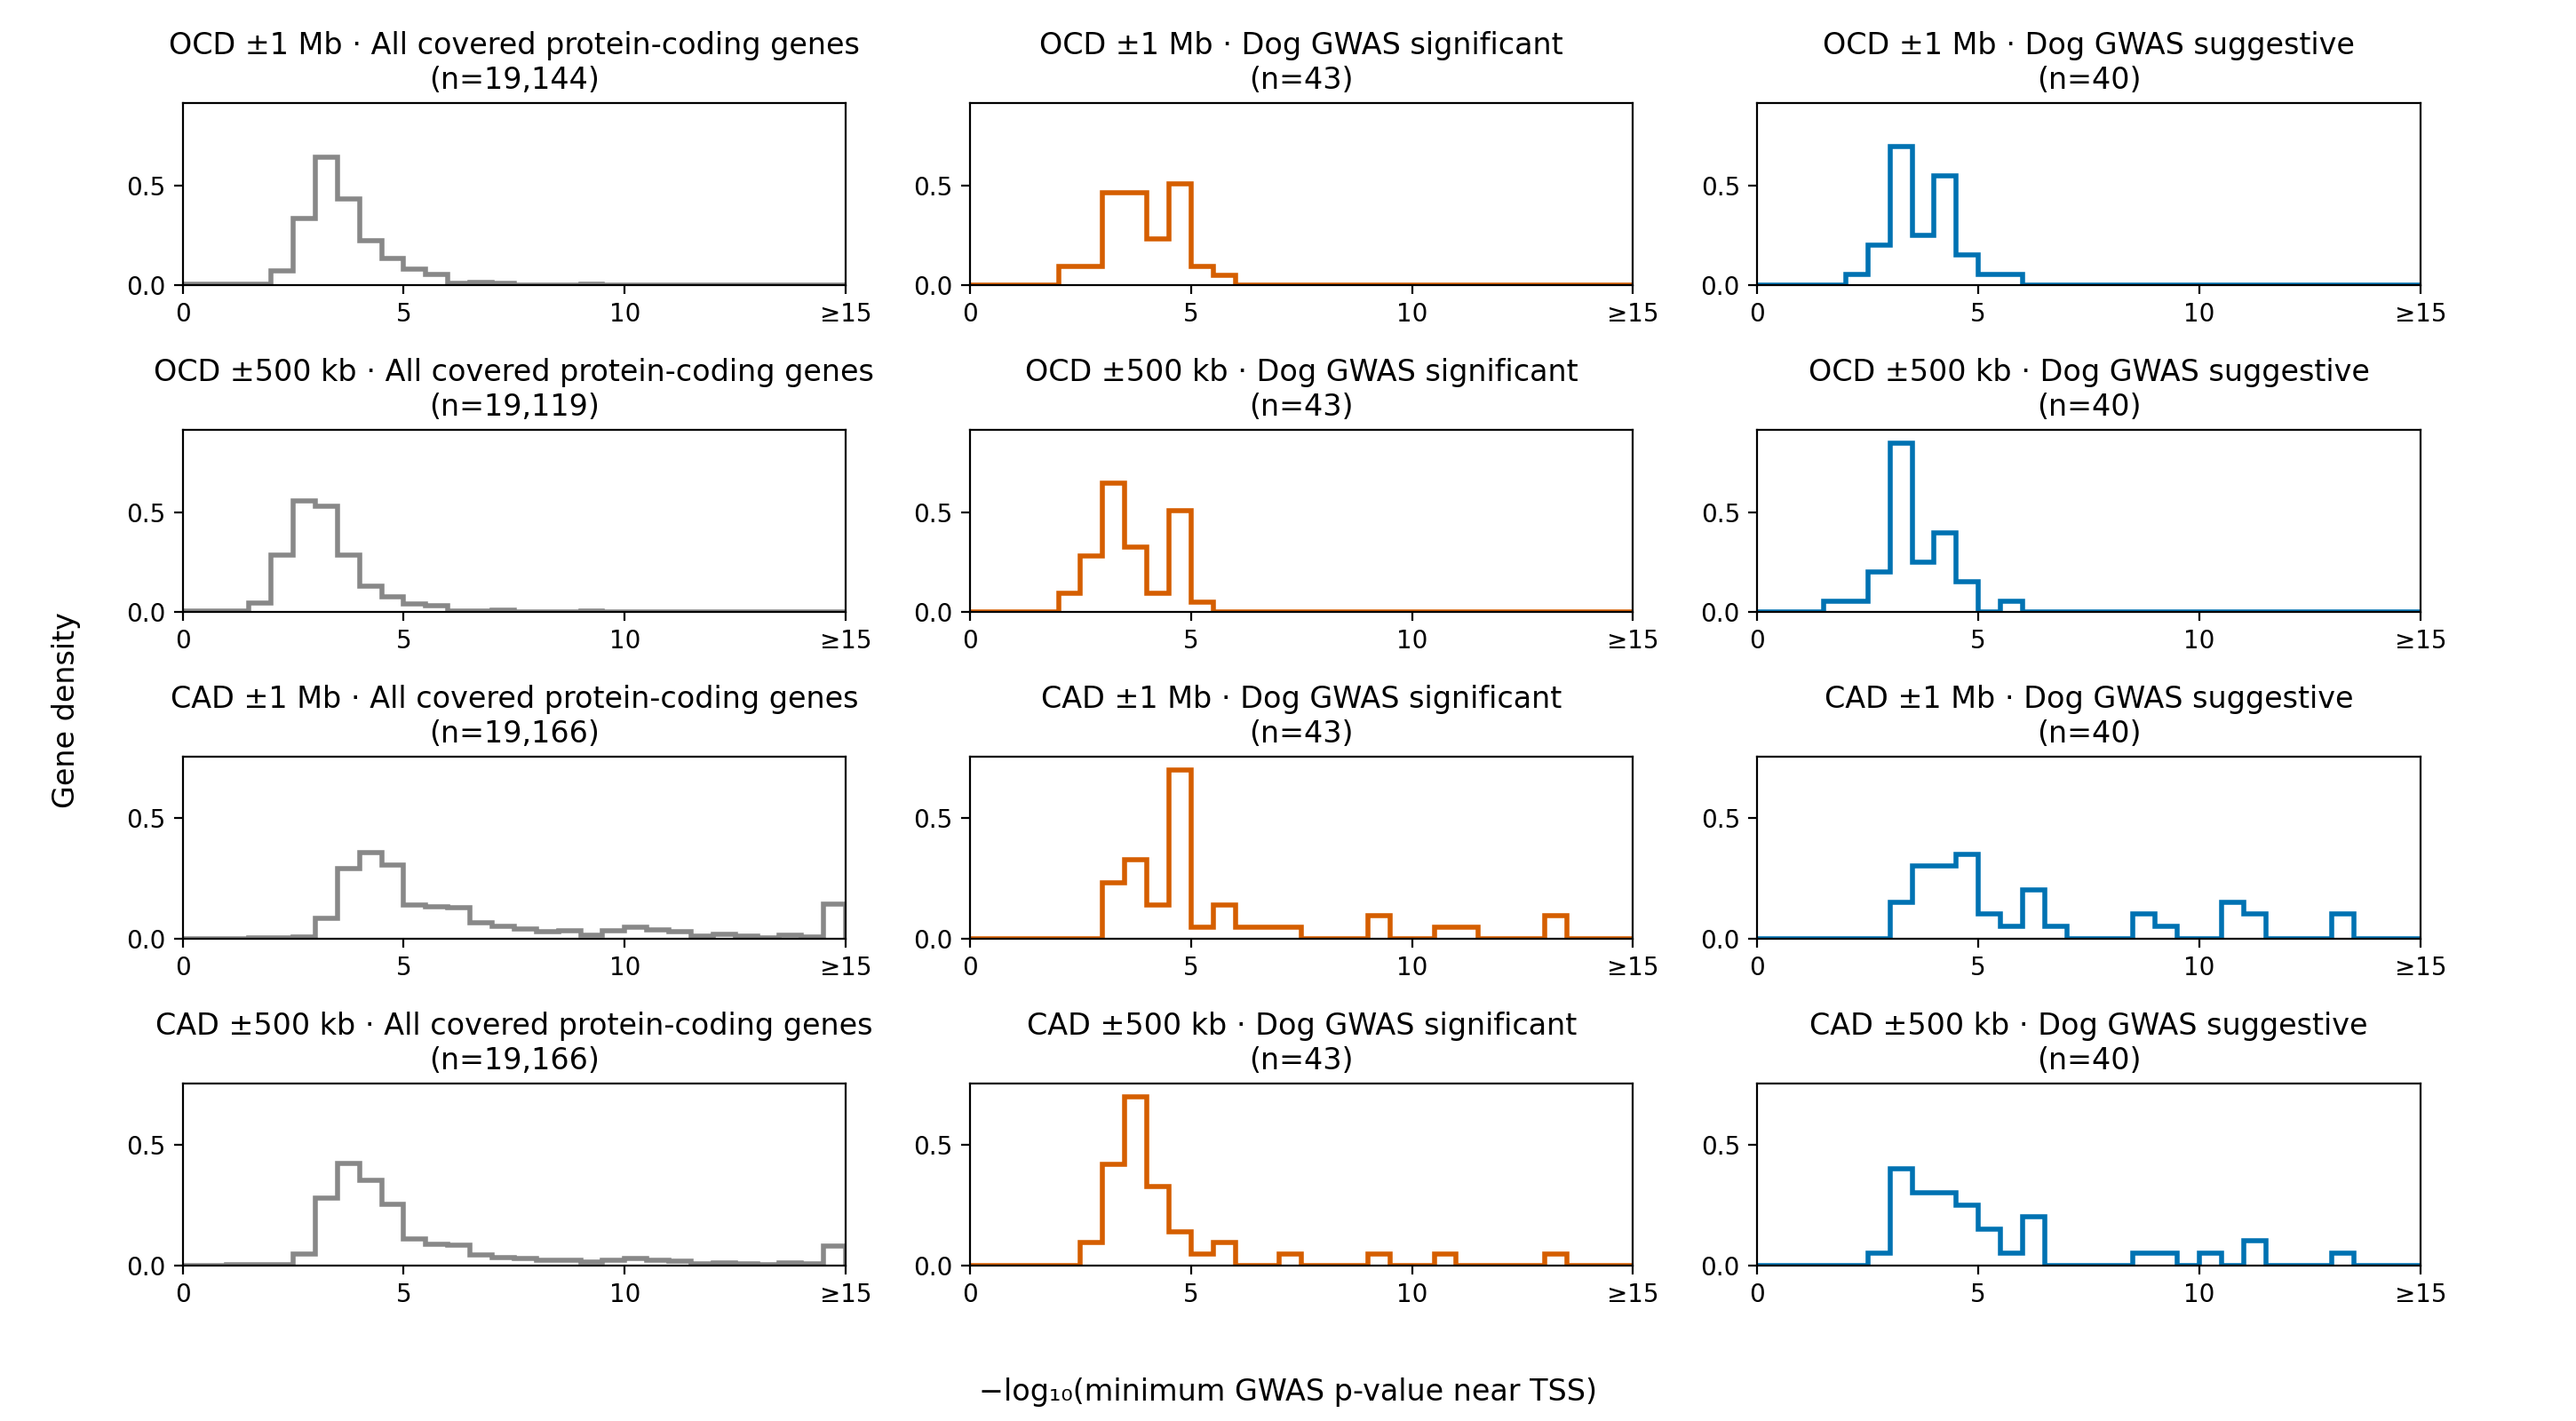

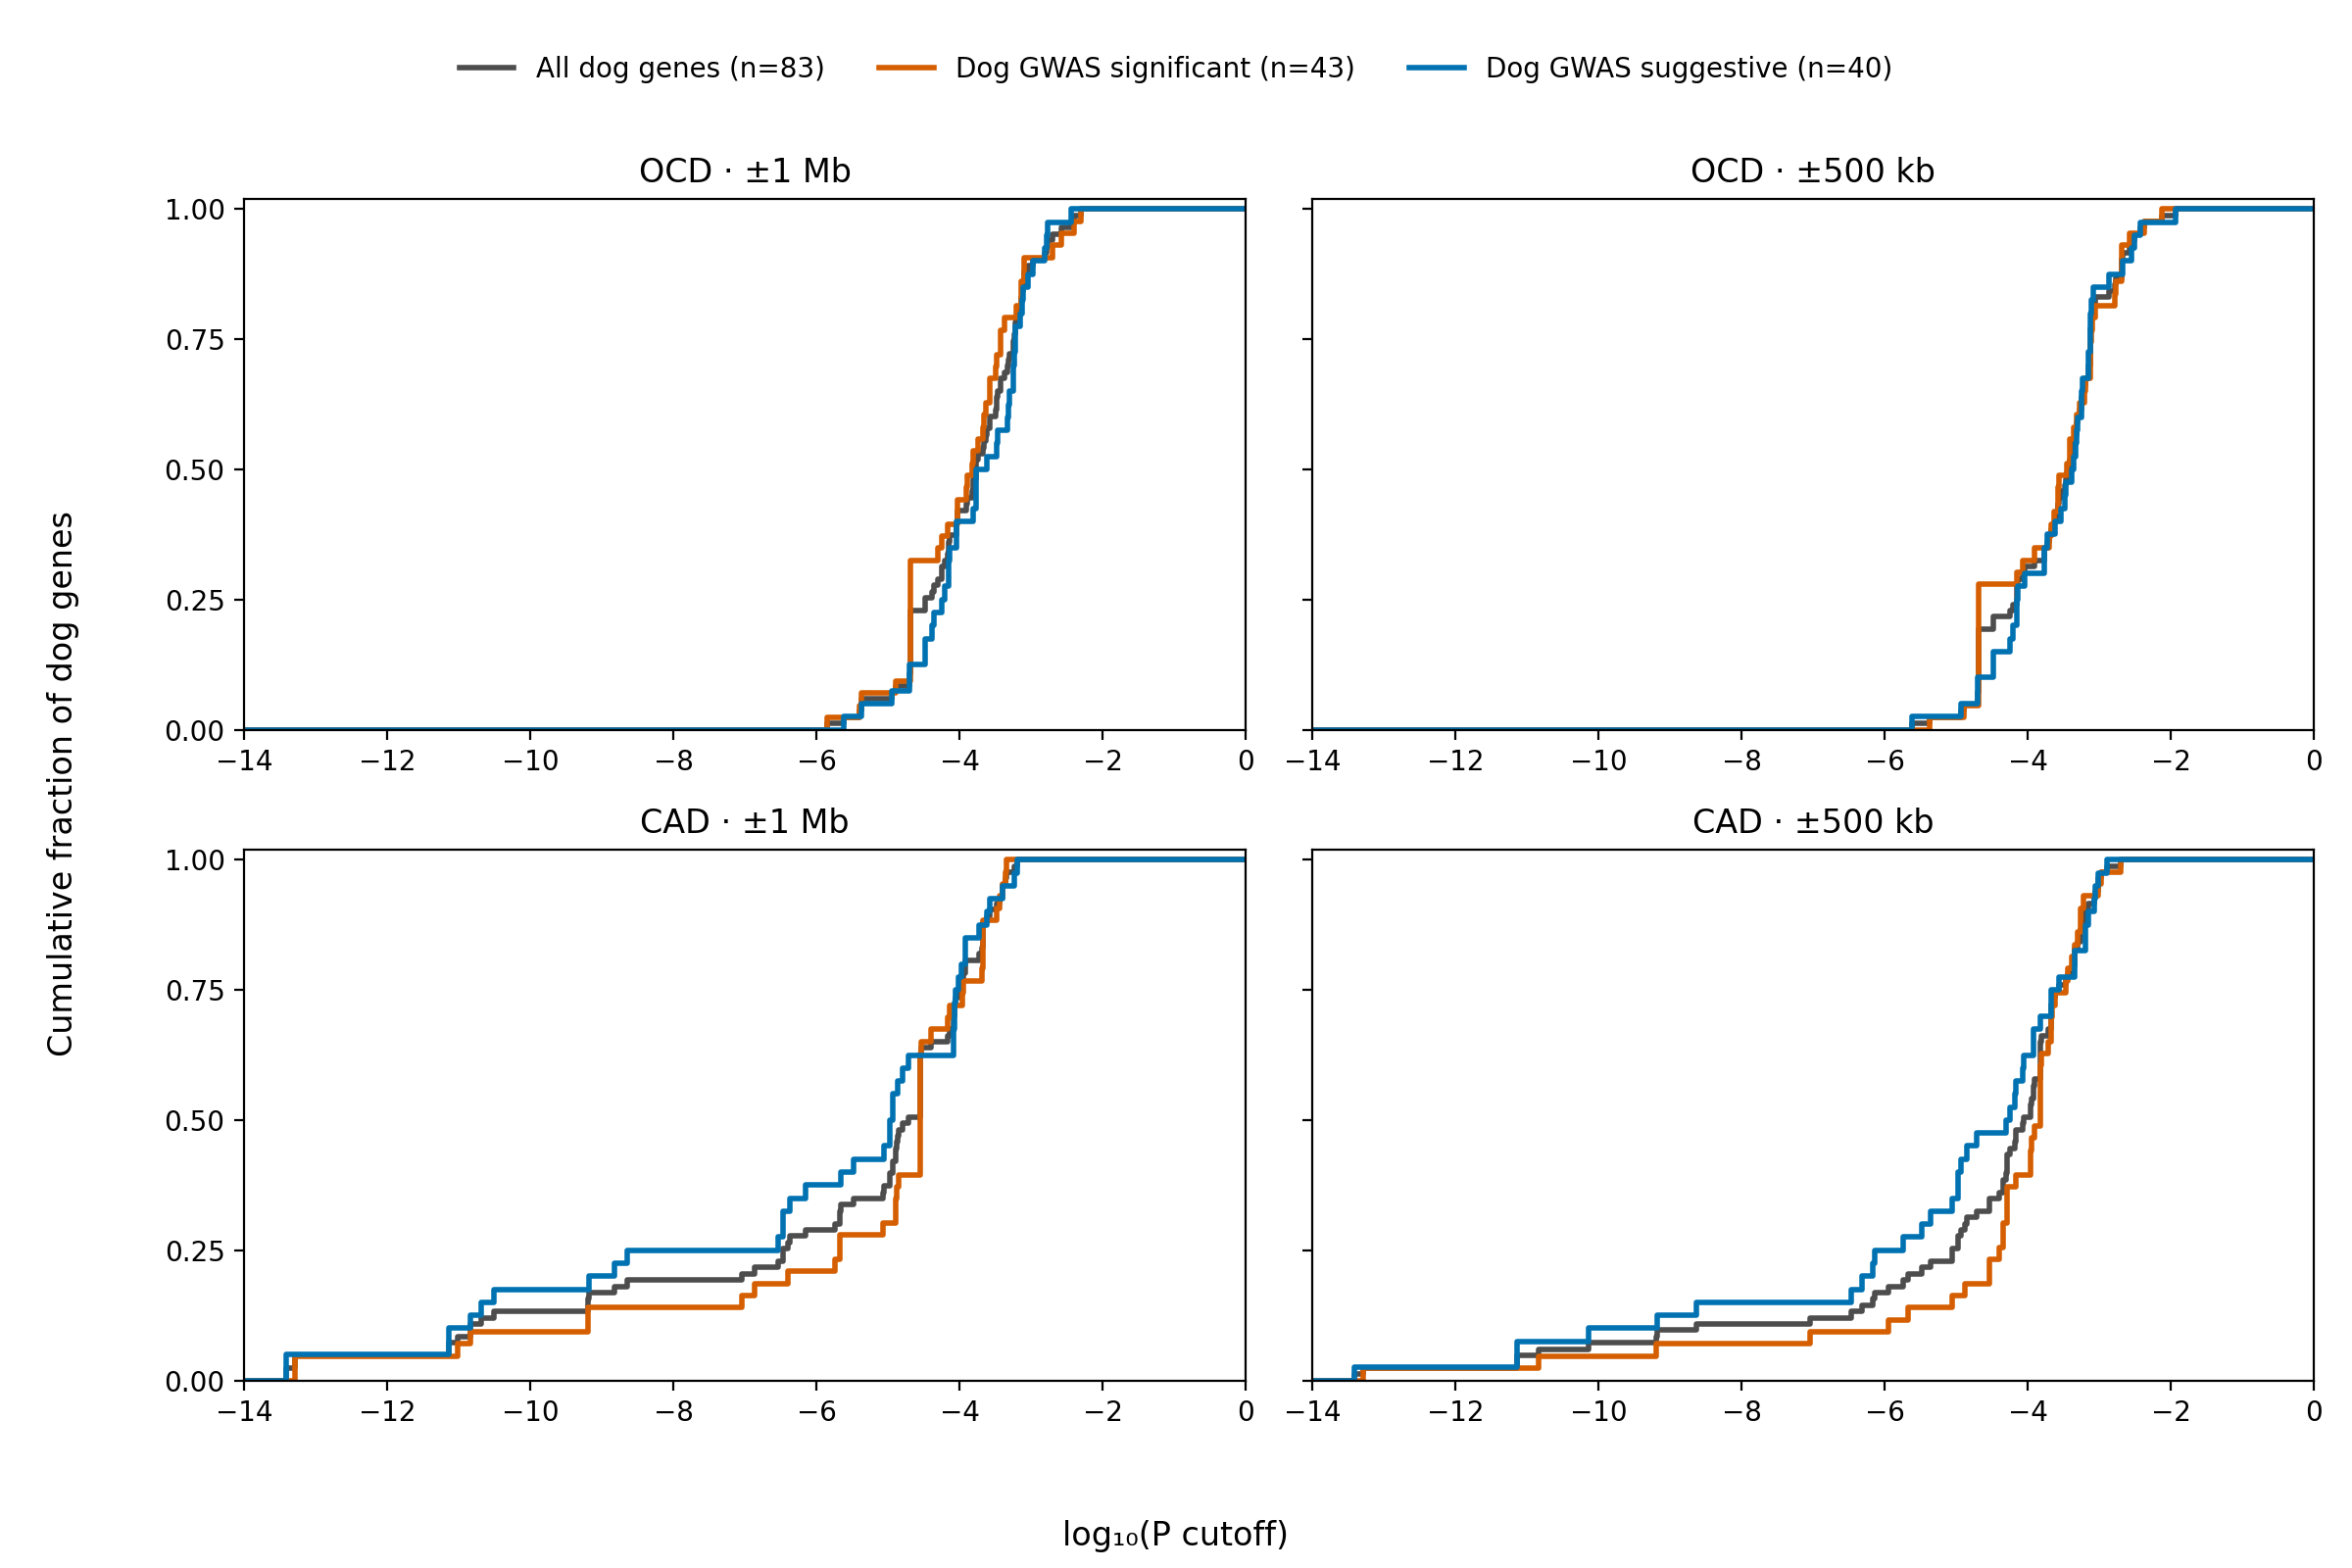

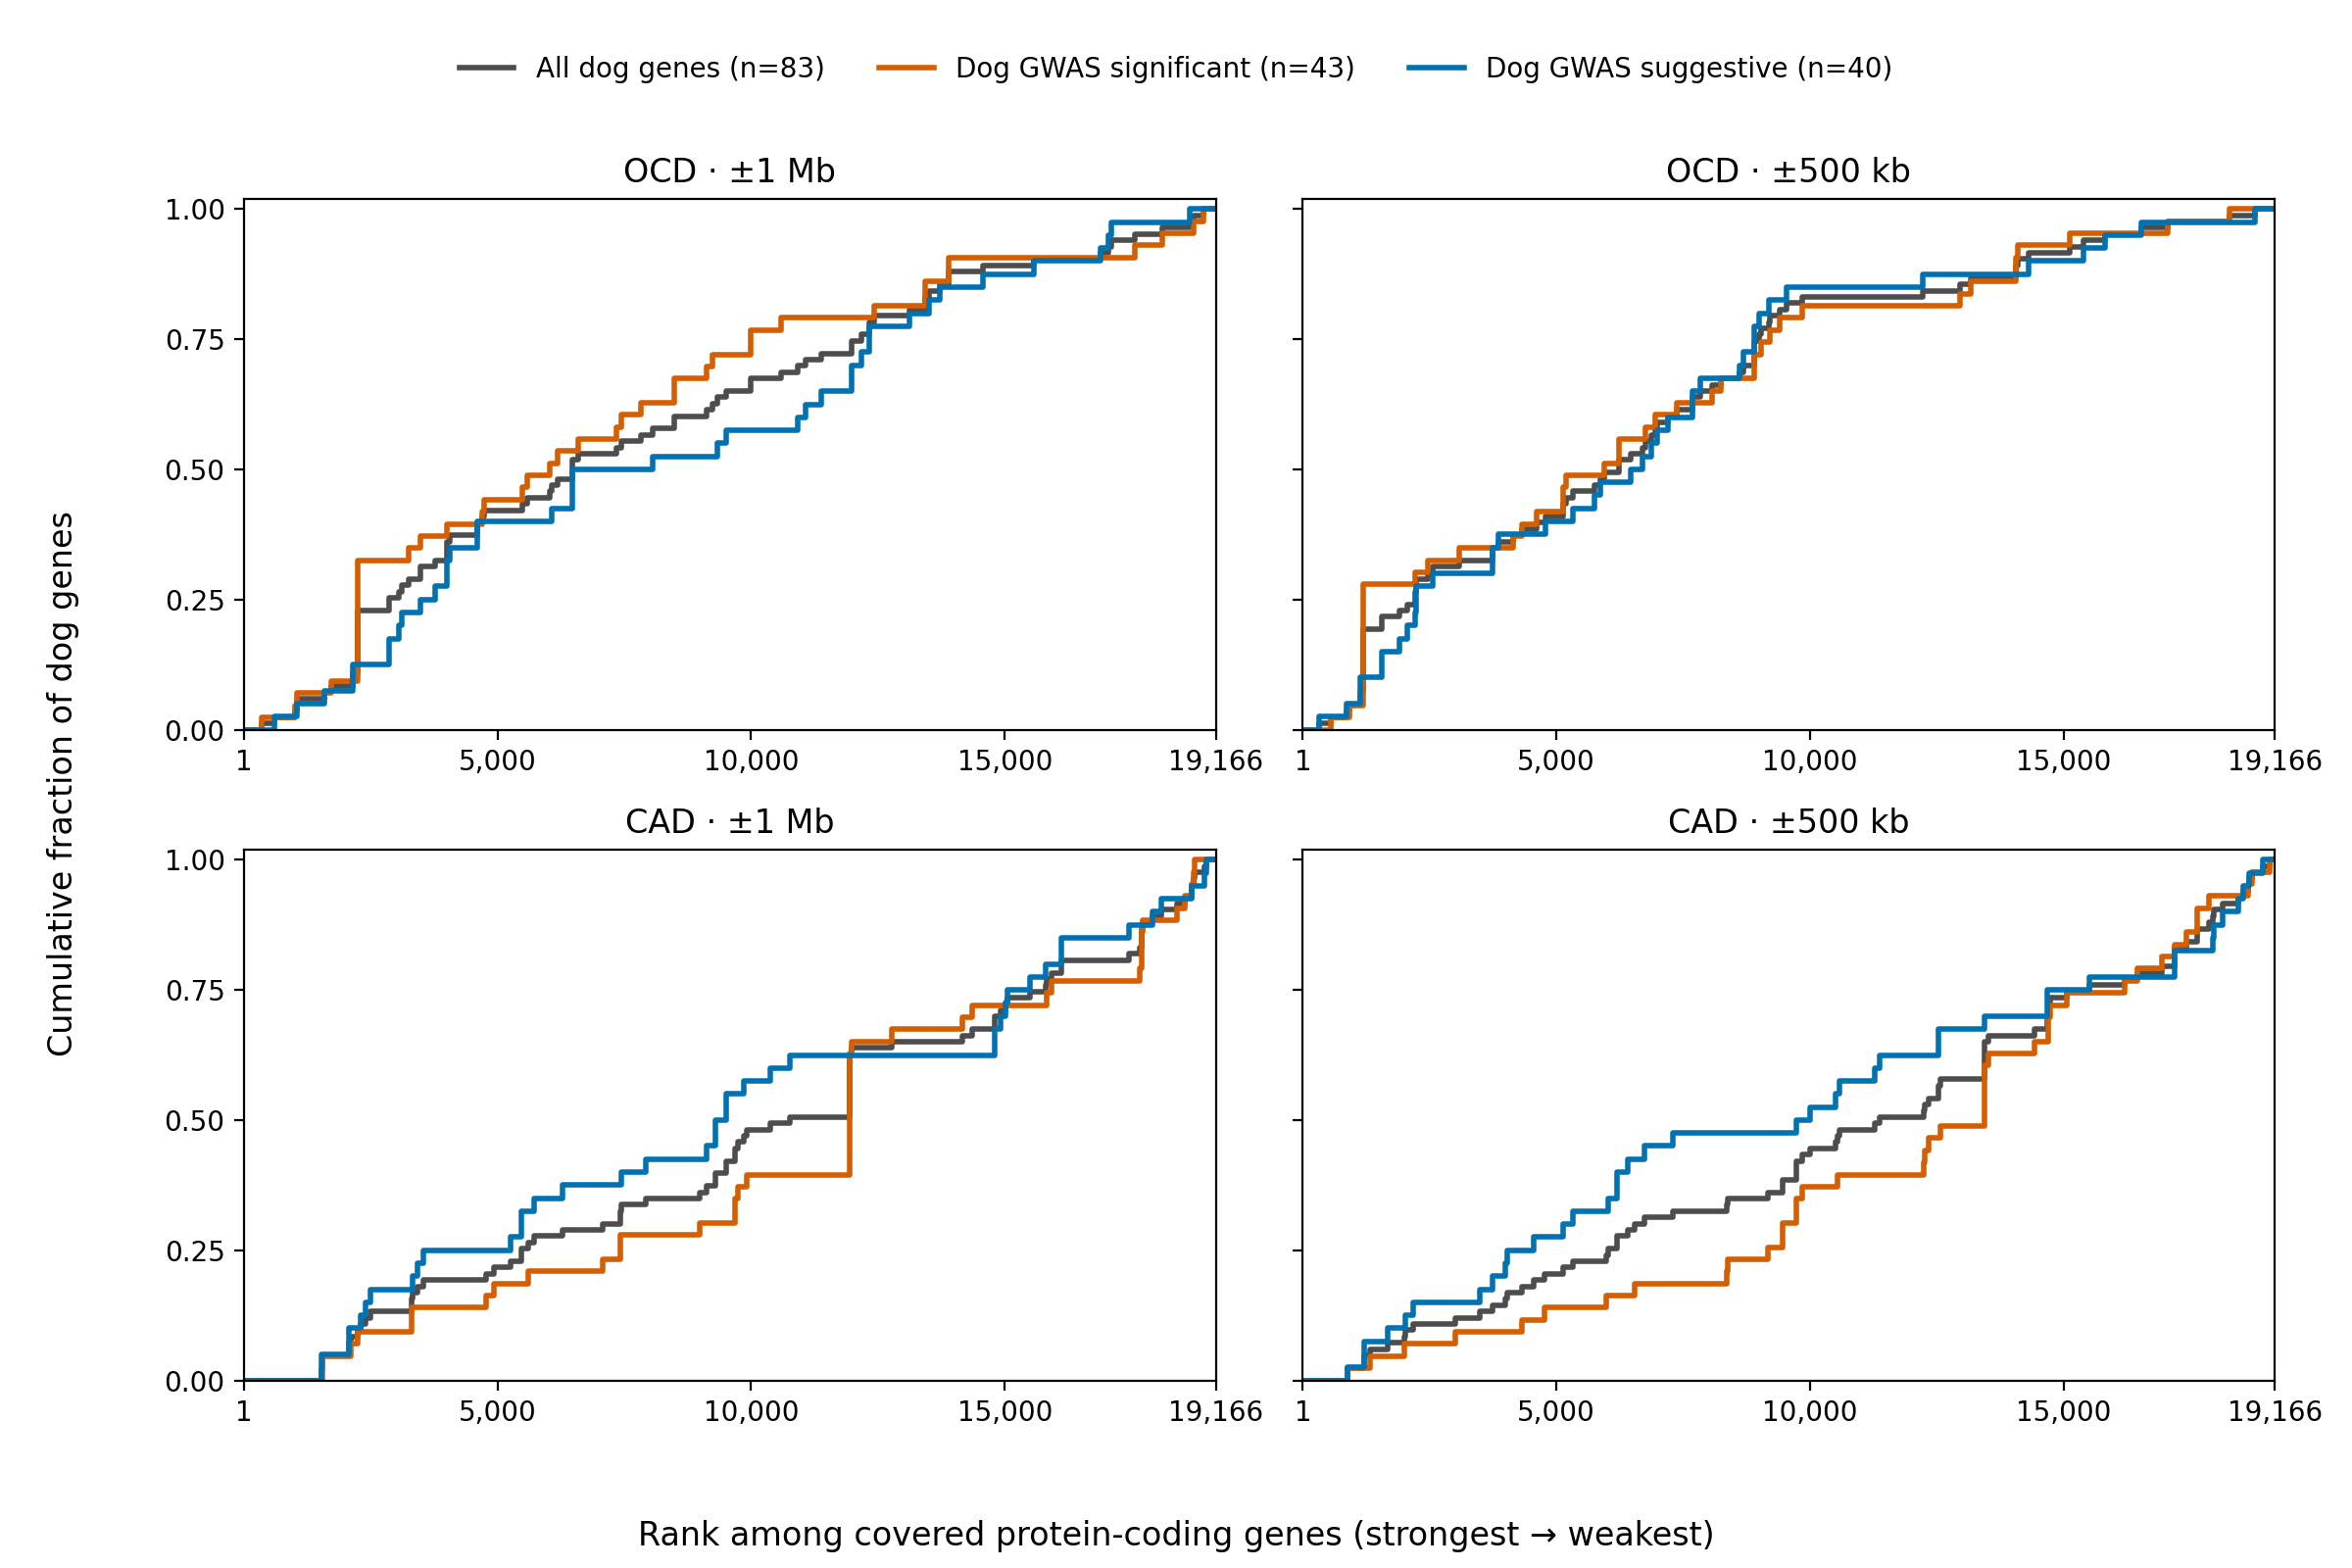

In [28]:
def show_additional_comparison(trait):
    if not SHOW_ADDITIONAL_PLOTS:
        return
    suffix = '' if trait == 'CAD' else f'_{trait.lower()}'
    distribution_file = f'ocd_p_distributions{suffix}.png'
    p_cdf_file = f'dog_gene_p_cdfs{suffix}.png'
    rank_cdf_file = f'dog_gene_rank_cdfs{suffix}.png'
    plot_distributions(ocd, NOTEBOOK_OUT / distribution_file,
                       cad=trait_frames[trait], comparison_trait=trait)
    plot_p_cdfs({'OCD': ocd, trait: trait_frames[trait]}, filename=p_cdf_file)
    plot_rank_cdfs(ranked, traits=('OCD', trait), filename=rank_cdf_file)
    for filename in (distribution_file, p_cdf_file, rank_cdf_file):
        display(Image(filename=str(NOTEBOOK_OUT / filename), width=1000))


show_additional_comparison('CAD')

#### Interpretation

The dog-set Holm family contains the six OCD tests. The five control traits
are reported with unadjusted p-values. Circular-shift p-values remain unadjusted.
Mann–Whitney tests do not account for overlapping windows, local LD, SNP-count
differences or clustering; circular shifts account for chromosome/SNP-count
strata and gene-order patterns. Different significance between traits does
not establish a difference in enrichment. The shared human OCD input in ST6
selection makes these findings exploratory.


### B. OCD vs. bipolar disorder (BIP)

Repeat the CAD analysis with the same 83 TOGA dog orthologs, non-dog background,
two window widths, three dog sets, one-sided asymptotic Mann–Whitney tests,
rank CDF and 10,000 chromosome-wise circular shifts. Holm correction covers only the six OCD tests; this control trait reports raw p-values. The OCD results below repeat section A.

#### Mann–Whitney tables

In [29]:
display_mann_whitney('OCD')
display_mann_whitney('BIP')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
±1 Mb,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
±1 Mb,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
±500 kb,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
±500 kb,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
±500 kb,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06


Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,060","403,962.0",0.4929,0.564,—
±1 Mb,suggestive,40,"19,060","402,364.5",0.5278,0.272,—
±1 Mb,combined,83,"19,060","806,326.5",0.5097,0.38,—
±500 kb,significant,43,"19,036","423,042.5",0.5168,0.351,—
±500 kb,suggestive,40,"19,036","400,717.5",0.5263,0.283,—
±500 kb,combined,83,"19,036","823,760.0",0.5214,0.25,—


#### Cumulative gene-rank distributions: four lines plus diagonal

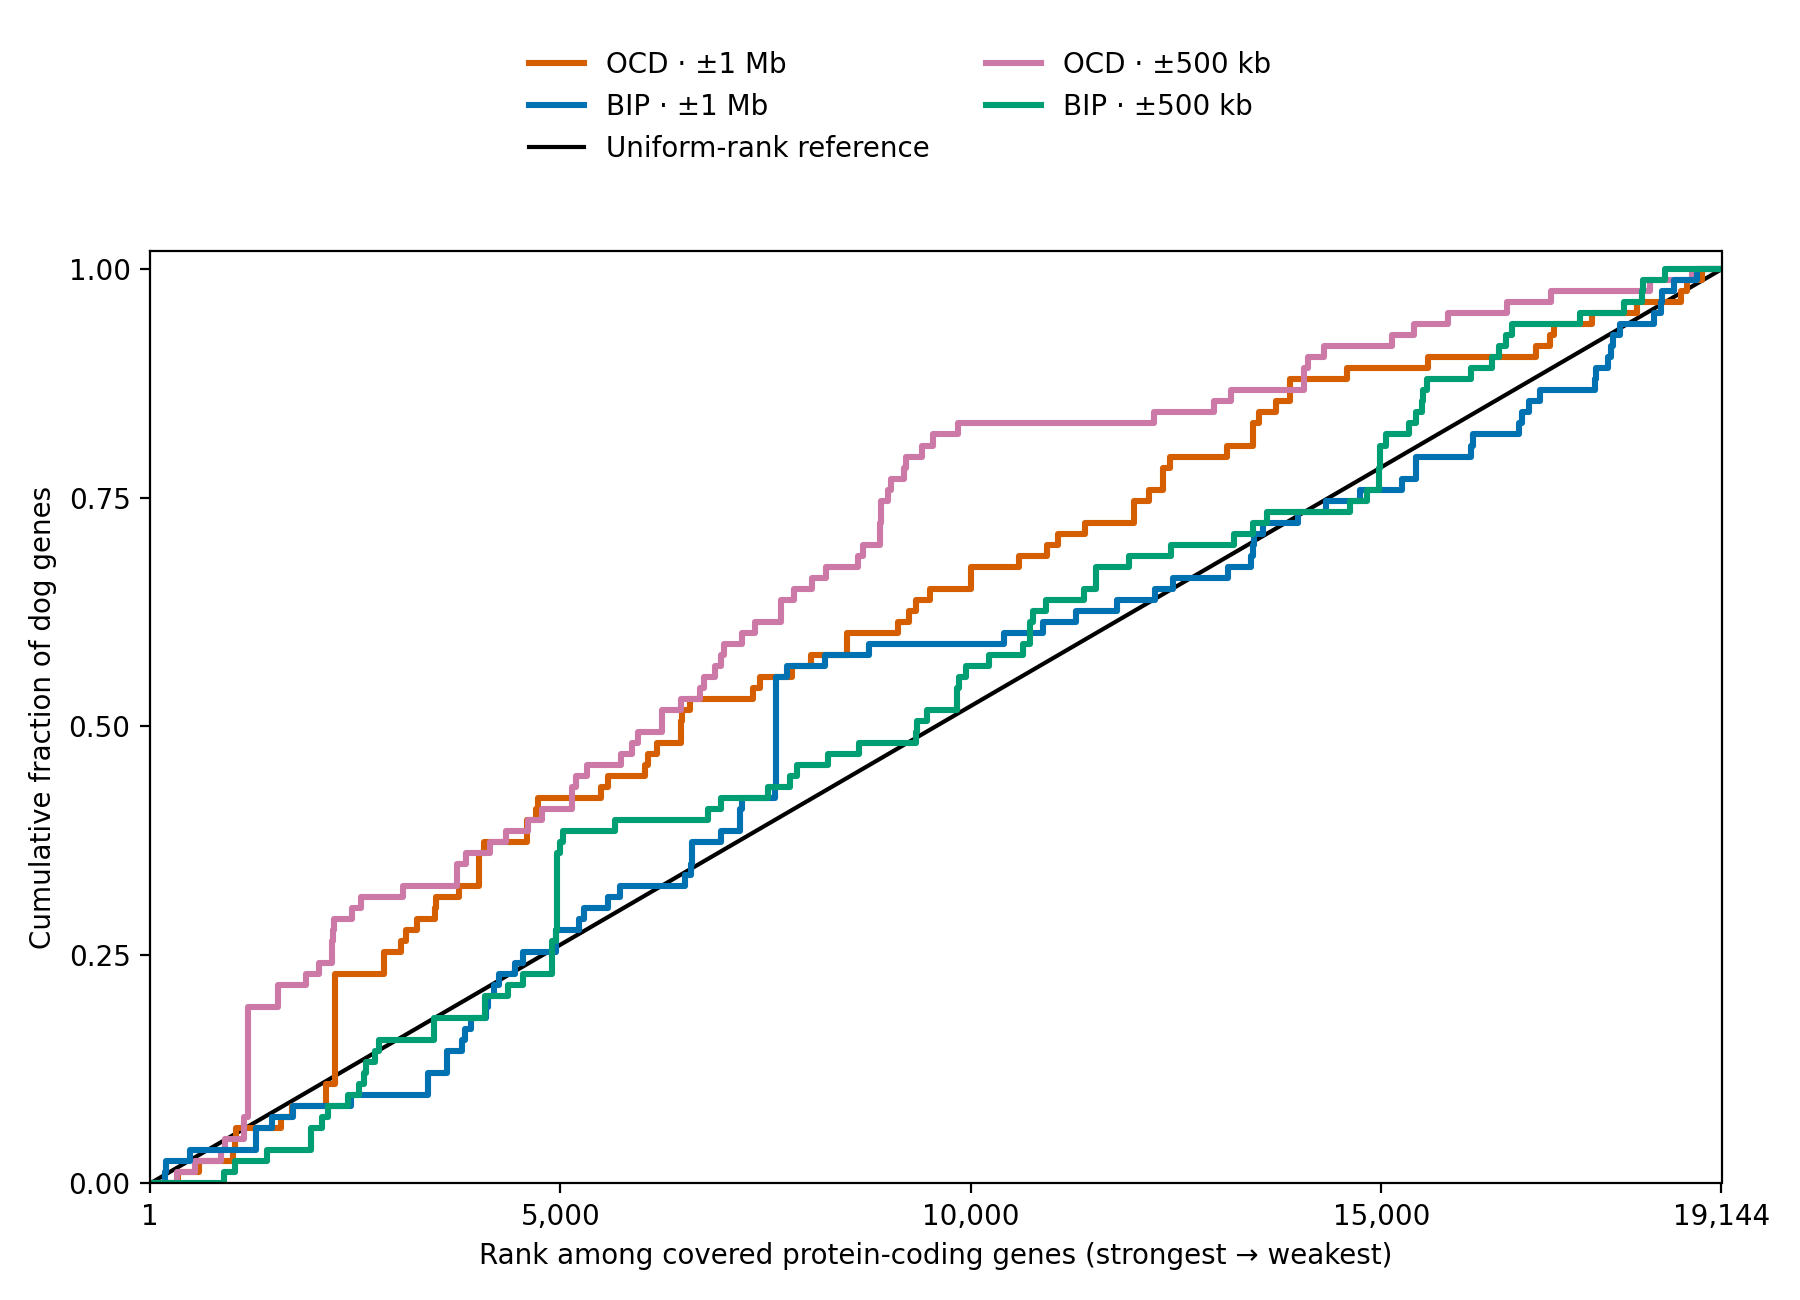

In [30]:
plot_rank_overlay(ranked, comparison_trait='BIP',
                  filename='dog_gene_rank_overlay_ocd_bip.png')
display(Image(filename=str(NOTEBOOK_OUT / 'dog_gene_rank_overlay_ocd_bip.png'), width=900))

#### Circular-shift results

In [31]:
display_permutations(['OCD', 'BIP'])

Trait,Window,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Permutations
OCD,±1 Mb,combined,83,0.4212,0.5028,0.0391,10000
OCD,±1 Mb,significant,43,0.3968,0.5035,0.0872,10000
OCD,±500 kb,combined,83,0.3548,0.5025,0.0003,10000
OCD,±500 kb,significant,43,0.3465,0.5040,0.0132,10000
BIP,±1 Mb,combined,83,0.5300,0.5027,0.709,10000
BIP,±1 Mb,significant,43,0.5793,0.5029,0.824,10000
BIP,±500 kb,combined,83,0.4973,0.5028,0.456,10000
BIP,±500 kb,significant,43,0.5253,0.5027,0.606,10000


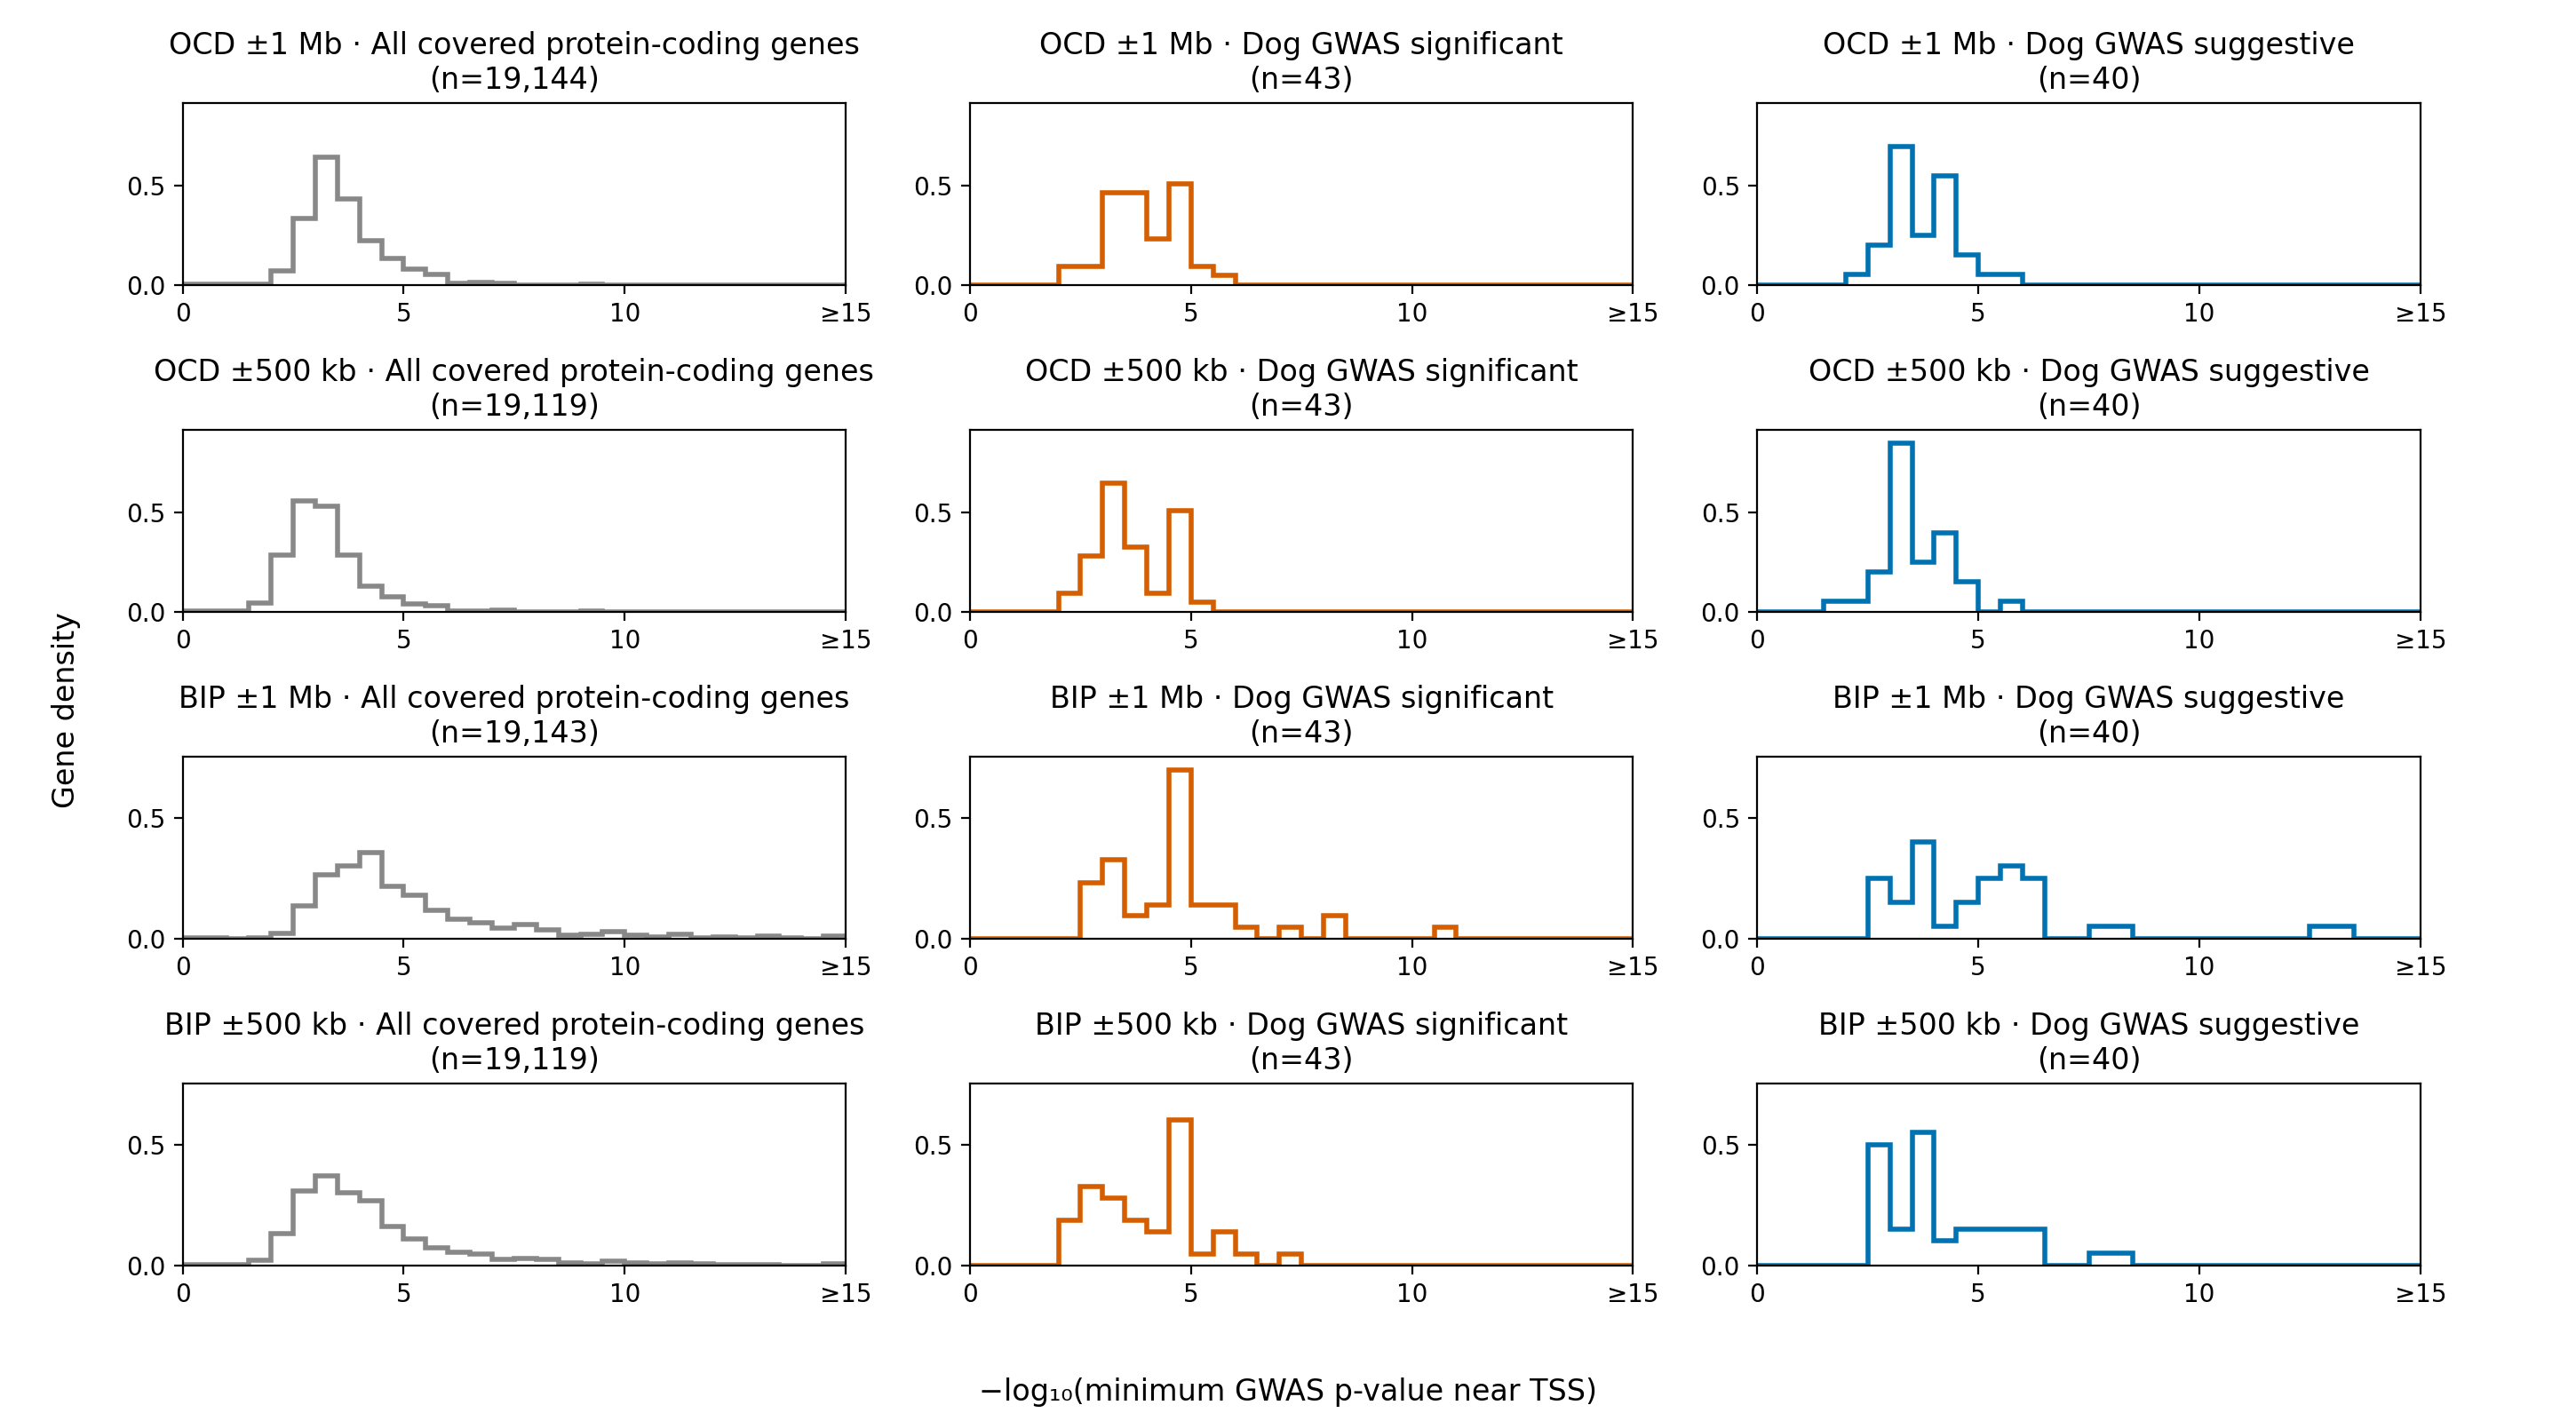

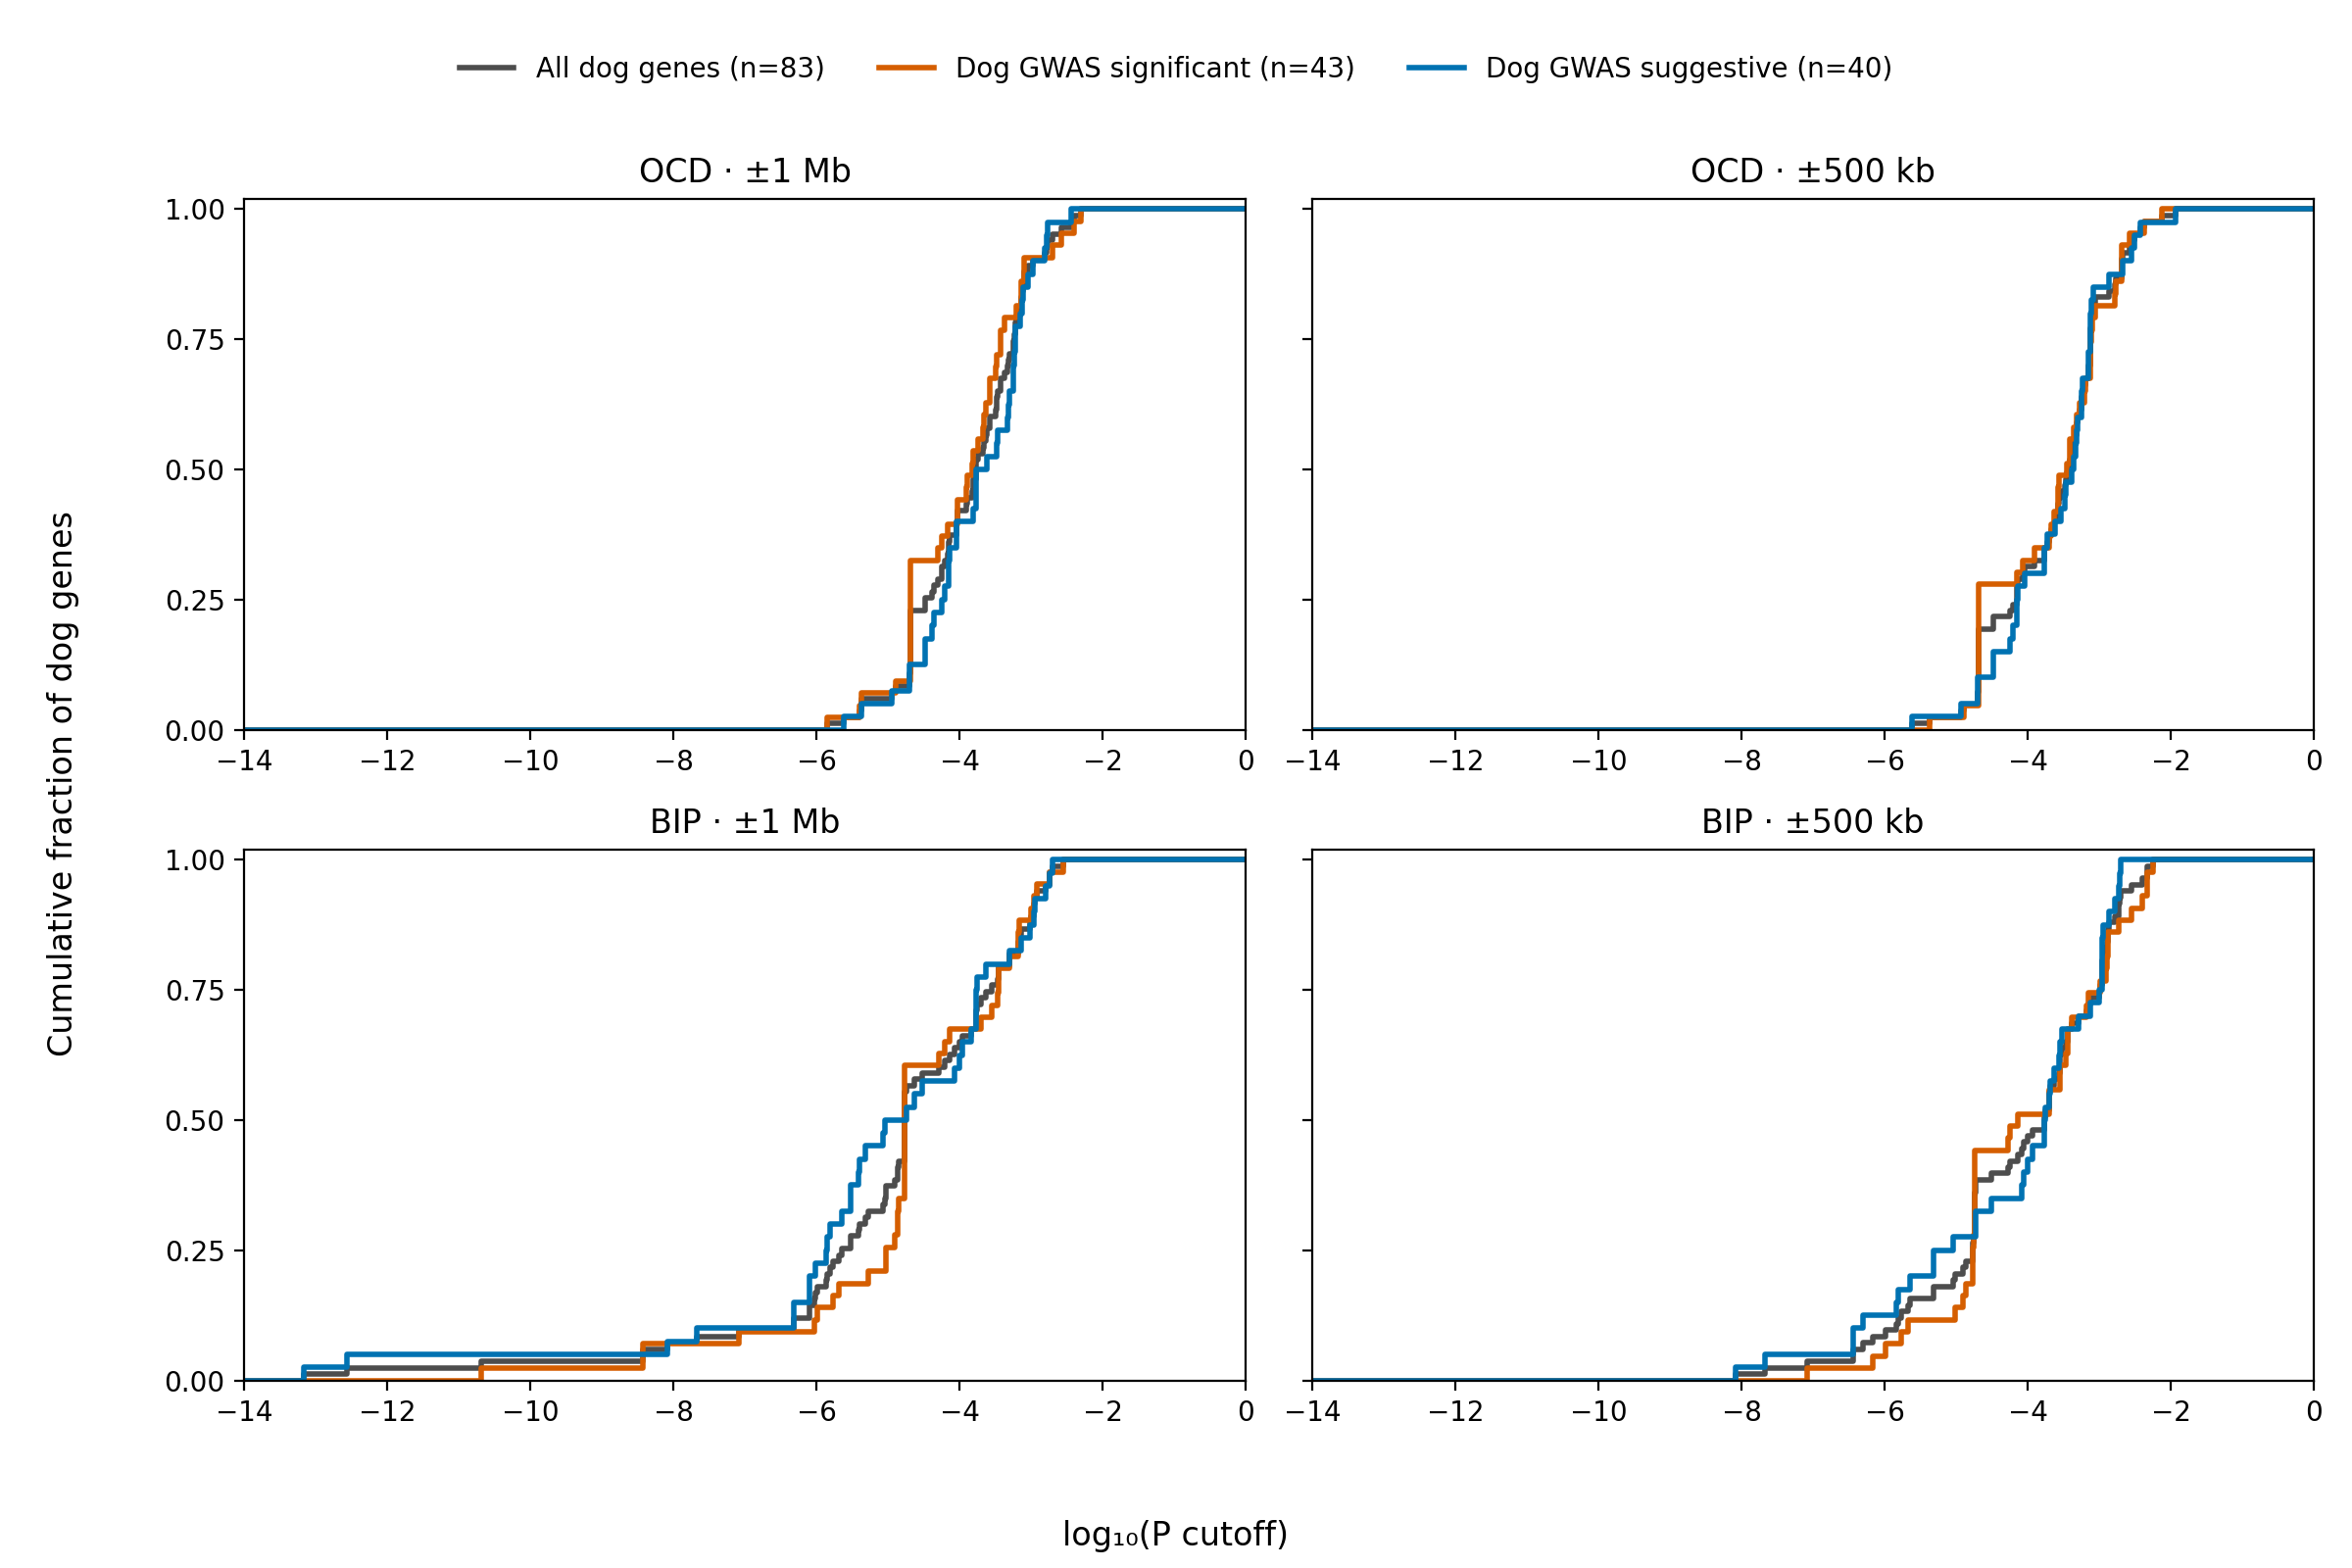

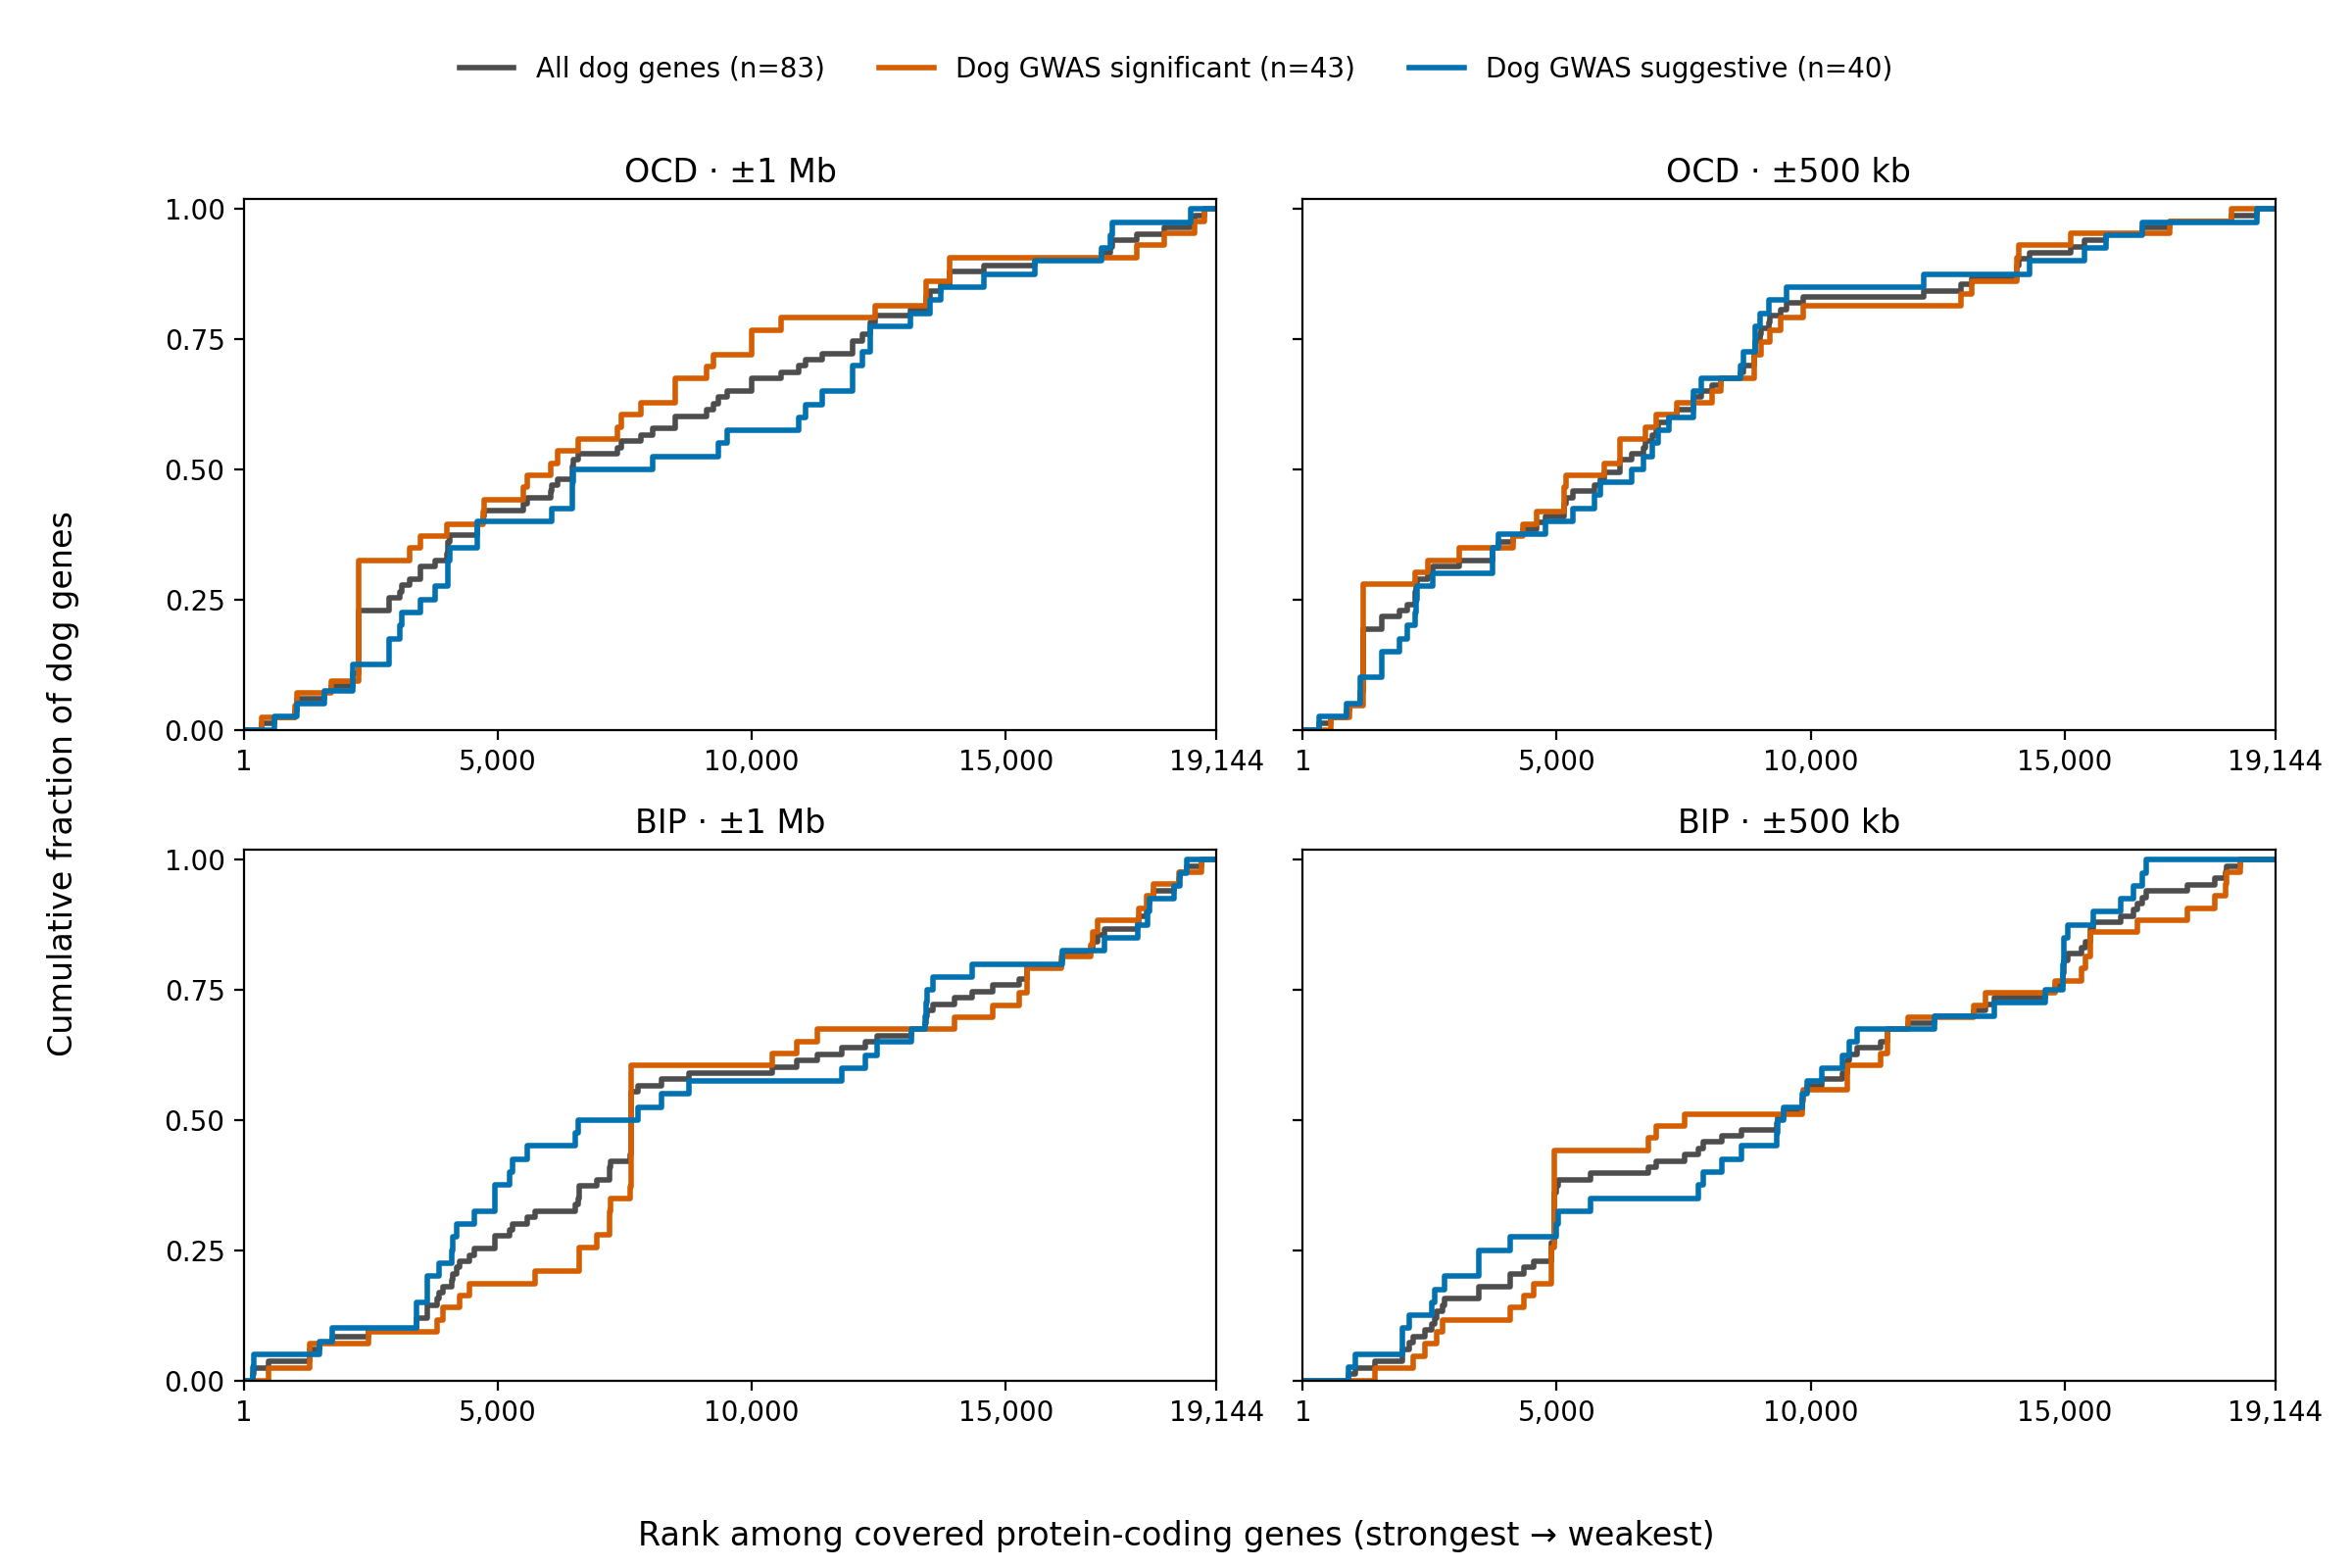

In [32]:
show_additional_comparison('BIP')

### C. OCD vs. ADHD

Repeat the CAD analysis with the same 83 TOGA dog orthologs, non-dog background,
two window widths, three dog sets, one-sided asymptotic Mann–Whitney tests,
rank CDF and 10,000 chromosome-wise circular shifts. Holm correction covers only the six OCD tests; this control trait reports raw p-values. The OCD results below repeat section A.

#### Mann–Whitney tables

In [33]:
display_mann_whitney('OCD')
display_mann_whitney('ADHD')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
±1 Mb,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
±1 Mb,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
±500 kb,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
±500 kb,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
±500 kb,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06


Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,062","418,520.5",0.5106,0.405,—
±1 Mb,suggestive,40,"19,062","406,375.0",0.5330,0.235,—
±1 Mb,combined,83,"19,062","824,895.5",0.5214,0.25,—
±500 kb,significant,43,"19,043","472,839.0",0.5774,0.0394,—
±500 kb,suggestive,40,"19,043","438,482.5",0.5756,0.0489,—
±500 kb,combined,83,"19,043","911,321.5",0.5766,0.00794,—


#### Cumulative gene-rank distributions: four lines plus diagonal

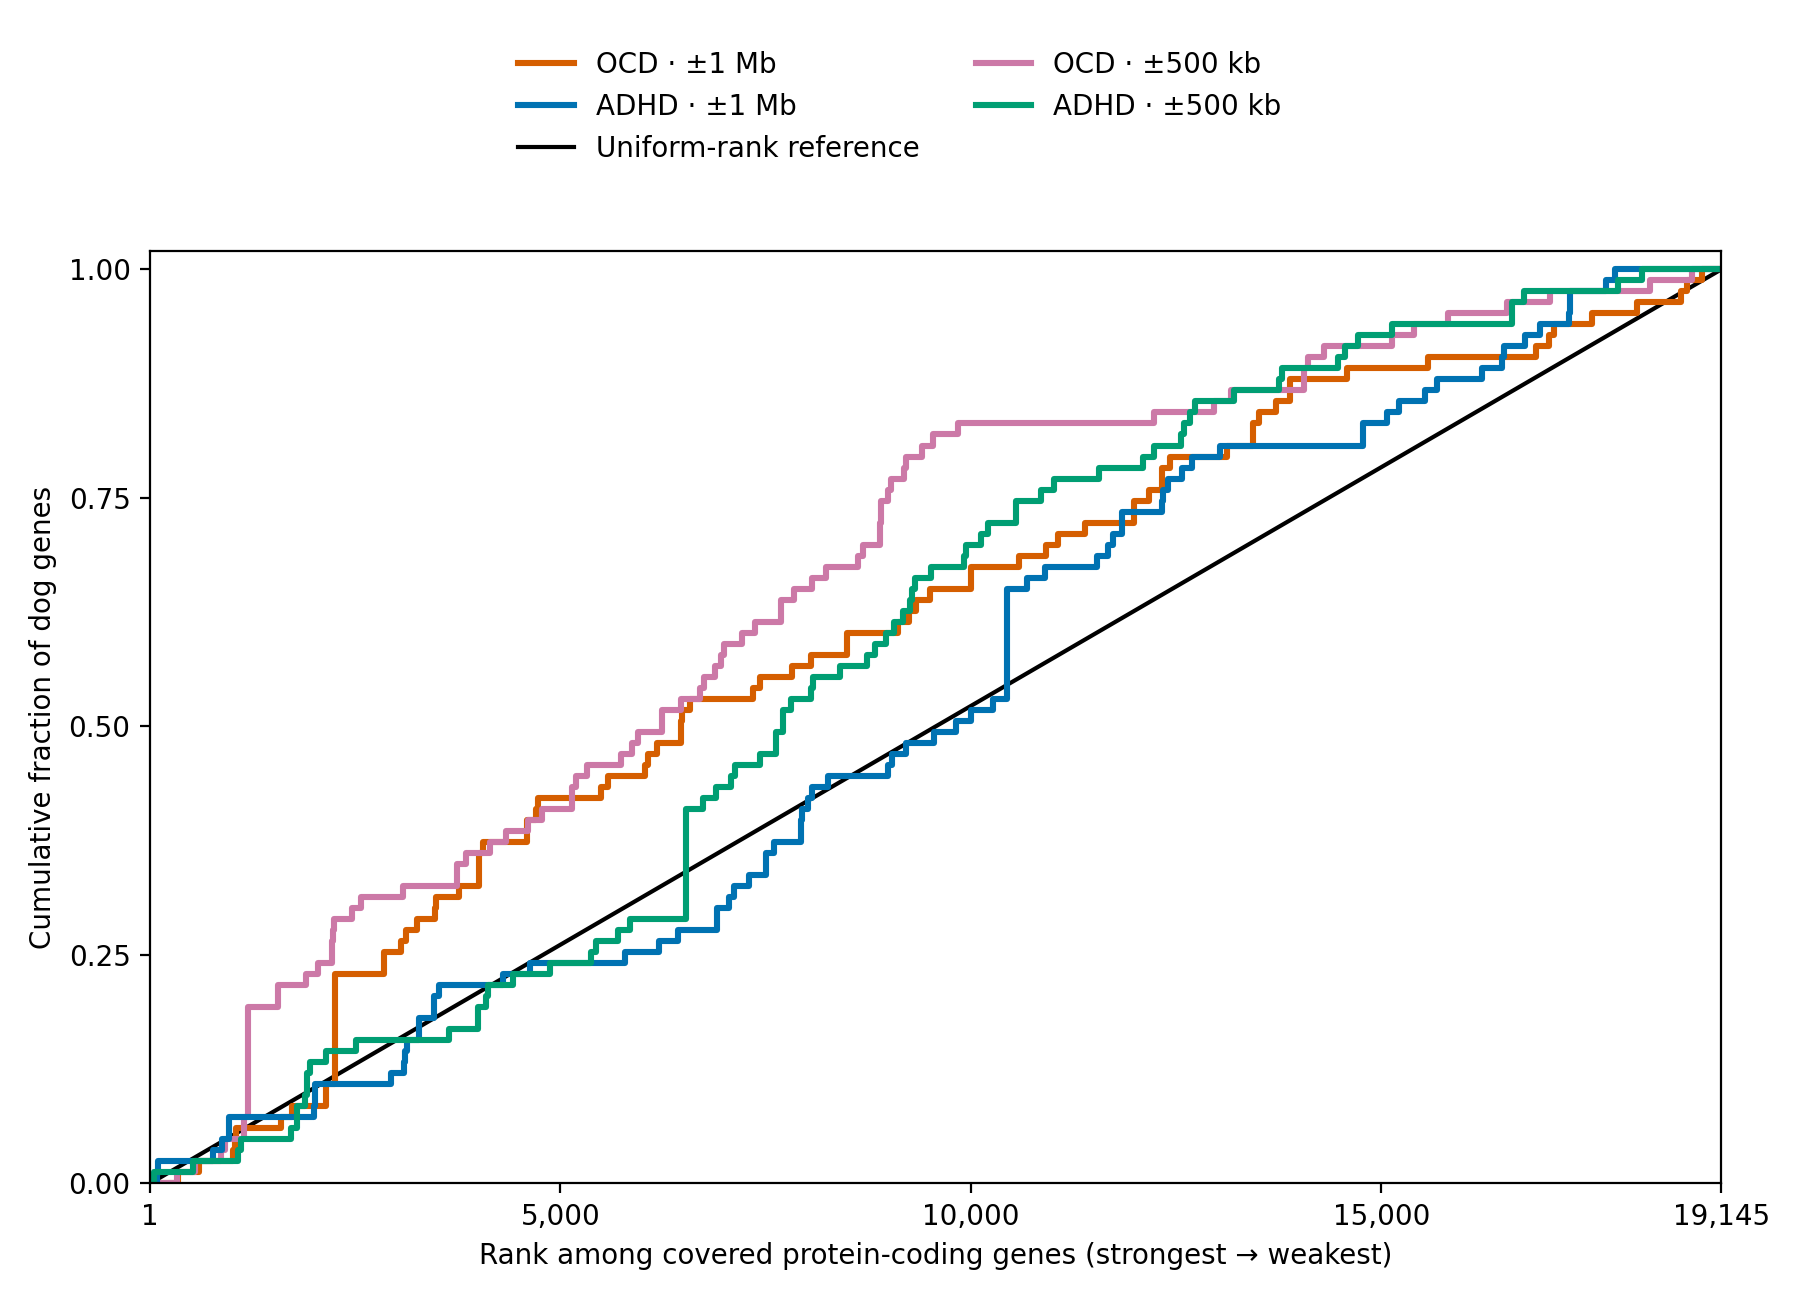

In [34]:
plot_rank_overlay(ranked, comparison_trait='ADHD',
                  filename='dog_gene_rank_overlay_ocd_adhd.png')
display(Image(filename=str(NOTEBOOK_OUT / 'dog_gene_rank_overlay_ocd_adhd.png'), width=900))

#### Circular-shift results

In [35]:
display_permutations(['OCD', 'ADHD'])

Trait,Window,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Permutations
OCD,±1 Mb,combined,83,0.4212,0.5028,0.0391,10000
OCD,±1 Mb,significant,43,0.3968,0.5035,0.0872,10000
OCD,±500 kb,combined,83,0.3548,0.5025,0.0003,10000
OCD,±500 kb,significant,43,0.3465,0.5040,0.0132,10000
ADHD,±1 Mb,combined,83,0.5066,0.5036,0.519,10000
ADHD,±1 Mb,significant,43,0.5119,0.5032,0.539,10000
ADHD,±500 kb,combined,83,0.4633,0.5033,0.211,10000
ADHD,±500 kb,significant,43,0.4630,0.5032,0.312,10000


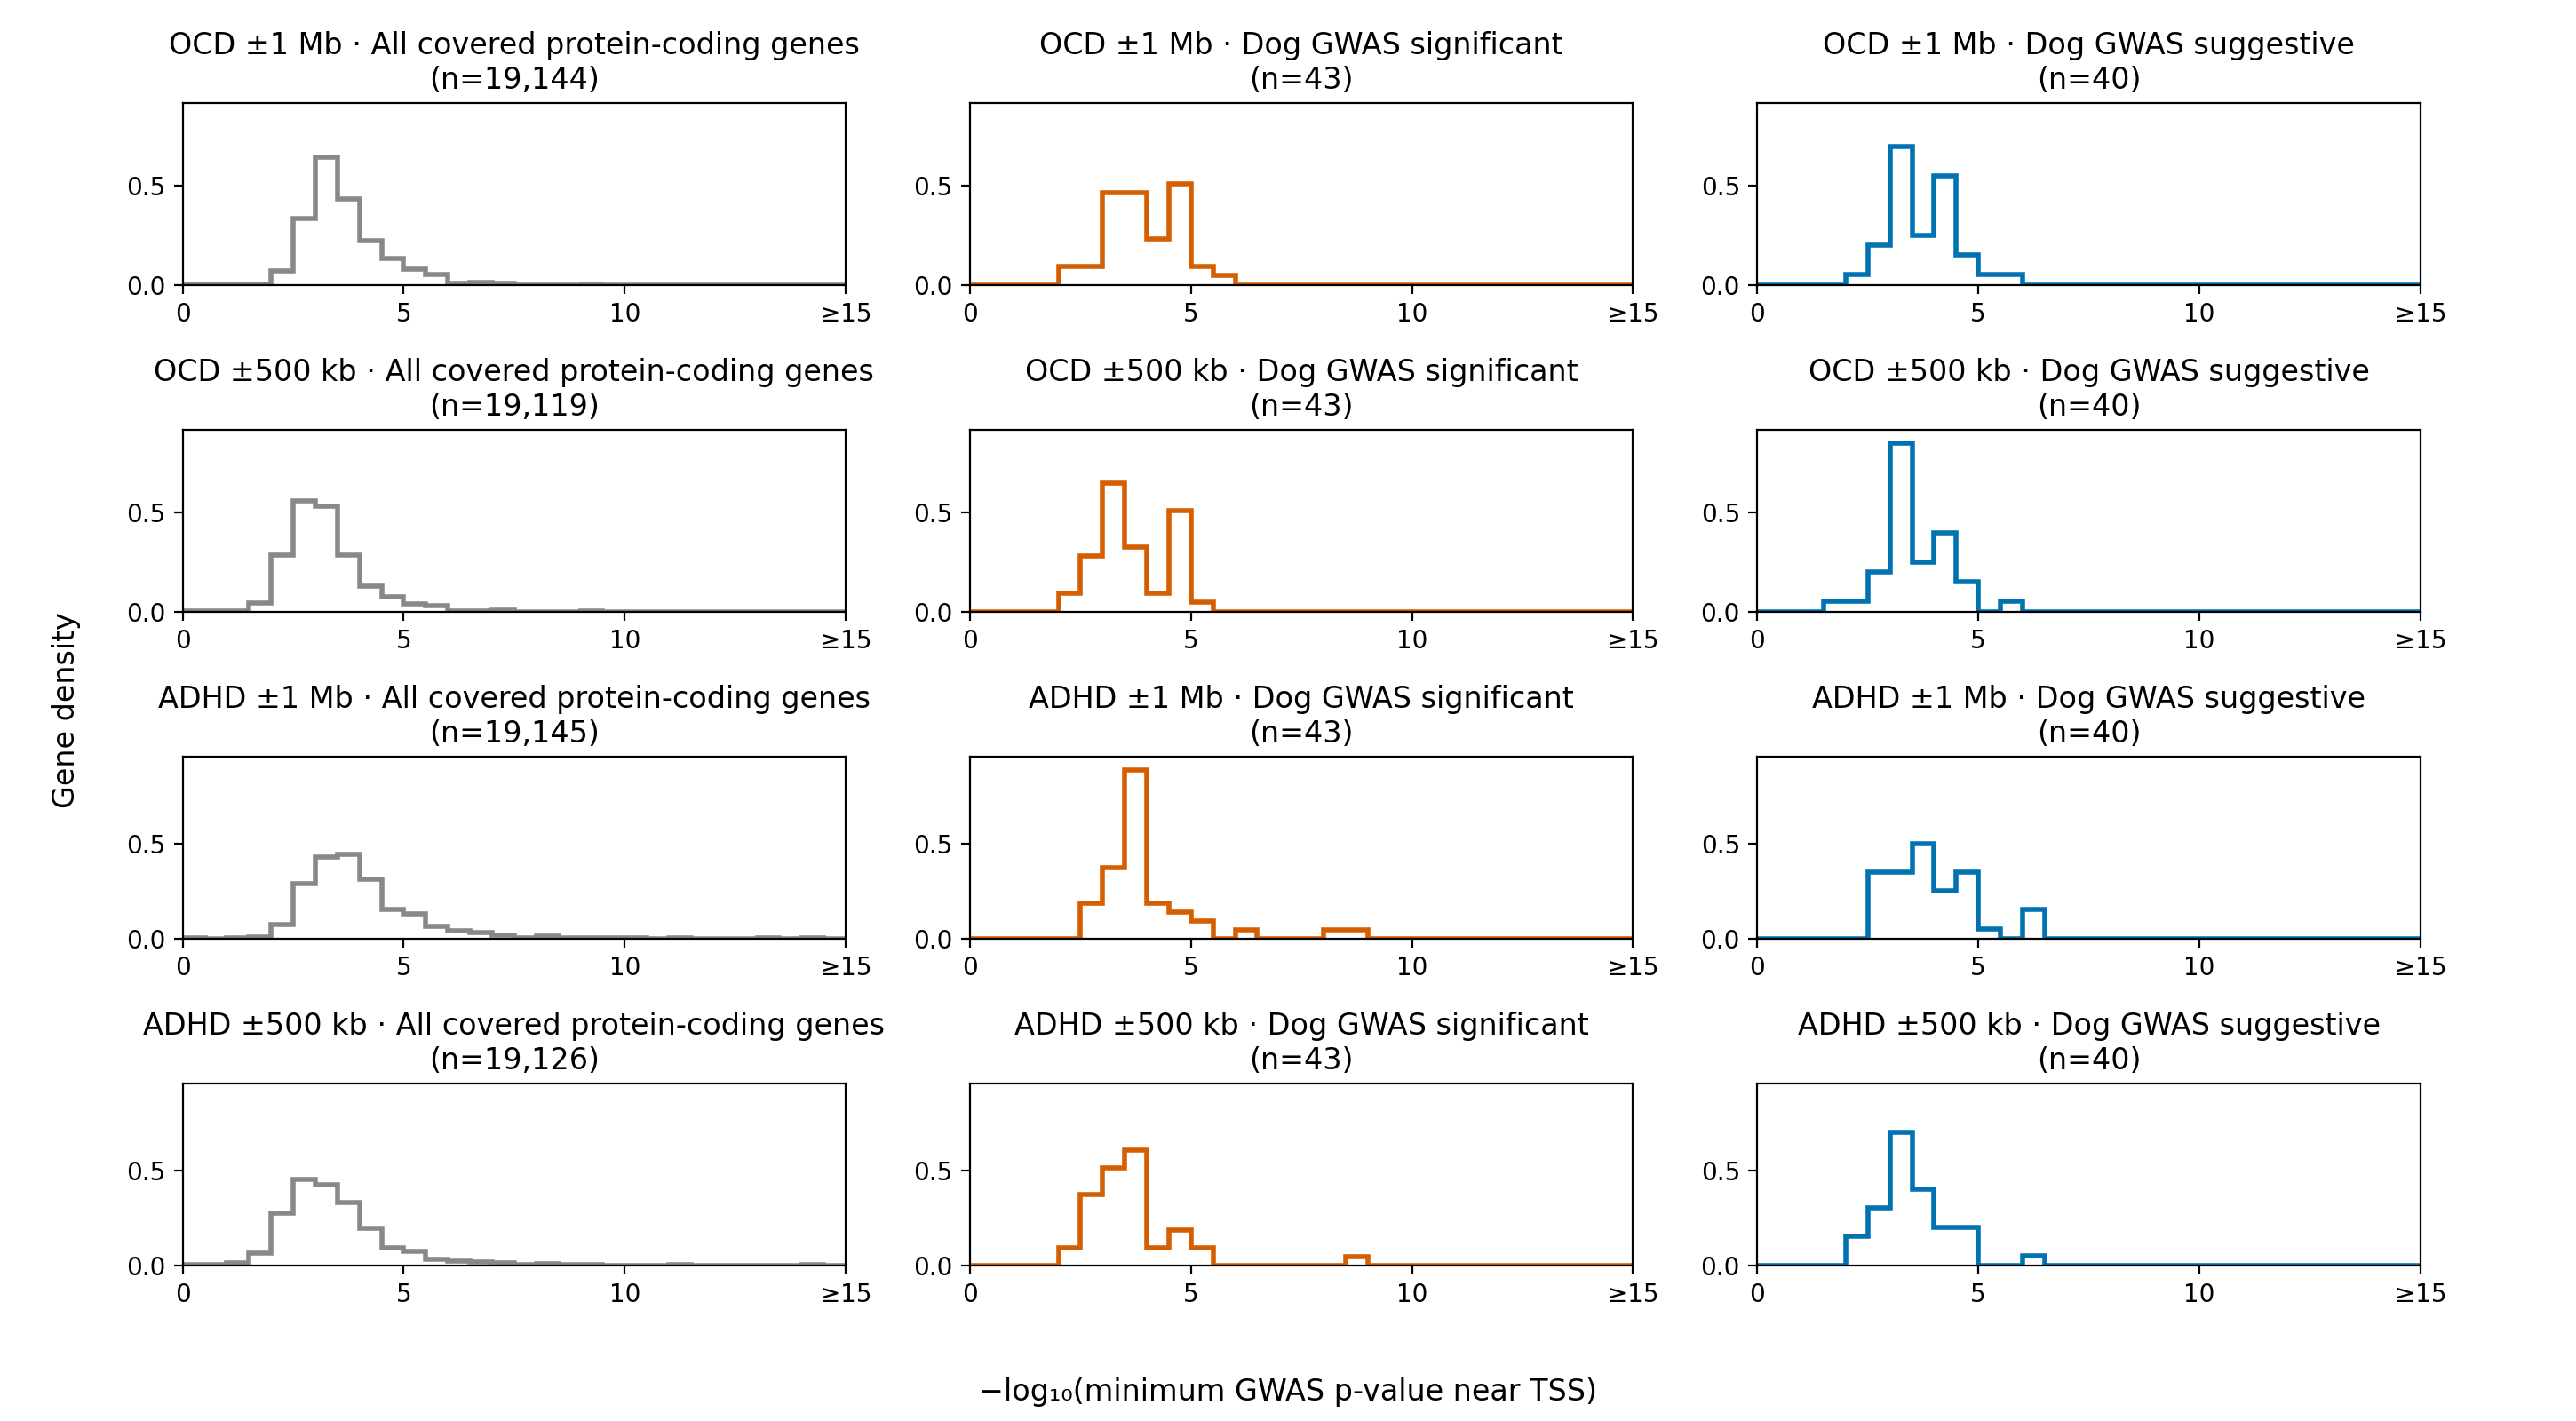

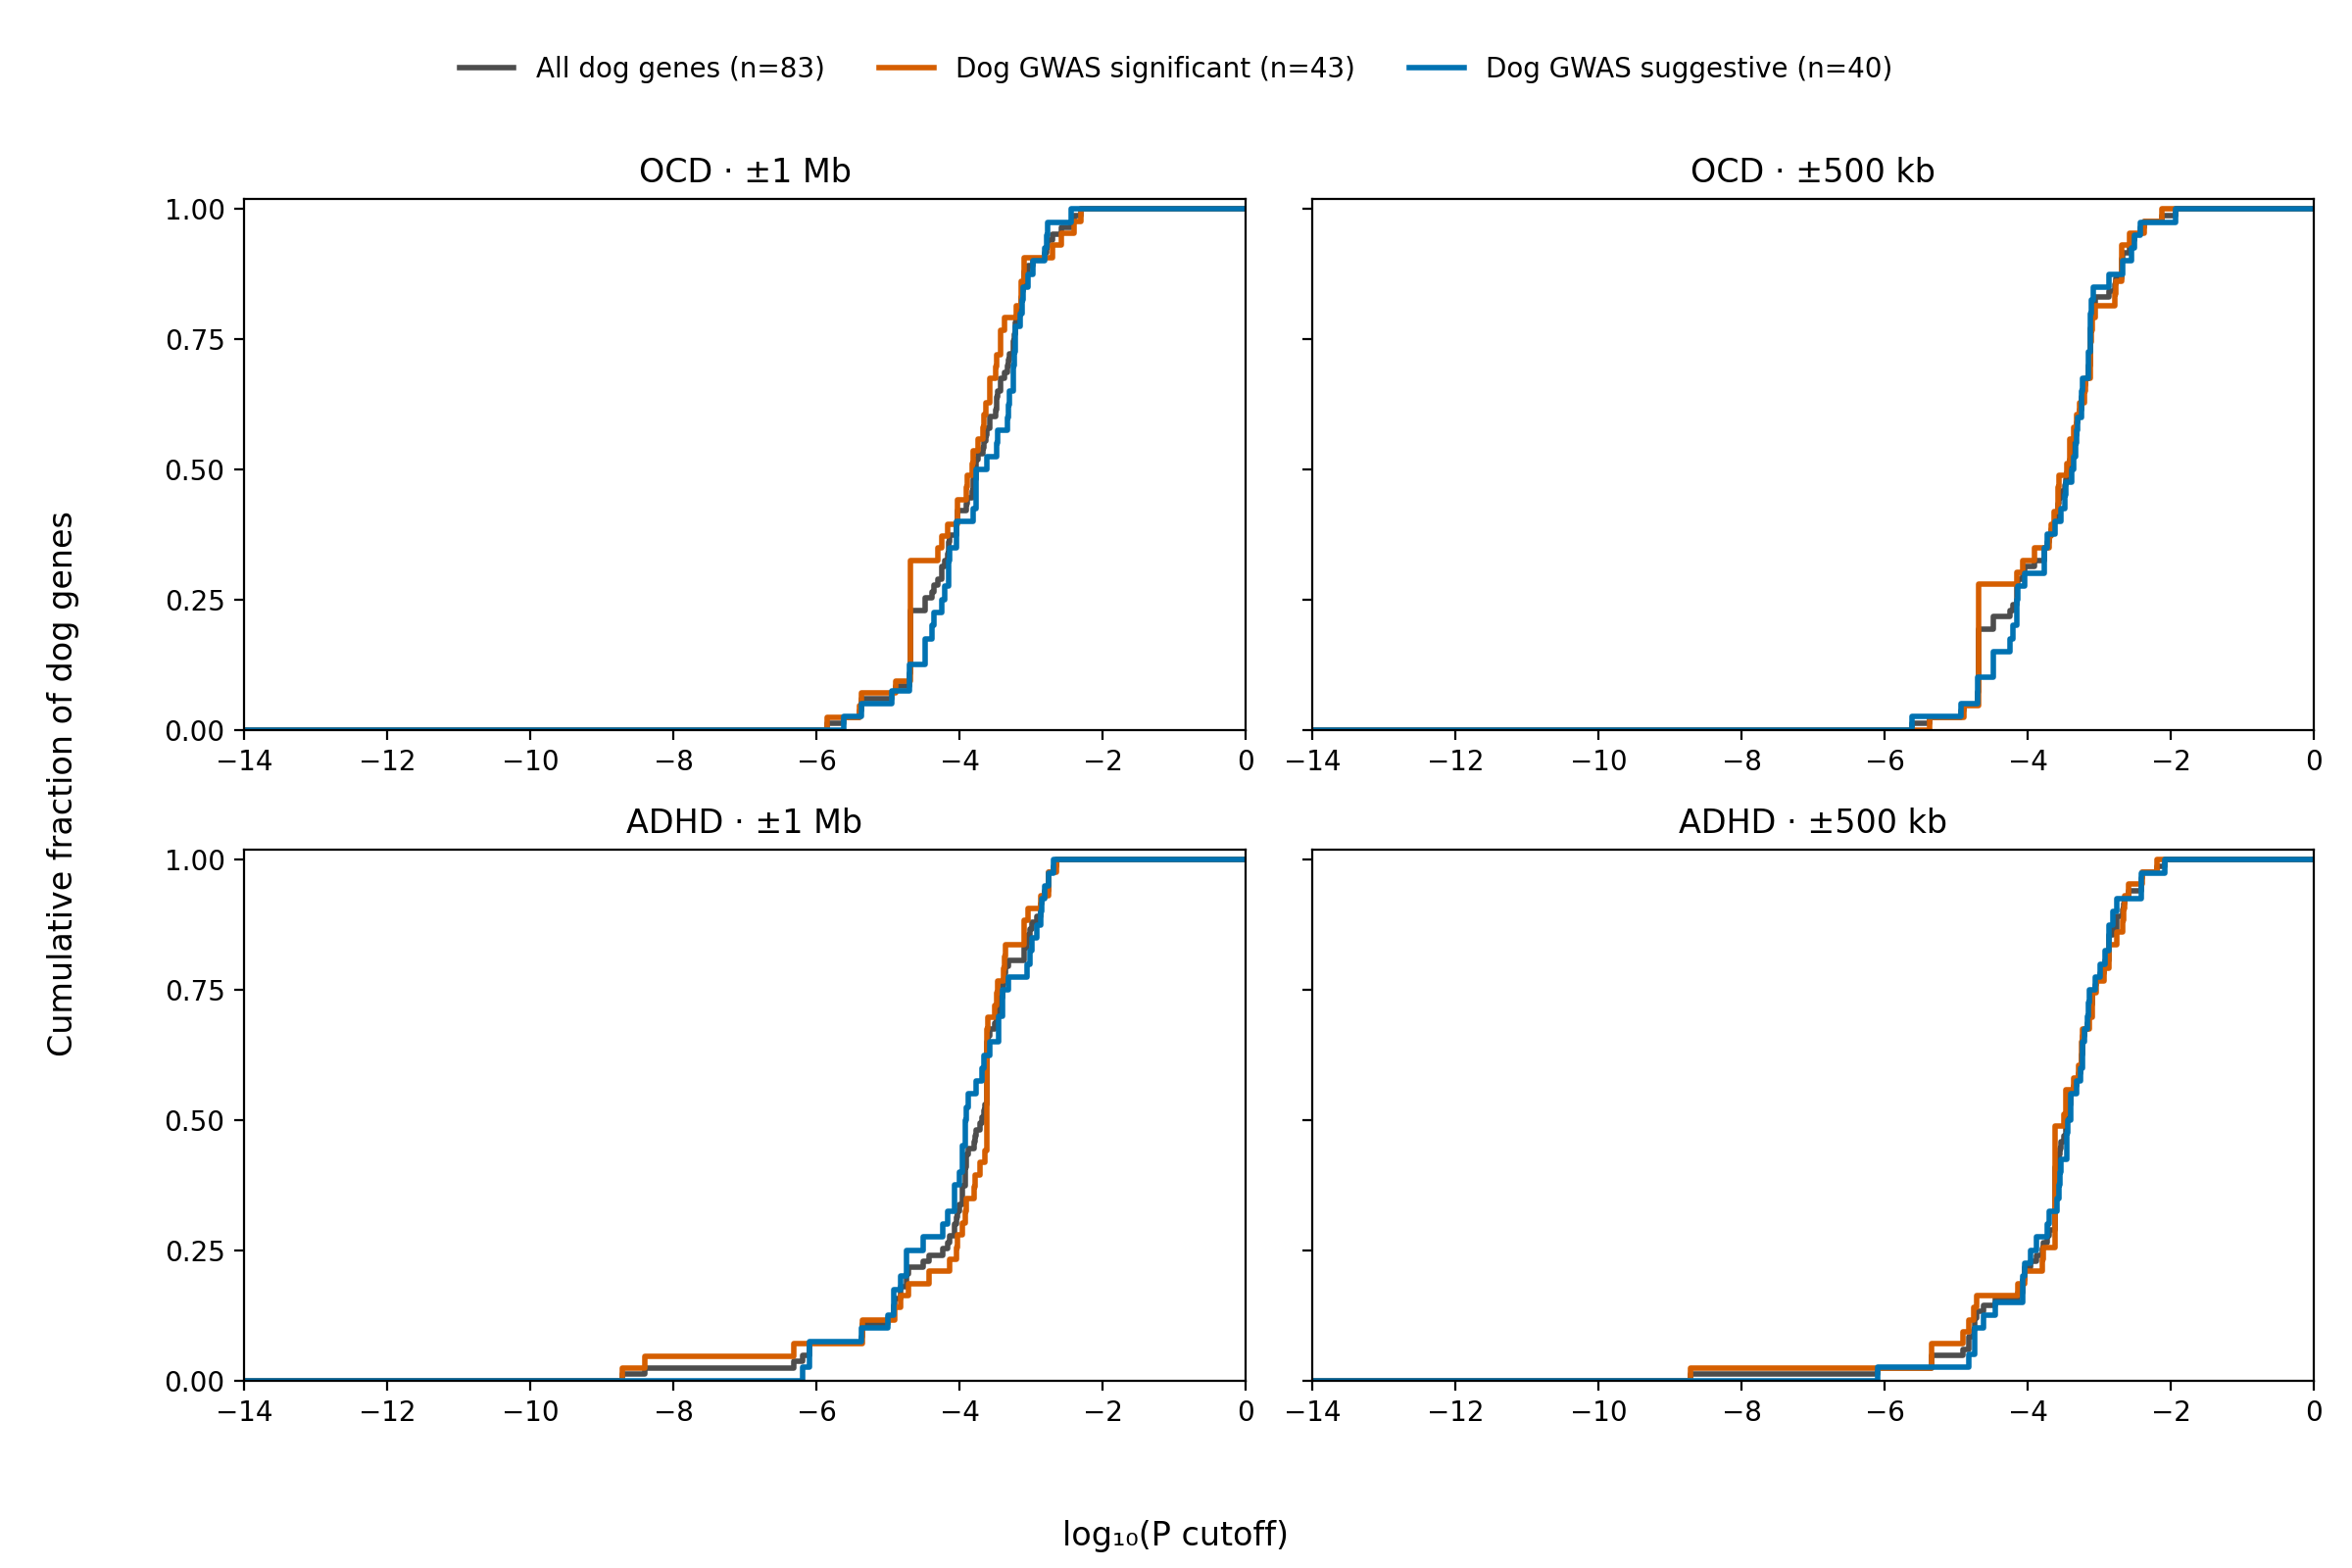

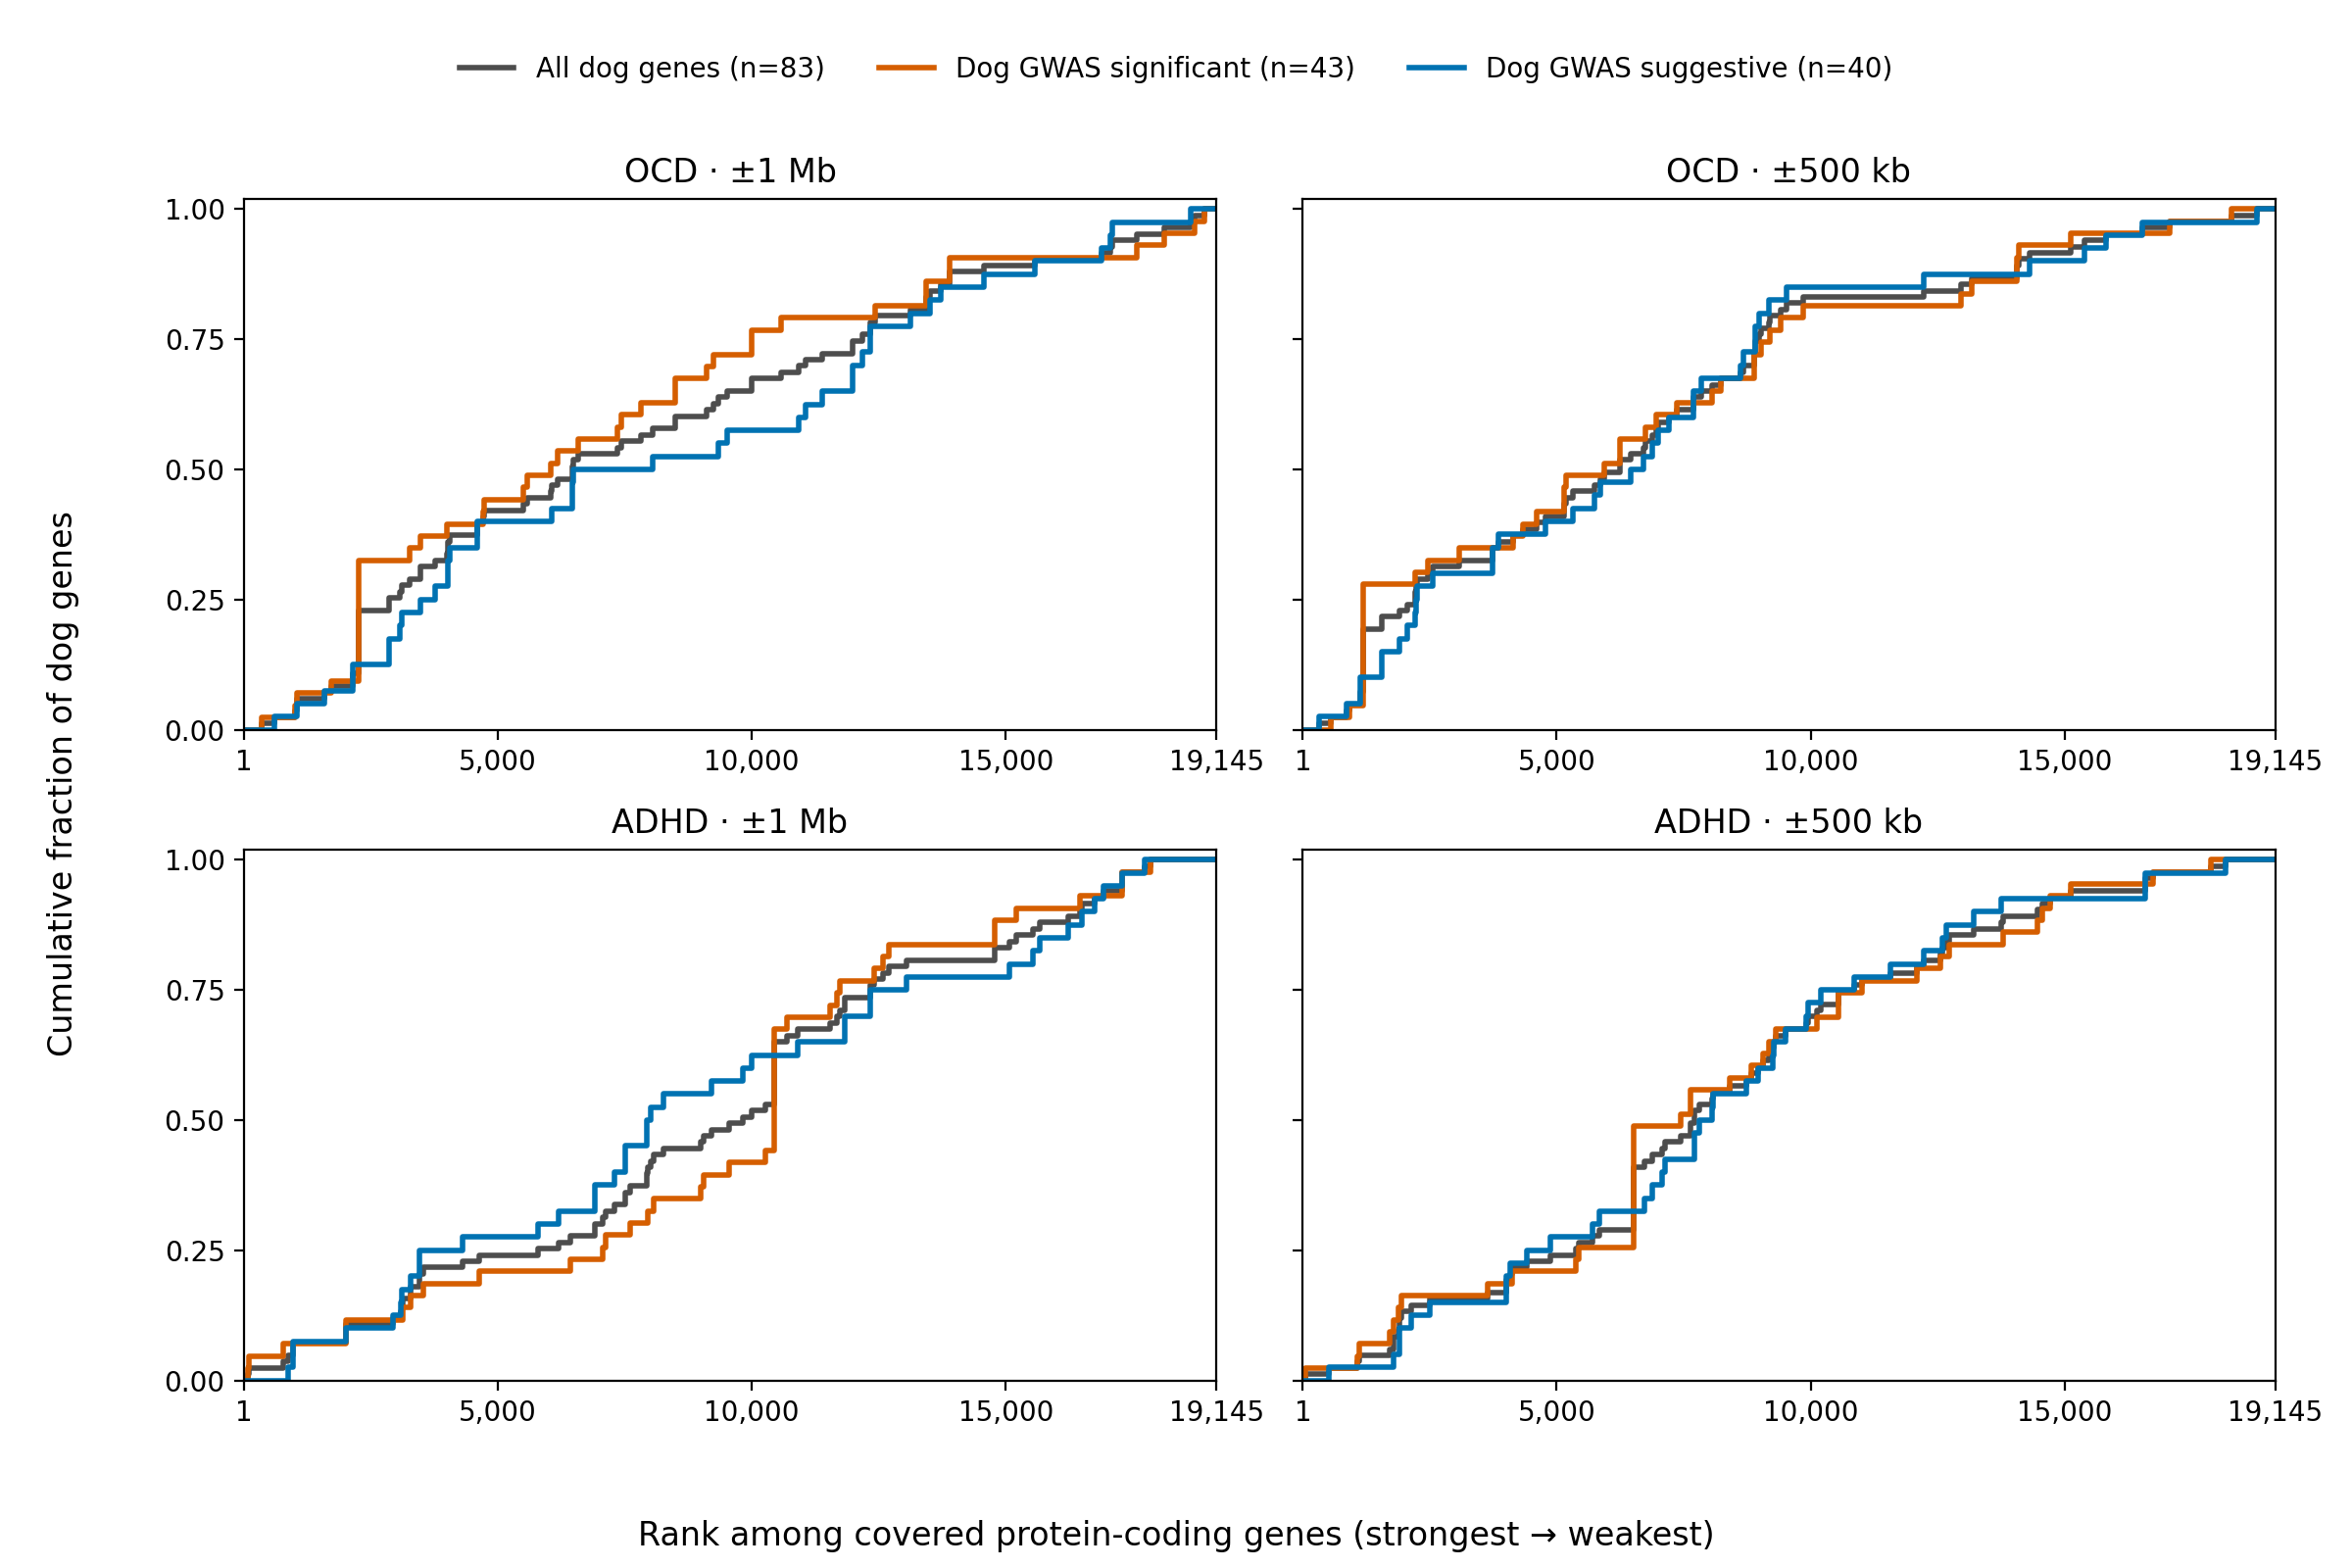

In [36]:
show_additional_comparison('ADHD')

### D. Summary across all six traits

The table shows the combined 83-gene set at both windows. Holm correction is
restricted to the **six OCD tests**: two windows × three dog sets. The five
control traits retain raw p-values and have no reported Holm value. Repeated
OCD tables refer to the same six tests. Circular-shift p-values are unadjusted.


In [37]:
combined_summary = mw_results.loc[mw_results.dog_set.eq('combined'), [
    'trait', 'window', 'n_dog', 'probability_dog_stronger', 'one_sided_p',
    'holm_adjusted_p']].copy()
combined_summary['window'] = combined_summary.window.map(WINDOW_LABELS)
combined_summary = combined_summary.merge(
    permutation_results.loc[permutation_results['Dog set'].eq('combined'),
        ['Trait', 'Window', 'Empirical p']].rename(columns={
            'Trait': 'trait', 'Window': 'window', 'Empirical p': 'circular_shift_p'}),
    on=['trait', 'window'], validate='one_to_one')
display_export(combined_summary.style.format({'probability_dog_stronger': '{:.4f}',
    'one_sided_p': '{:.3g}', 'holm_adjusted_p': '{:.3g}',
    'circular_shift_p': '{:.3g}'}, na_rep='—').hide(axis='index'), 'combined_dog_enrichment_summary', 'Summary for all 83 TOGA dog genes across six traits and both windows. It combines one-sided Mann–Whitney tests against non-dog covered genes with 10,000 within-chromosome circular-shift p-values. probability_dog_stronger counts ties as one-half. Holm correction applies only within the six OCD dog-set tests; control-trait Holm fields are blank. Circular-shift p-values are unadjusted.')
enriched = mw_results.loc[mw_results.holm_adjusted_p.lt(0.05)]
for trait in trait_frames:
    if trait != 'OCD':
        display(Markdown(f"**{trait}:** Control trait; raw p-values reported without Holm correction."))
        continue
    rows = enriched.loc[enriched.trait.eq(trait)]
    findings = ', '.join(f"{r.dog_set} ({WINDOW_LABELS[r.window]})" for r in rows.itertuples())
    display(Markdown(f"**{trait}:** " +
        (f"Holm p < 0.05 for {findings}." if findings else
         "No dog set has Holm p < 0.05 at either window.")))

trait,window,n_dog,probability_dog_stronger,one_sided_p,holm_adjusted_p,circular_shift_p
OCD,±1 Mb,83,0.5975,0.00107,0.0032,0.0391
OCD,±500 kb,83,0.6567,4.02e-07,2.41e-06,0.0003
CAD,±1 Mb,83,0.4470,0.952,—,0.721
CAD,±500 kb,83,0.4345,0.98,—,0.958
BIP,±1 Mb,83,0.5097,0.38,—,0.709
BIP,±500 kb,83,0.5214,0.25,—,0.456
ADHD,±1 Mb,83,0.5214,0.25,—,0.519
ADHD,±500 kb,83,0.5766,0.00794,—,0.211
MDD,±1 Mb,83,0.4903,0.621,—,0.392
MDD,±500 kb,83,0.5317,0.159,—,0.217


**OCD:** Holm p < 0.05 for significant (±1 Mb), combined (±1 Mb), significant (±500 kb), suggestive (±500 kb), combined (±500 kb).

**CAD:** Control trait; raw p-values reported without Holm correction.

**BIP:** Control trait; raw p-values reported without Holm correction.

**ADHD:** Control trait; raw p-values reported without Holm correction.

**MDD:** Control trait; raw p-values reported without Holm correction.

**SCZ:** Control trait; raw p-values reported without Holm correction.

### E. Combined CDF panels and enrichment tables

The two panels show the ±500 kb and ±1 Mb TSS windows. Each panel contains
six gene-rank CDFs, one each for OCD, CAD, bipolar disorder (BIP), ADHD,
major depressive disorder (MDD), and schizophrenia (SCZ).
Each curve contains the same 83 TOGA dog orthologs, ranked within its own trait
and window. Colors identify traits consistently across panels. Both panels
use the same rank and cumulative-fraction axes.

Results are collected across all six traits in separate Mann–Whitney and
circular-shift tables, with one table per window for each test.


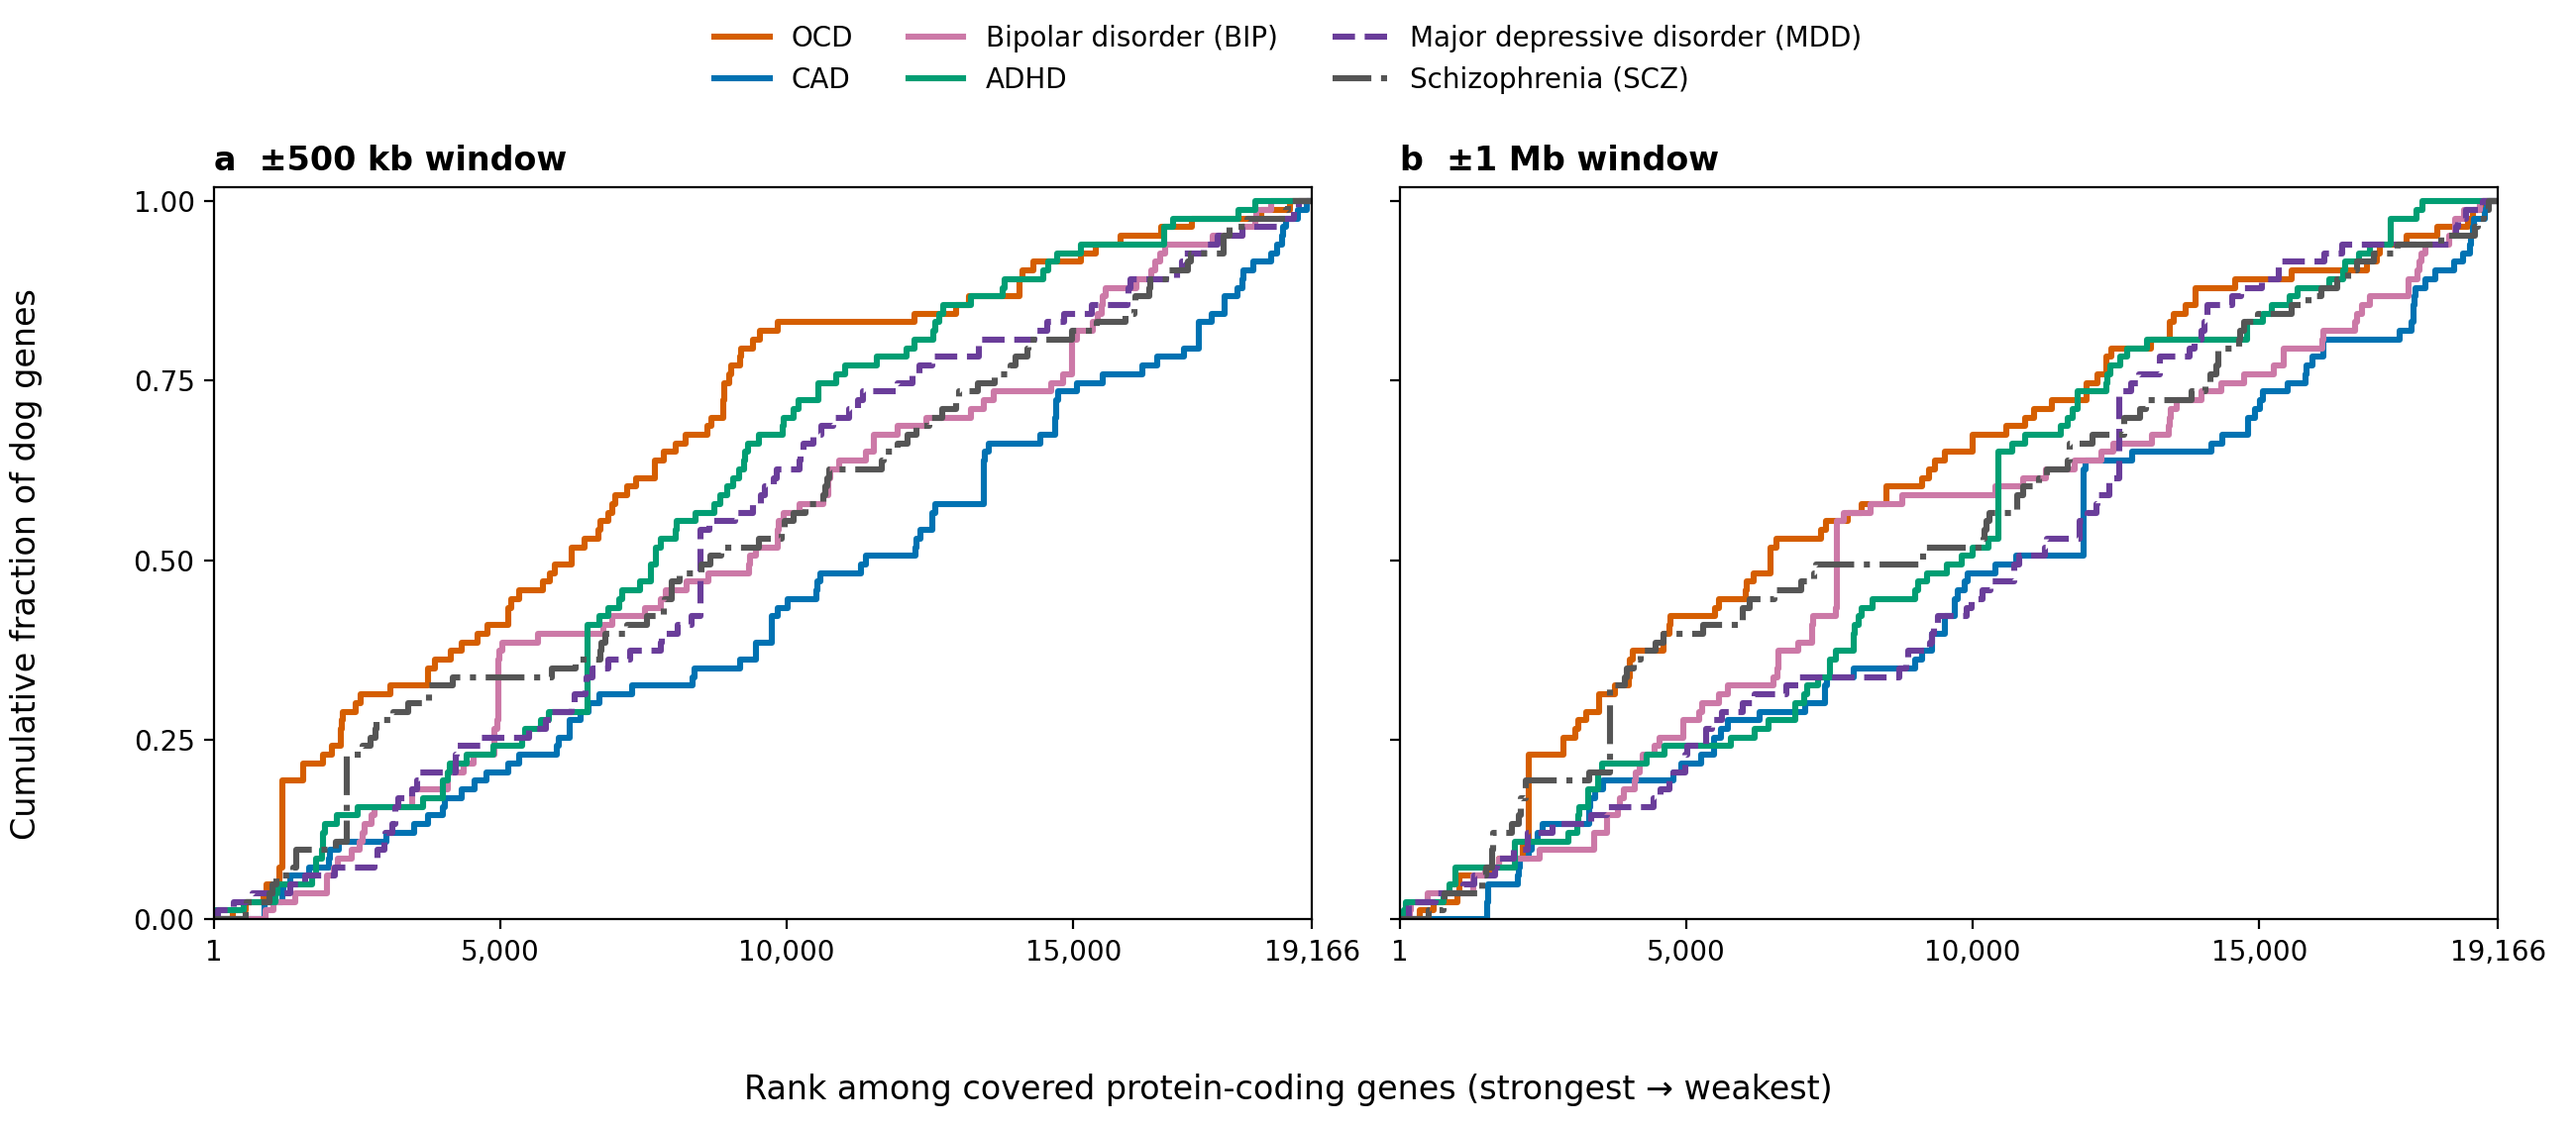

In [38]:
def plot_all_trait_rank_panels(ranked, mask_col='dog', expected_n=DOG_N, gene_set='dog'):
    traits = (
        ('OCD', 'OCD', '#d55e00'),
        ('CAD', 'CAD', '#0072b2'),
        ('BIP', 'Bipolar disorder (BIP)', '#cc79a7'),
        ('ADHD', 'ADHD', '#009e73'),
        ('MDD', 'Major depressive disorder (MDD)', '#6a3d9a'),
        ('SCZ', 'Schizophrenia (SCZ)', '#555555'),
    )
    panels = (('500kb', 'a  ±500 kb window'), ('1mb', 'b  ±1 Mb window'))
    frames = {(trait, window): ranked.loc[
        ranked.trait.eq(trait) & ranked.window.eq(window)]
        for trait, _, _ in traits for window, _ in panels}
    max_rank = max(len(frame) for frame in frames.values())
    selected_ids = None
    with plt.rc_context({'pdf.fonttype': 42}):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.7), sharex=True, sharey=True)
        for ax, (window, title) in zip(axes, panels):
            for trait, label, color in traits:
                frame = frames[trait, window]
                if frame.empty or frame.gene_id.duplicated().any():
                    raise ValueError(f'Missing or duplicate {trait} {window} gene ranks')
                if not frame['rank'].between(1, len(frame)).all():
                    raise ValueError(f'Invalid {trait} {window} gene ranks')
                selected = frame.loc[frame[mask_col]]
                if len(selected) != expected_n:
                    raise ValueError(f'Expected {expected_n} {gene_set} genes in {trait} {window}')
                ids = set(selected.gene_id)
                if selected_ids is not None and ids != selected_ids:
                    raise ValueError(f'{gene_set.capitalize()}-gene IDs differ across traits or windows')
                selected_ids = ids
                values = np.sort(selected['rank'].to_numpy(dtype=float))
                fraction = np.arange(1, len(values) + 1) / len(values)
                ax.step(np.r_[1, values, max_rank], np.r_[0, fraction, 1],
                        where='post', linewidth=2.2, color=color, label=label,
                        linestyle={'MDD': '--', 'SCZ': '-.'}.get(trait, '-'))
            ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
            ax.set_xlim(1, max_rank)
            ax.set_ylim(0, 1.02)
            ax.set_xticks([1, 5_000, 10_000, 15_000, max_rank])
            ax.set_xticklabels(['1', '5,000', '10,000', '15,000', f'{max_rank:,}'])
            ax.set_yticks(np.linspace(0, 1, 5))
            assert len(ax.lines) == len(traits)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper center', ncol=3,
                   bbox_to_anchor=(0.5, 1), frameon=False, fontsize=10)
        fig.supxlabel('Rank among covered protein-coding genes (strongest → weakest)',
                      fontsize=12, y=0.02)
        fig.supylabel(f'Cumulative fraction of {gene_set} genes', fontsize=12, x=0.004)
        fig.tight_layout(rect=(0.015, 0.06, 1, 0.9))
        for extension in ('png', 'pdf'):
            fig.savefig(NOTEBOOK_OUT / f'{gene_set}_gene_rank_panels_all_traits.{extension}',
                        dpi=200)
        pdf_path = PLOTS_DIR / f'{gene_set}_gene_rank_panels_all_traits.pdf'
        fig.savefig(pdf_path, dpi=200)
        write_plot_explanation(pdf_path)
        plt.close(fig)


plot_all_trait_rank_panels(ranked)
display(Image(filename=str(NOTEBOOK_OUT / 'dog_gene_rank_panels_all_traits.png'),
              width=1200))

#### Mann–Whitney tests

Each window table contains all three dog sets for six traits. Only OCD rows
have Holm p-values, from the six-test OCD family. Control traits show raw
p-values and a dash in the Holm column.


In [39]:
def style_all_traits_table(table, caption, formats):
    return (table.style.format(formats, na_rep='—').hide(axis='index').set_caption(caption)
        .set_table_styles([
            {'selector': 'caption, th, td',
             'props': [('font-family', 'Arial, Helvetica, sans-serif')]},
            {'selector': 'caption', 'props': [('text-align', 'left'),
                ('font-weight', 'bold'), ('font-size', '14px'), ('padding', '10px 0')]},
            {'selector': 'th, td', 'props': [('padding', '6px 9px'),
                ('white-space', 'nowrap')]},
        ]))


def display_all_traits_mann_whitney(window):
    table = mw_results.loc[mw_results.window.eq(window)].copy()
    trait_order = {trait: i for i, trait in enumerate(trait_frames)}
    dog_set_order = {name: i for i, (name, _) in enumerate(DOG_SETS)}
    table = table.sort_values(['trait', 'dog_set'],
        key=lambda values: values.map(trait_order if values.name == 'trait' else dog_set_order))
    assert len(table) == len(trait_frames) * len(DOG_SETS)
    assert not table.duplicated(['trait', 'dog_set']).any()
    stem = f'all_traits_mann_whitney_{window}'
    save_analysis_table(table, NOTEBOOK_OUT / f'{stem}.csv', index=False)
    columns = {
        'trait': 'Trait', 'dog_set': 'Dog set', 'n_dog': 'Dog genes',
        'n_other': 'Non-dog genes', 'u_statistic': 'U',
        'probability_dog_stronger': 'P(dog stronger)',
        'one_sided_p': 'One-sided p', 'holm_adjusted_p': 'Holm p',
    }
    formatted = table[list(columns)].rename(columns=columns)
    styled = style_all_traits_table(formatted,
        f'Mann–Whitney tests · {WINDOW_LABELS[window]} TSS window · Holm: six OCD tests only', {
            'Dog genes': '{:,}', 'Non-dog genes': '{:,}', 'U': '{:,.1f}',
            'P(dog stronger)': '{:.4f}', 'One-sided p': '{:.3g}', 'Holm p': '{:.3g}',
        })
    (NOTEBOOK_OUT / f'{stem}.html').write_text(styled.to_html())
    display_export(styled, stem + '_display', 'Displayed dog-set Mann–Whitney table for all six traits at the specified TSS window. Each significant (43), suggestive (40), or combined (83) TOGA set is compared with non-dog covered genes. The alternative is stronger association in dog genes; P(dog stronger) counts ties as one-half. Holm correction applies only to six OCD tests (two windows × three dog sets); control-trait Holm fields are blank.')
    return table


all_traits_mann_whitney_500kb = display_all_traits_mann_whitney('500kb')
all_traits_mann_whitney_1mb = display_all_traits_mann_whitney('1mb')

Trait,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
OCD,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
OCD,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
OCD,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06
CAD,significant,43,"19,083","311,499.5",0.3796,0.997,—
CAD,suggestive,40,"19,083","376,670.0",0.4935,0.557,—
CAD,combined,83,"19,083","688,169.5",0.4345,0.98,—
BIP,significant,43,"19,036","423,042.5",0.5168,0.351,—
BIP,suggestive,40,"19,036","400,717.5",0.5263,0.283,—
BIP,combined,83,"19,036","823,760.0",0.5214,0.25,—
ADHD,significant,43,"19,043","472,839.0",0.5774,0.0394,—


Trait,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
OCD,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
OCD,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
OCD,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
CAD,significant,43,"19,083","337,251.0",0.4110,0.978,—
CAD,suggestive,40,"19,083","370,756.0",0.4857,0.623,—
CAD,combined,83,"19,083","708,007.0",0.4470,0.952,—
BIP,significant,43,"19,060","403,962.0",0.4929,0.564,—
BIP,suggestive,40,"19,060","402,364.5",0.5278,0.272,—
BIP,combined,83,"19,060","806,326.5",0.5097,0.38,—
ADHD,significant,43,"19,062","418,520.5",0.5106,0.405,—


#### Circular-shift tests

Each window table includes the significant and combined dog sets for all six
traits. These are the dog sets tested by the 10,000 chromosome-wise circular
shifts. Smaller mean percentile ranks indicate stronger association; empirical
p-values are unadjusted.


In [40]:
def display_all_traits_circular_shifts(window):
    table = permutation_results.loc[
        permutation_results.Window.eq(WINDOW_LABELS[window])].copy()
    trait_order = {trait: i for i, trait in enumerate(trait_frames)}
    dog_set_order = {'significant': 0, 'combined': 1}
    table = table.sort_values(['Trait', 'Dog set'],
        key=lambda values: values.map(trait_order if values.name == 'Trait' else dog_set_order))
    assert len(table) == len(trait_frames) * 2
    assert not table.duplicated(['Trait', 'Dog set']).any()
    stem = f'all_traits_circular_shifts_{window}'
    save_analysis_table(table, NOTEBOOK_OUT / f'{stem}.csv', index=False)
    formatted = table.drop(columns='Window').rename(columns={'Permutations': 'Shifts'})
    styled = style_all_traits_table(formatted,
        f'Circular-shift tests · {WINDOW_LABELS[window]} TSS window', {
            'Dog genes': '{:,}', 'Mean rank': '{:.4f}', 'Null mean rank': '{:.4f}',
            'Empirical p': '{:.3g}', 'Shifts': '{:,}',
        })
    (NOTEBOOK_OUT / f'{stem}.html').write_text(styled.to_html())
    display_export(styled, stem + '_display', 'Displayed circular-shift tests across all six traits at the specified window. Significant (43 genes) and combined (83 genes) TOGA dog sets are compared with 10,000 within-chromosome shifts. Smaller observed mean chromosome/SNP-count-stratified signal-rank percentile means stronger enrichment. Empirical p is one-sided with a plus-one correction, without multiple-testing adjustment.')
    return table


all_traits_circular_shifts_500kb = display_all_traits_circular_shifts('500kb')
all_traits_circular_shifts_1mb = display_all_traits_circular_shifts('1mb')

Trait,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Shifts
OCD,significant,43,0.3465,0.5040,0.0132,"10,000"
OCD,combined,83,0.3548,0.5025,0.0003,"10,000"
CAD,significant,43,0.6451,0.5026,0.975,"10,000"
CAD,combined,83,0.5851,0.5025,0.958,"10,000"
BIP,significant,43,0.5253,0.5027,0.606,"10,000"
BIP,combined,83,0.4973,0.5028,0.456,"10,000"
ADHD,significant,43,0.4630,0.5032,0.312,"10,000"
ADHD,combined,83,0.4633,0.5033,0.211,"10,000"
MDD,significant,43,0.4533,0.5039,0.27,"10,000"
MDD,combined,83,0.4652,0.5033,0.217,"10,000"


Trait,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Shifts
OCD,significant,43,0.3968,0.5035,0.0872,"10,000"
OCD,combined,83,0.4212,0.5028,0.0391,"10,000"
CAD,significant,43,0.5695,0.5015,0.783,"10,000"
CAD,combined,83,0.5329,0.5027,0.721,"10,000"
BIP,significant,43,0.5793,0.5029,0.824,"10,000"
BIP,combined,83,0.5300,0.5027,0.709,"10,000"
ADHD,significant,43,0.5119,0.5032,0.539,"10,000"
ADHD,combined,83,0.5066,0.5036,0.519,"10,000"
MDD,significant,43,0.4607,0.5040,0.303,"10,000"
MDD,combined,83,0.4903,0.5035,0.392,"10,000"


### F. Combined CDF panels and enrichment tables, human genes

Repeat section E using all **48 genes labeled Human** in supplementary table ST6
of `NATURE_SupplementaryTables.xlsx`. Exact symbols map uniquely to the same
GENCODE annotation; all 48 genes have covered windows in all six traits and both
window sizes. This set has no dog-GWAS significant/suggestive subdivisions.

The two CDF panels use the same genome-wide ranks, trait colors and axes as
section E, replacing the 83 TOGA dog orthologs with the 48 Human genes. Mann–Whitney
tests compare this set with **all other covered protein-coding genes**, including
dog genes outside the Human set. The one-sided asymptotic test asks whether Human
genes have stronger window associations. Holm adjustment spans **12 Human-set
tests** (six traits × two windows), separately from the six OCD dog-set tests.

Separate circular-shift tables use the same chromosome/SNP-count-stratified
percentile ranks and 10,000 chromosome-wise shifts as section E, now shifting
Human-set labels over TSS-ordered covered genes. The seed is 20261013; smaller
mean percentile ranks indicate stronger association. Empirical p-values remain
unadjusted. These within-trait analyses are exploratory: ST6 gene selection used
the human OCD GWAS, and significance in one trait alone does not establish a
difference between traits.


In [41]:
from src.human_gene_enrichment import (
    read_human_gene_set, human_mann_whitney, circular_shift_gene_set,
)

human_gene_set = read_human_gene_set(ROOT / 'data/downloaded/supplementary/NATURE_SupplementaryTables.xlsx', genes)
human_ids = set(human_gene_set.gene_id)
save_analysis_table(human_gene_set, NOTEBOOK_OUT / 'st6_human_gene_set.csv', index=False)
human_ranked = ranked.assign(human=ranked.gene_id.isin(human_ids))
human_mw_results = human_mann_whitney(human_ranked, human_ids)
assert len(human_mw_results) == 12
assert human_mw_results.n_human.eq(48).all()
assert human_mw_results.holm_family_tests.eq(12).all()
save_analysis_table(human_mw_results, NOTEBOOK_OUT / 'human_mann_whitney_results.csv', index=False)

human_cdf_data = human_ranked.loc[human_ranked.human, [
    'trait', 'window', 'width_each_side_bp', 'gene_id', 'symbol', 'chrom',
    'min_p', 'n_snps', 'rank']].copy()
human_cdf_data = human_cdf_data.sort_values(['trait', 'window', 'rank', 'gene_id'])
human_cdf_data['cdf_fraction'] = (
    human_cdf_data.groupby(['trait', 'window']).cumcount() + 1) / 48
human_cdf_data['gene_set'] = 'ST6 Human'
assert human_cdf_data.groupby(['trait', 'window']).size().eq(48).all()
save_analysis_table(human_cdf_data, NOTEBOOK_OUT / 'human_gene_rank_cdf_source_data.csv', index=False)
print('All 48 ST6 Human genes are covered in every trait/window; 12 Human-set tests.')


All 48 ST6 Human genes are covered in every trait/window; 12 Human-set tests.


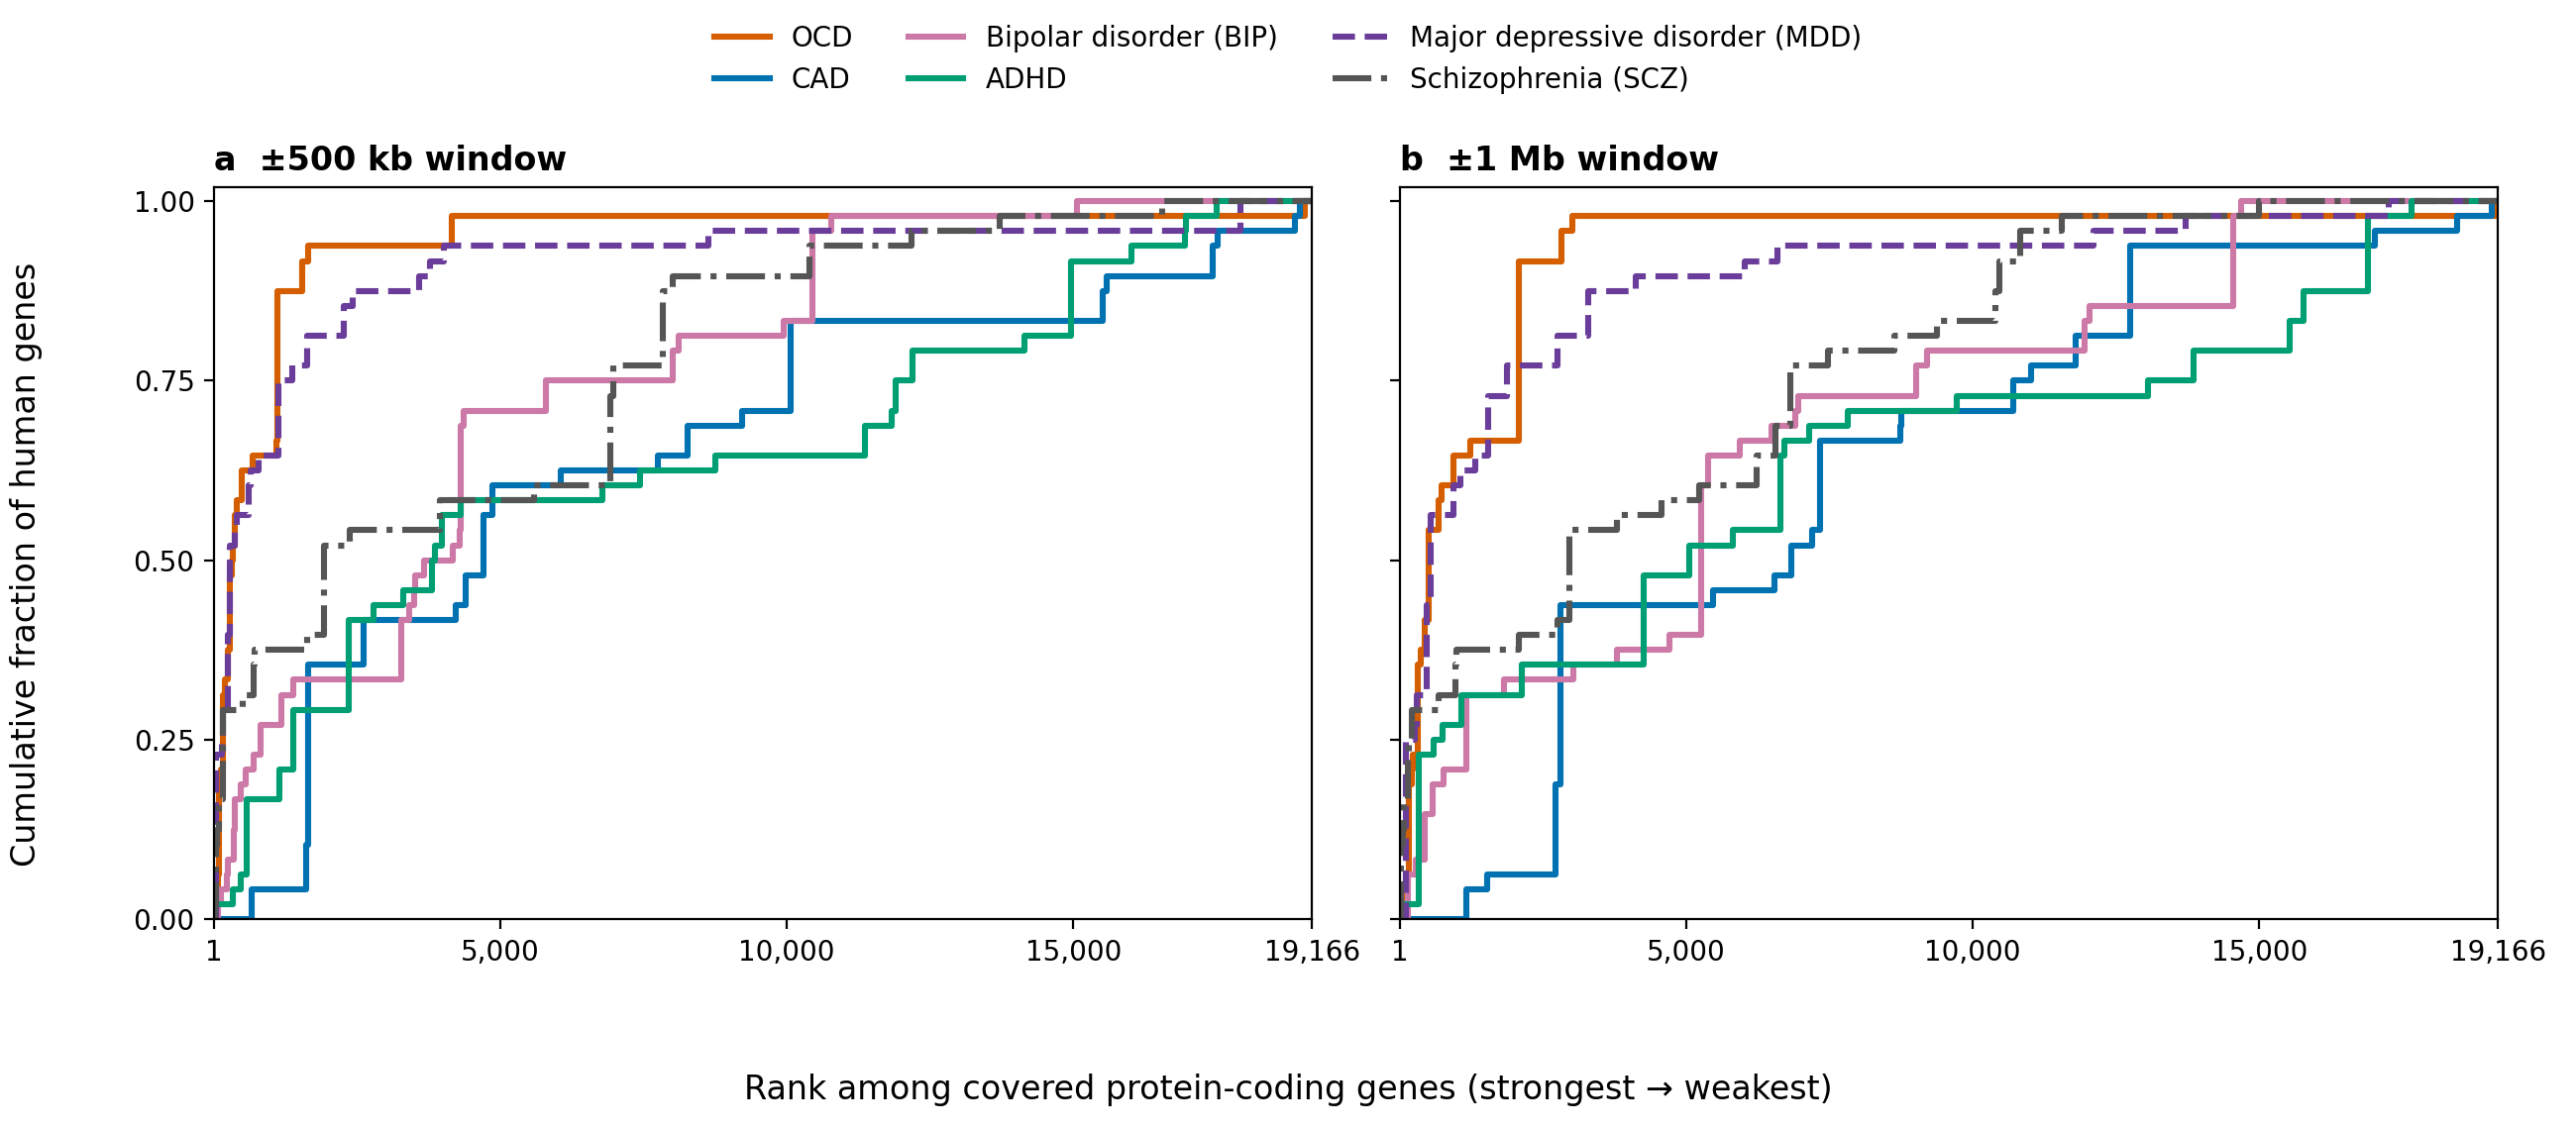

In [42]:
plot_all_trait_rank_panels(human_ranked, mask_col='human', expected_n=48,
                           gene_set='human')
display(Image(filename=str(NOTEBOOK_OUT / 'human_gene_rank_panels_all_traits.png'),
              width=1200))


#### Mann–Whitney tests

Each window table contains one row per trait for the complete 48-gene Human set.
The background excludes these 48 genes only. Holm p-values use the separate
12-test Human-set family defined above; the existing dog-set correction is unchanged.


In [43]:
def display_human_mann_whitney(window):
    table = human_mw_results.loc[human_mw_results.window.eq(window)].copy()
    order = {trait: i for i, trait in enumerate(trait_frames)}
    table = table.sort_values('trait', key=lambda values: values.map(order))
    assert len(table) == 6 and not table.trait.duplicated().any()
    stem = f'all_traits_human_mann_whitney_{window}'
    save_analysis_table(table, NOTEBOOK_OUT / f'{stem}.csv', index=False)
    columns = {
        'trait': 'Trait', 'n_human': 'Human genes', 'n_other': 'Other genes',
        'u_statistic': 'U', 'probability_human_stronger': 'P(human stronger)',
        'one_sided_p': 'One-sided p', 'holm_adjusted_p': 'Holm p',
    }
    formatted = table[list(columns)].rename(columns=columns)
    styled = style_all_traits_table(formatted,
        f'Mann–Whitney tests · ST6 Human genes · {WINDOW_LABELS[window]} TSS window', {
            'Human genes': '{:,}', 'Other genes': '{:,}', 'U': '{:,.1f}',
            'P(human stronger)': '{:.4f}', 'One-sided p': '{:.3g}', 'Holm p': '{:.3g}',
        })
    (NOTEBOOK_OUT / f'{stem}.html').write_text(styled.to_html())
    display_export(styled, stem + '_display', 'Displayed one-sided Mann–Whitney tests for all 48 ST6 Human genes against all other covered genes, across six traits at this window. P(human stronger) counts ties as one-half. Holm correction uses a separate family of 12 Human-set tests (six traits × two windows).')
    return table


human_mann_whitney_500kb = display_human_mann_whitney('500kb')
human_mann_whitney_1mb = display_human_mann_whitney('1mb')


Trait,Human genes,Other genes,U,P(human stronger),One-sided p,Holm p
OCD,48,"19,071","865,232.0",0.9452,6.97e-27,8.37e-26
CAD,48,"19,118","606,740.0",0.6612,5.59e-05,0.000224
BIP,48,"19,071","703,003.5",0.7680,6.68e-11,4.01e-10
ADHD,48,"19,078","599,417.0",0.6546,0.000106,0.000317
MDD,48,"19,067","836,085.0",0.9135,1.84e-23,1.84e-22
SCZ,48,"19,112","719,765.5",0.7846,4.51e-12,3.61e-11


Trait,Human genes,Other genes,U,P(human stronger),One-sided p,Holm p
OCD,48,"19,096","852,130.0",0.9297,3.58e-25,3.93e-24
CAD,48,"19,118","583,632.0",0.6360,0.000558,0.000558
BIP,48,"19,095","639,829.5",0.6981,1.03e-06,5.14e-06
ADHD,48,"19,097","595,213.5",0.6493,0.000172,0.000344
MDD,48,"19,088","819,892.5",0.8949,1.47e-21,1.33e-20
SCZ,48,"19,117","709,506.5",0.7732,2.9e-11,2.03e-10


#### Circular-shift tests

Each window table contains one row per trait for the complete Human set. The
test uses each gene's minimum-p percentile within chromosome and SNP-count
stratum, then independently rotates Human labels within each chromosome,
preserving their counts and gene-order pattern. It tests a lower mean percentile
rank using `(1 + number of null means ≤ observed mean) / 10,001`.

Results are computed on first use and cached with the Human gene IDs, window
scores, chromosome/TSS order, seed, shift count and implementation checksum.
`RUN_PERMUTATIONS` or `REBUILD_WINDOWS` forces recalculation. The CDF continues to
use genome-wide ranks rather than the stratified ranks used in this test.


In [44]:
human_shift_cache_path = NOTEBOOK_OUT / 'human_circular_shift_cache.json'
human_shift_cache = (json.loads(human_shift_cache_path.read_text())
                     if human_shift_cache_path.exists() else {})
human_shift_rows = []
human_method_sha256 = hashlib.sha256(
    (ROOT / 'src/human_gene_enrichment.py').read_bytes()).hexdigest()
for trait, frame in trait_frames.items():
    for window, width, suffix in WINDOWS:
        fingerprint_columns = ['gene_id', 'chrom', 'tss',
                               f'min_p{suffix}', f'n_snps{suffix}']
        fingerprint = hashlib.sha256(pd.util.hash_pandas_object(
            frame[fingerprint_columns], index=False).to_numpy().tobytes()).hexdigest()
        inputs = {'scores_sha256': fingerprint, 'human_gene_ids': sorted(human_ids),
                  'seed': SEED, 'permutations': 10_000,
                  'implementation_sha256': human_method_sha256,
                  'pandas': pd.__version__, 'numpy': np.__version__}
        key = f'{trait}_{window}'
        saved = human_shift_cache.get(key, {})
        if RUN_PERMUTATIONS or REBUILD_WINDOWS or saved.get('inputs') != inputs:
            print(f'{trait} {window}: running 10,000 Human-set circular shifts', flush=True)
            _, test = circular_shift_gene_set(frame, human_ids, n=10_000,
                p_col=f'min_p{suffix}', count_col=f'n_snps{suffix}', seed=SEED)
            human_shift_cache[key] = {'inputs': inputs, 'test': test}
        else:
            test = saved['test']
        assert test['n'] == 48 and test['permutations'] == 10_000
        human_shift_rows.append({'Trait': trait, 'Window': WINDOW_LABELS[window],
            'Human genes': test['n'], 'Mean rank': test['observed_mean_rank'],
            'Null mean rank': test['null_mean'],
            'Empirical p': test['empirical_one_sided_p'], 'Shifts': test['permutations']})
human_shift_cache_path.write_text(json.dumps(human_shift_cache, indent=2) + '\n')
human_shift_results = pd.DataFrame(human_shift_rows)
assert len(human_shift_results) == 12
save_analysis_table(human_shift_results, NOTEBOOK_OUT / 'human_circular_shift_results.csv', index=False)


def display_human_circular_shifts(window):
    table = human_shift_results.loc[
        human_shift_results.Window.eq(WINDOW_LABELS[window])].copy()
    order = {trait: i for i, trait in enumerate(trait_frames)}
    table = table.sort_values('Trait', key=lambda values: values.map(order))
    assert len(table) == 6 and not table.Trait.duplicated().any()
    stem = f'all_traits_human_circular_shifts_{window}'
    save_analysis_table(table, NOTEBOOK_OUT / f'{stem}.csv', index=False)
    styled = style_all_traits_table(table.drop(columns='Window'),
        f'Circular-shift tests · ST6 Human genes · {WINDOW_LABELS[window]} TSS window', {
            'Human genes': '{:,}', 'Mean rank': '{:.4f}', 'Null mean rank': '{:.4f}',
            'Empirical p': '{:.3g}', 'Shifts': '{:,}',
        })
    (NOTEBOOK_OUT / f'{stem}.html').write_text(styled.to_html())
    display_export(styled, stem + '_display', 'Displayed circular-shift tests of the 48 ST6 Human genes, across six traits at this window. Mean chromosome/SNP-count-stratified signal-rank percentile is compared with 10,000 within-chromosome shifts; smaller is stronger. Empirical p is one-sided with a plus-one correction and no multiple-testing adjustment.')
    return table


human_circular_shifts_500kb = display_human_circular_shifts('500kb')
human_circular_shifts_1mb = display_human_circular_shifts('1mb')


SCZ 1mb: running 10,000 Human-set circular shifts


SCZ 500kb: running 10,000 Human-set circular shifts


Trait,Human genes,Mean rank,Null mean rank,Empirical p,Shifts
OCD,48,0.1277,0.5025,0.0001,"10,000"
CAD,48,0.3897,0.5023,0.0642,"10,000"
BIP,48,0.3381,0.5032,0.0266,"10,000"
ADHD,48,0.4586,0.5030,0.266,"10,000"
MDD,48,0.1462,0.5025,0.0001,"10,000"
SCZ,48,0.3129,0.5024,0.016,"10,000"


Trait,Human genes,Mean rank,Null mean rank,Empirical p,Shifts
OCD,48,0.2174,0.5026,0.0003,"10,000"
CAD,48,0.4300,0.5021,0.184,"10,000"
BIP,48,0.4260,0.5031,0.19,"10,000"
ADHD,48,0.4647,0.5035,0.307,"10,000"
MDD,48,0.2137,0.5024,0.0003,"10,000"
SCZ,48,0.3388,0.5024,0.0292,"10,000"


### G. OCD vs. major depressive disorder (MDD)

Repeat the CAD analysis with the same 83 TOGA dog orthologs, non-dog background,
two TSS window widths, three dog sets, one-sided asymptotic Mann–Whitney tests,
rank CDF and 10,000 chromosome-wise circular shifts. Holm correction covers only the six OCD tests; this control trait reports raw p-values. OCD results repeat section A.
Source, file version and coordinate handling are documented in section 2.

#### Mann–Whitney tables

In [45]:
display_mann_whitney('OCD')
display_mann_whitney('MDD')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
±1 Mb,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
±1 Mb,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
±500 kb,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
±500 kb,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
±500 kb,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06


Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,053","405,258.0",0.4947,0.548,—
±1 Mb,suggestive,40,"19,053","370,030.0",0.4855,0.624,—
±1 Mb,combined,83,"19,053","775,288.0",0.4903,0.621,—
±500 kb,significant,43,"19,032","430,890.0",0.5265,0.274,—
±500 kb,suggestive,40,"19,032","408,960.0",0.5372,0.208,—
±500 kb,combined,83,"19,032","839,850.0",0.5317,0.159,—


#### Cumulative gene-rank distributions: four lines plus diagonal

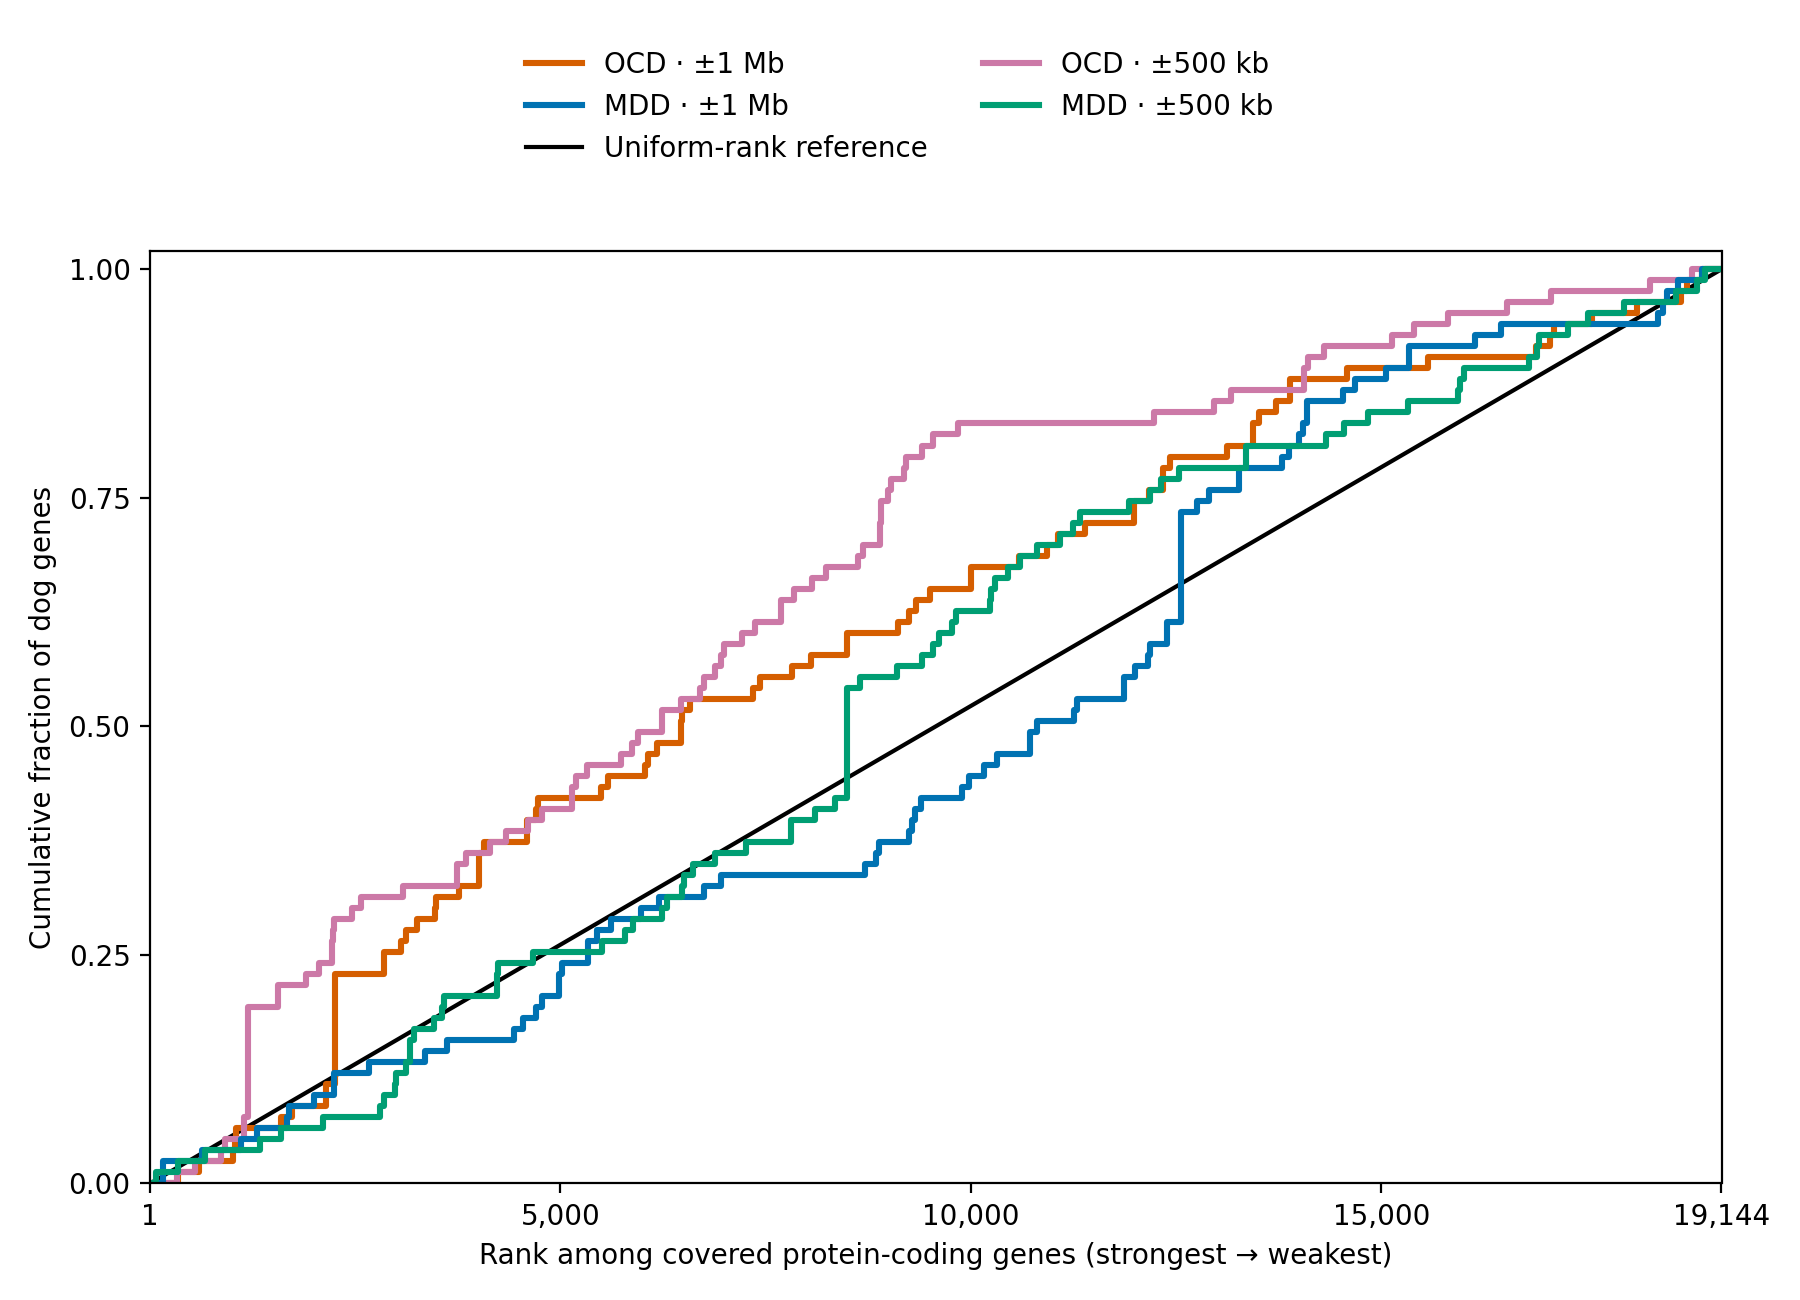

In [46]:
plot_rank_overlay(ranked, comparison_trait='MDD',
                  filename='dog_gene_rank_overlay_ocd_mdd.png')
display(Image(filename=str(NOTEBOOK_OUT / 'dog_gene_rank_overlay_ocd_mdd.png'), width=900))

#### Circular-shift results

In [47]:
display_permutations(['OCD', 'MDD'])

Trait,Window,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Permutations
OCD,±1 Mb,combined,83,0.4212,0.5028,0.0391,10000
OCD,±1 Mb,significant,43,0.3968,0.5035,0.0872,10000
OCD,±500 kb,combined,83,0.3548,0.5025,0.0003,10000
OCD,±500 kb,significant,43,0.3465,0.5040,0.0132,10000
MDD,±1 Mb,combined,83,0.4903,0.5035,0.392,10000
MDD,±1 Mb,significant,43,0.4607,0.5040,0.303,10000
MDD,±500 kb,combined,83,0.4652,0.5033,0.217,10000
MDD,±500 kb,significant,43,0.4533,0.5039,0.27,10000


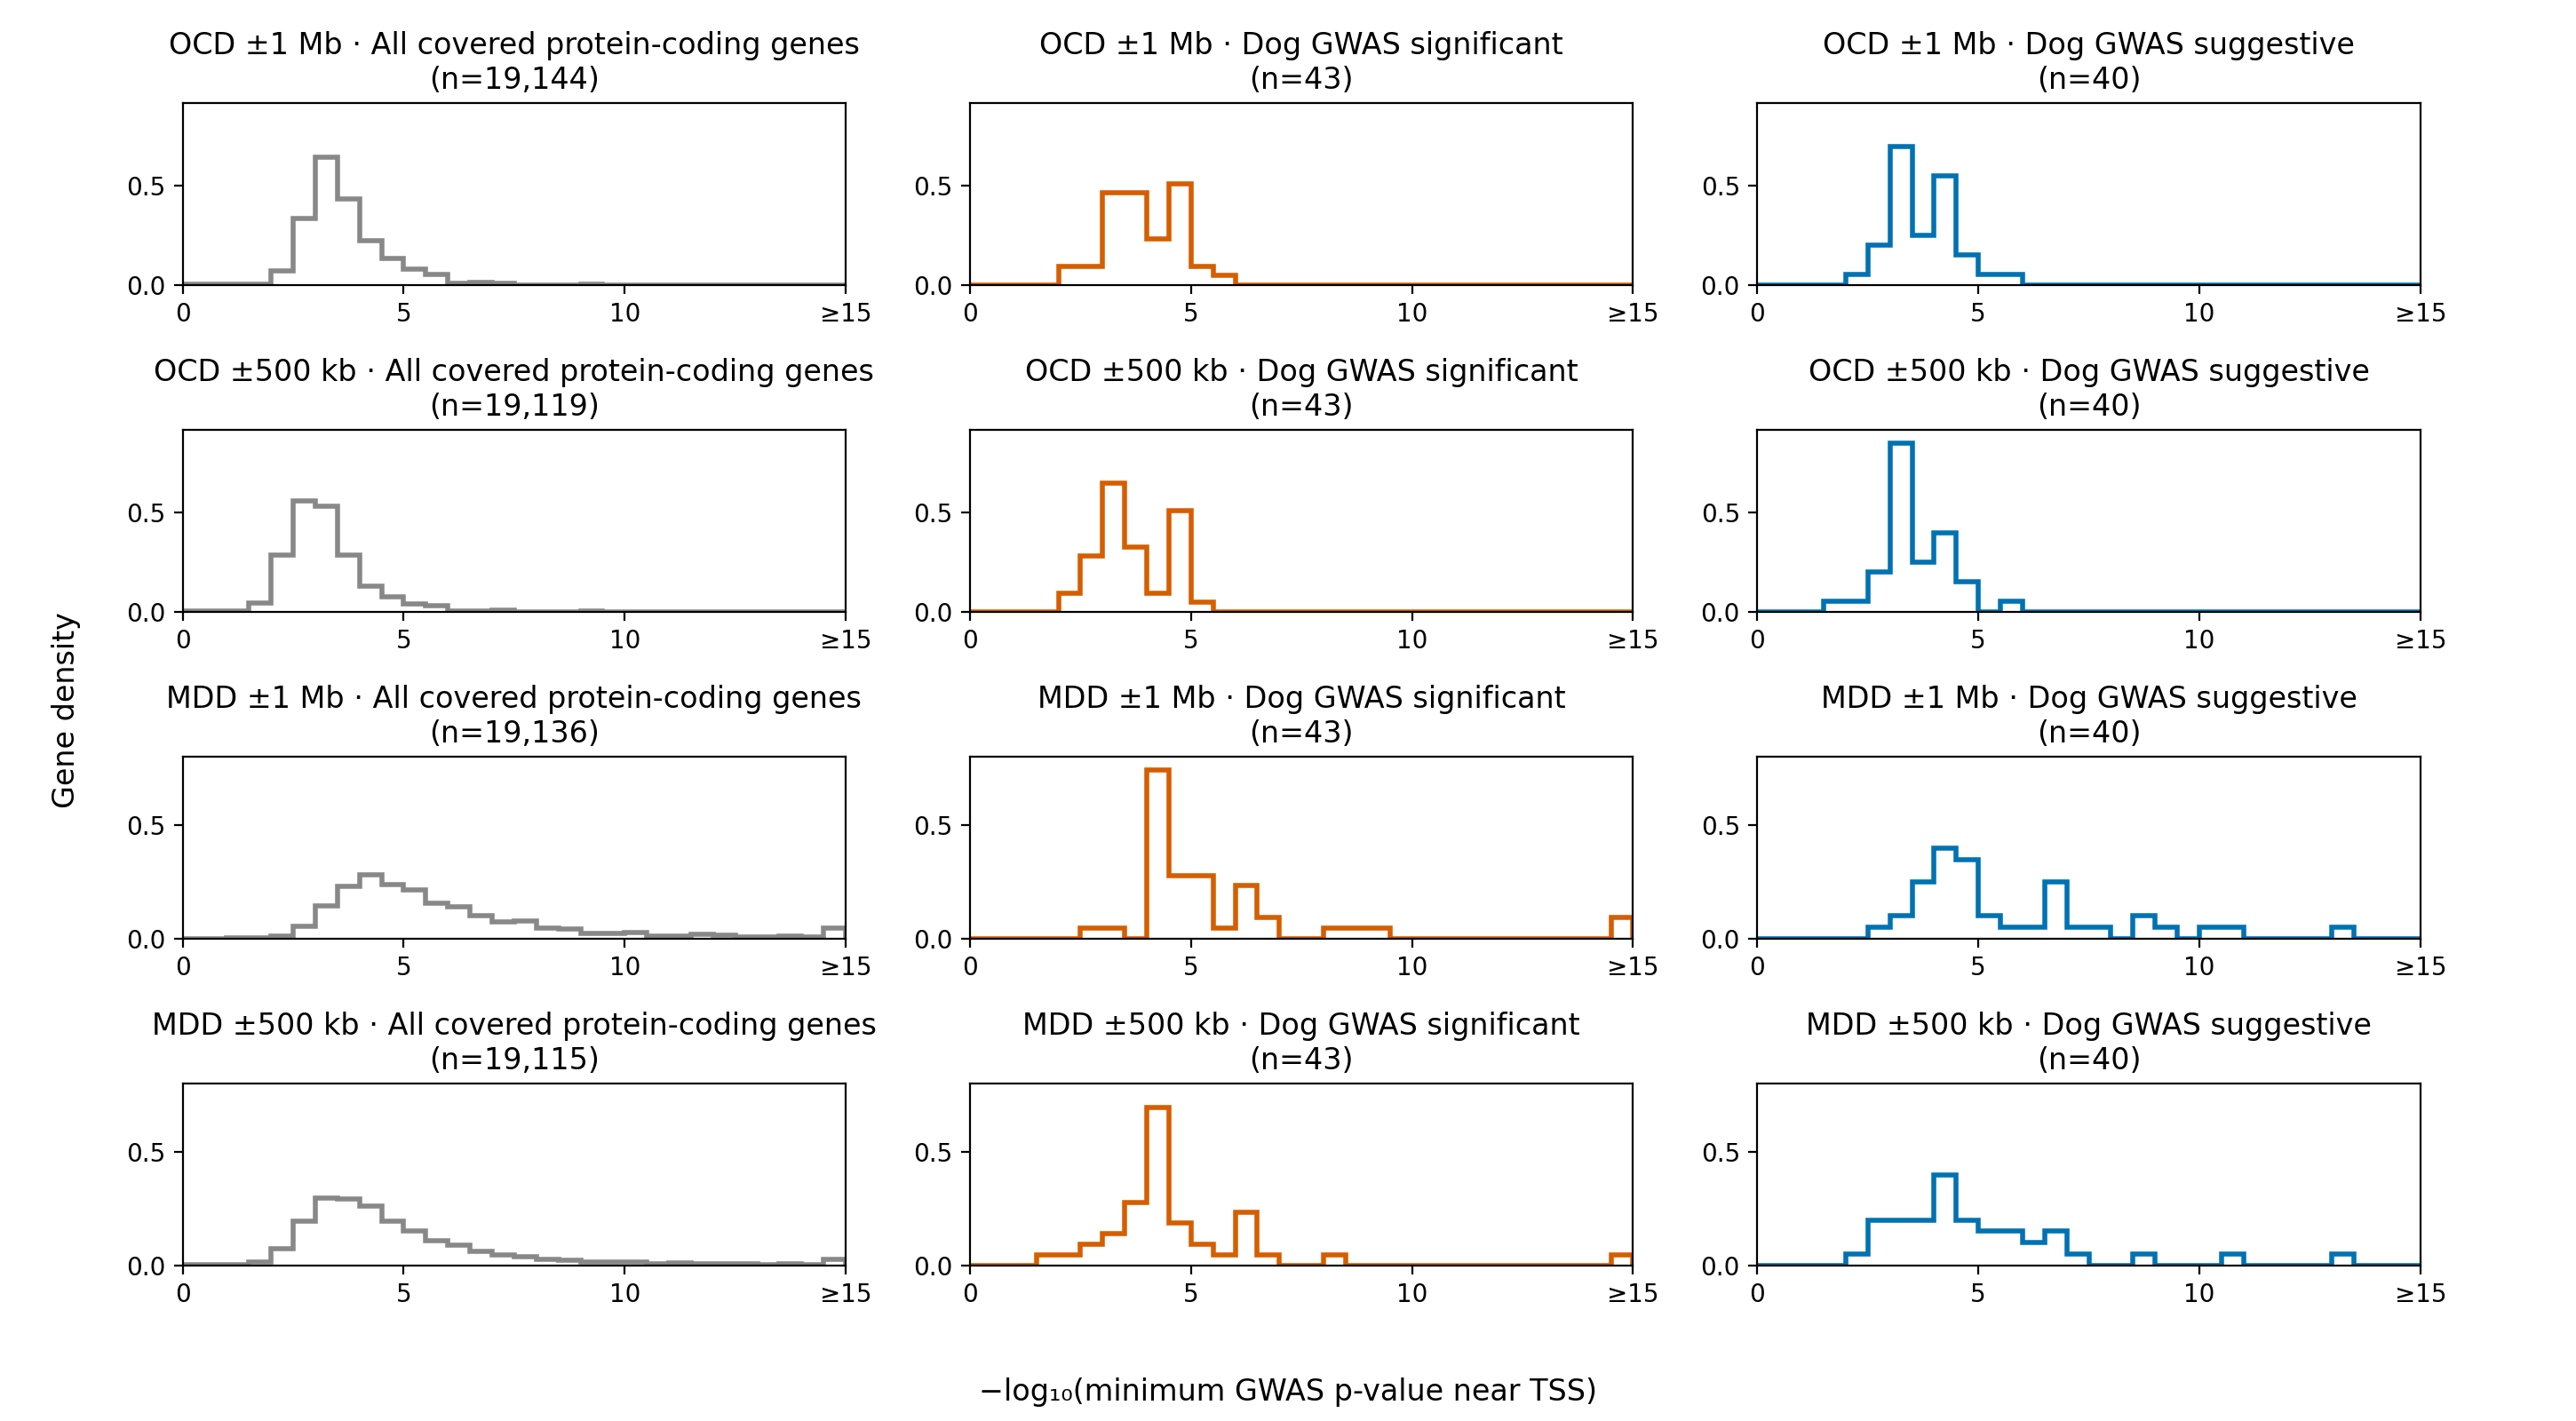

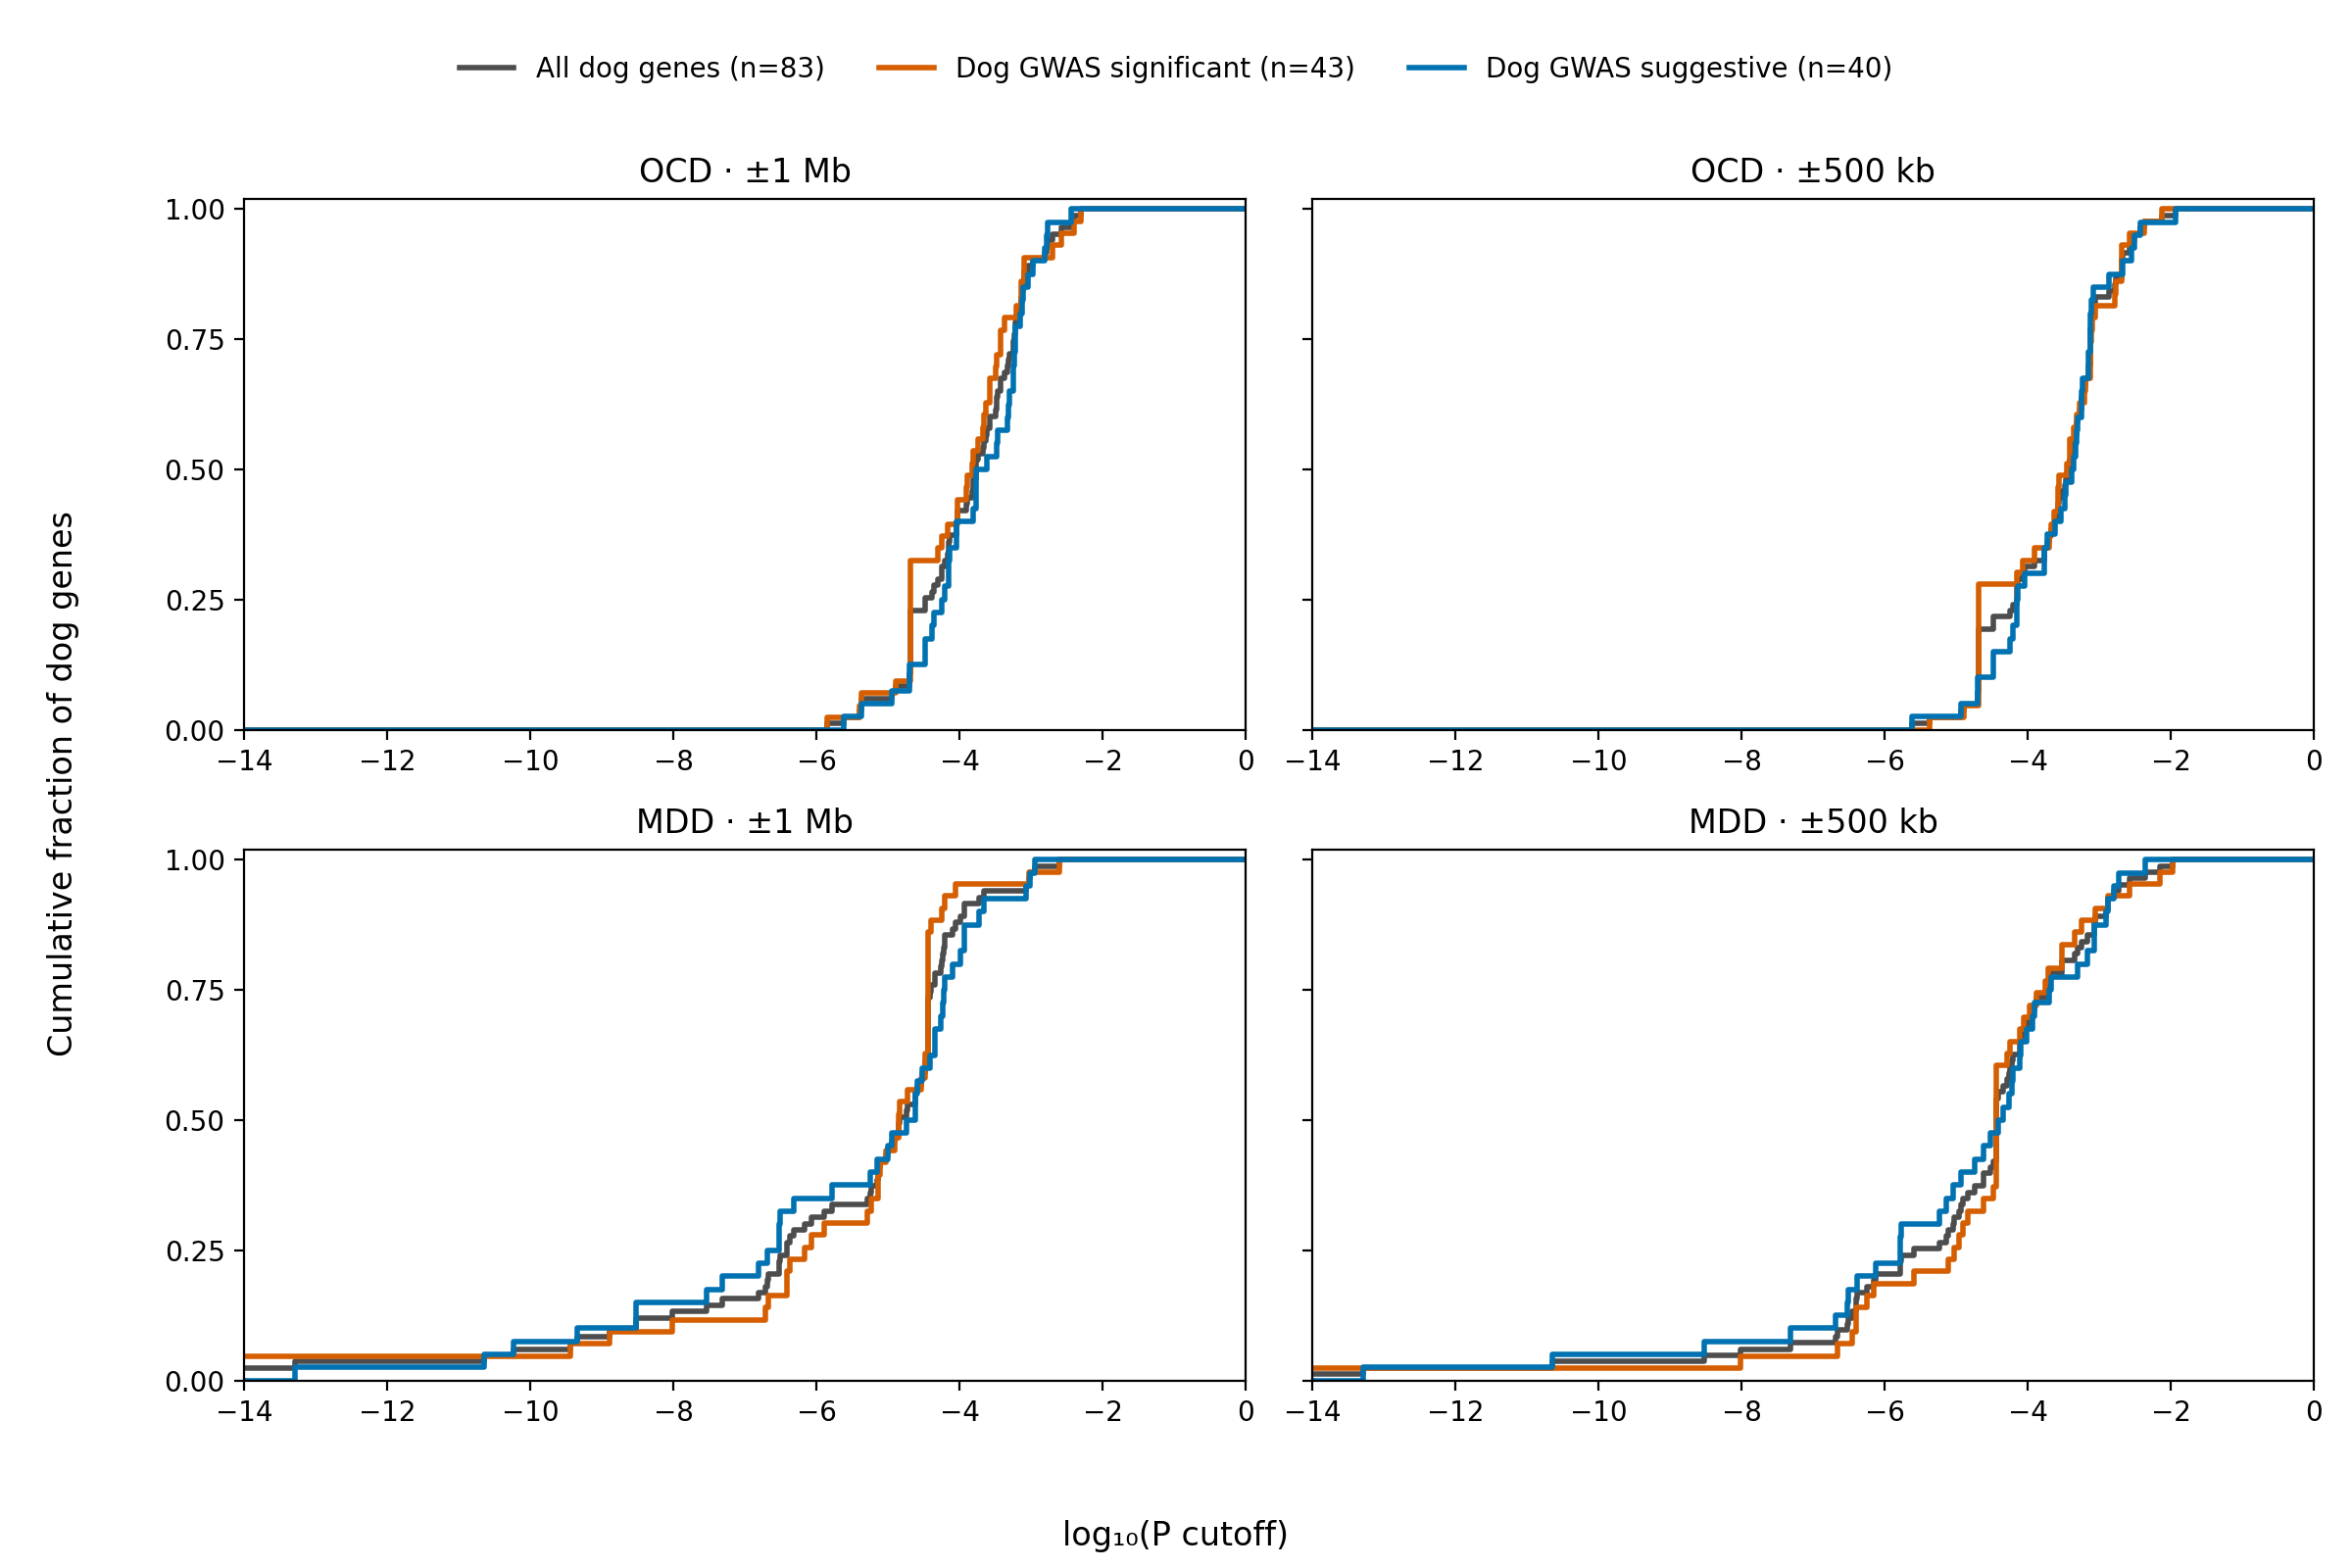

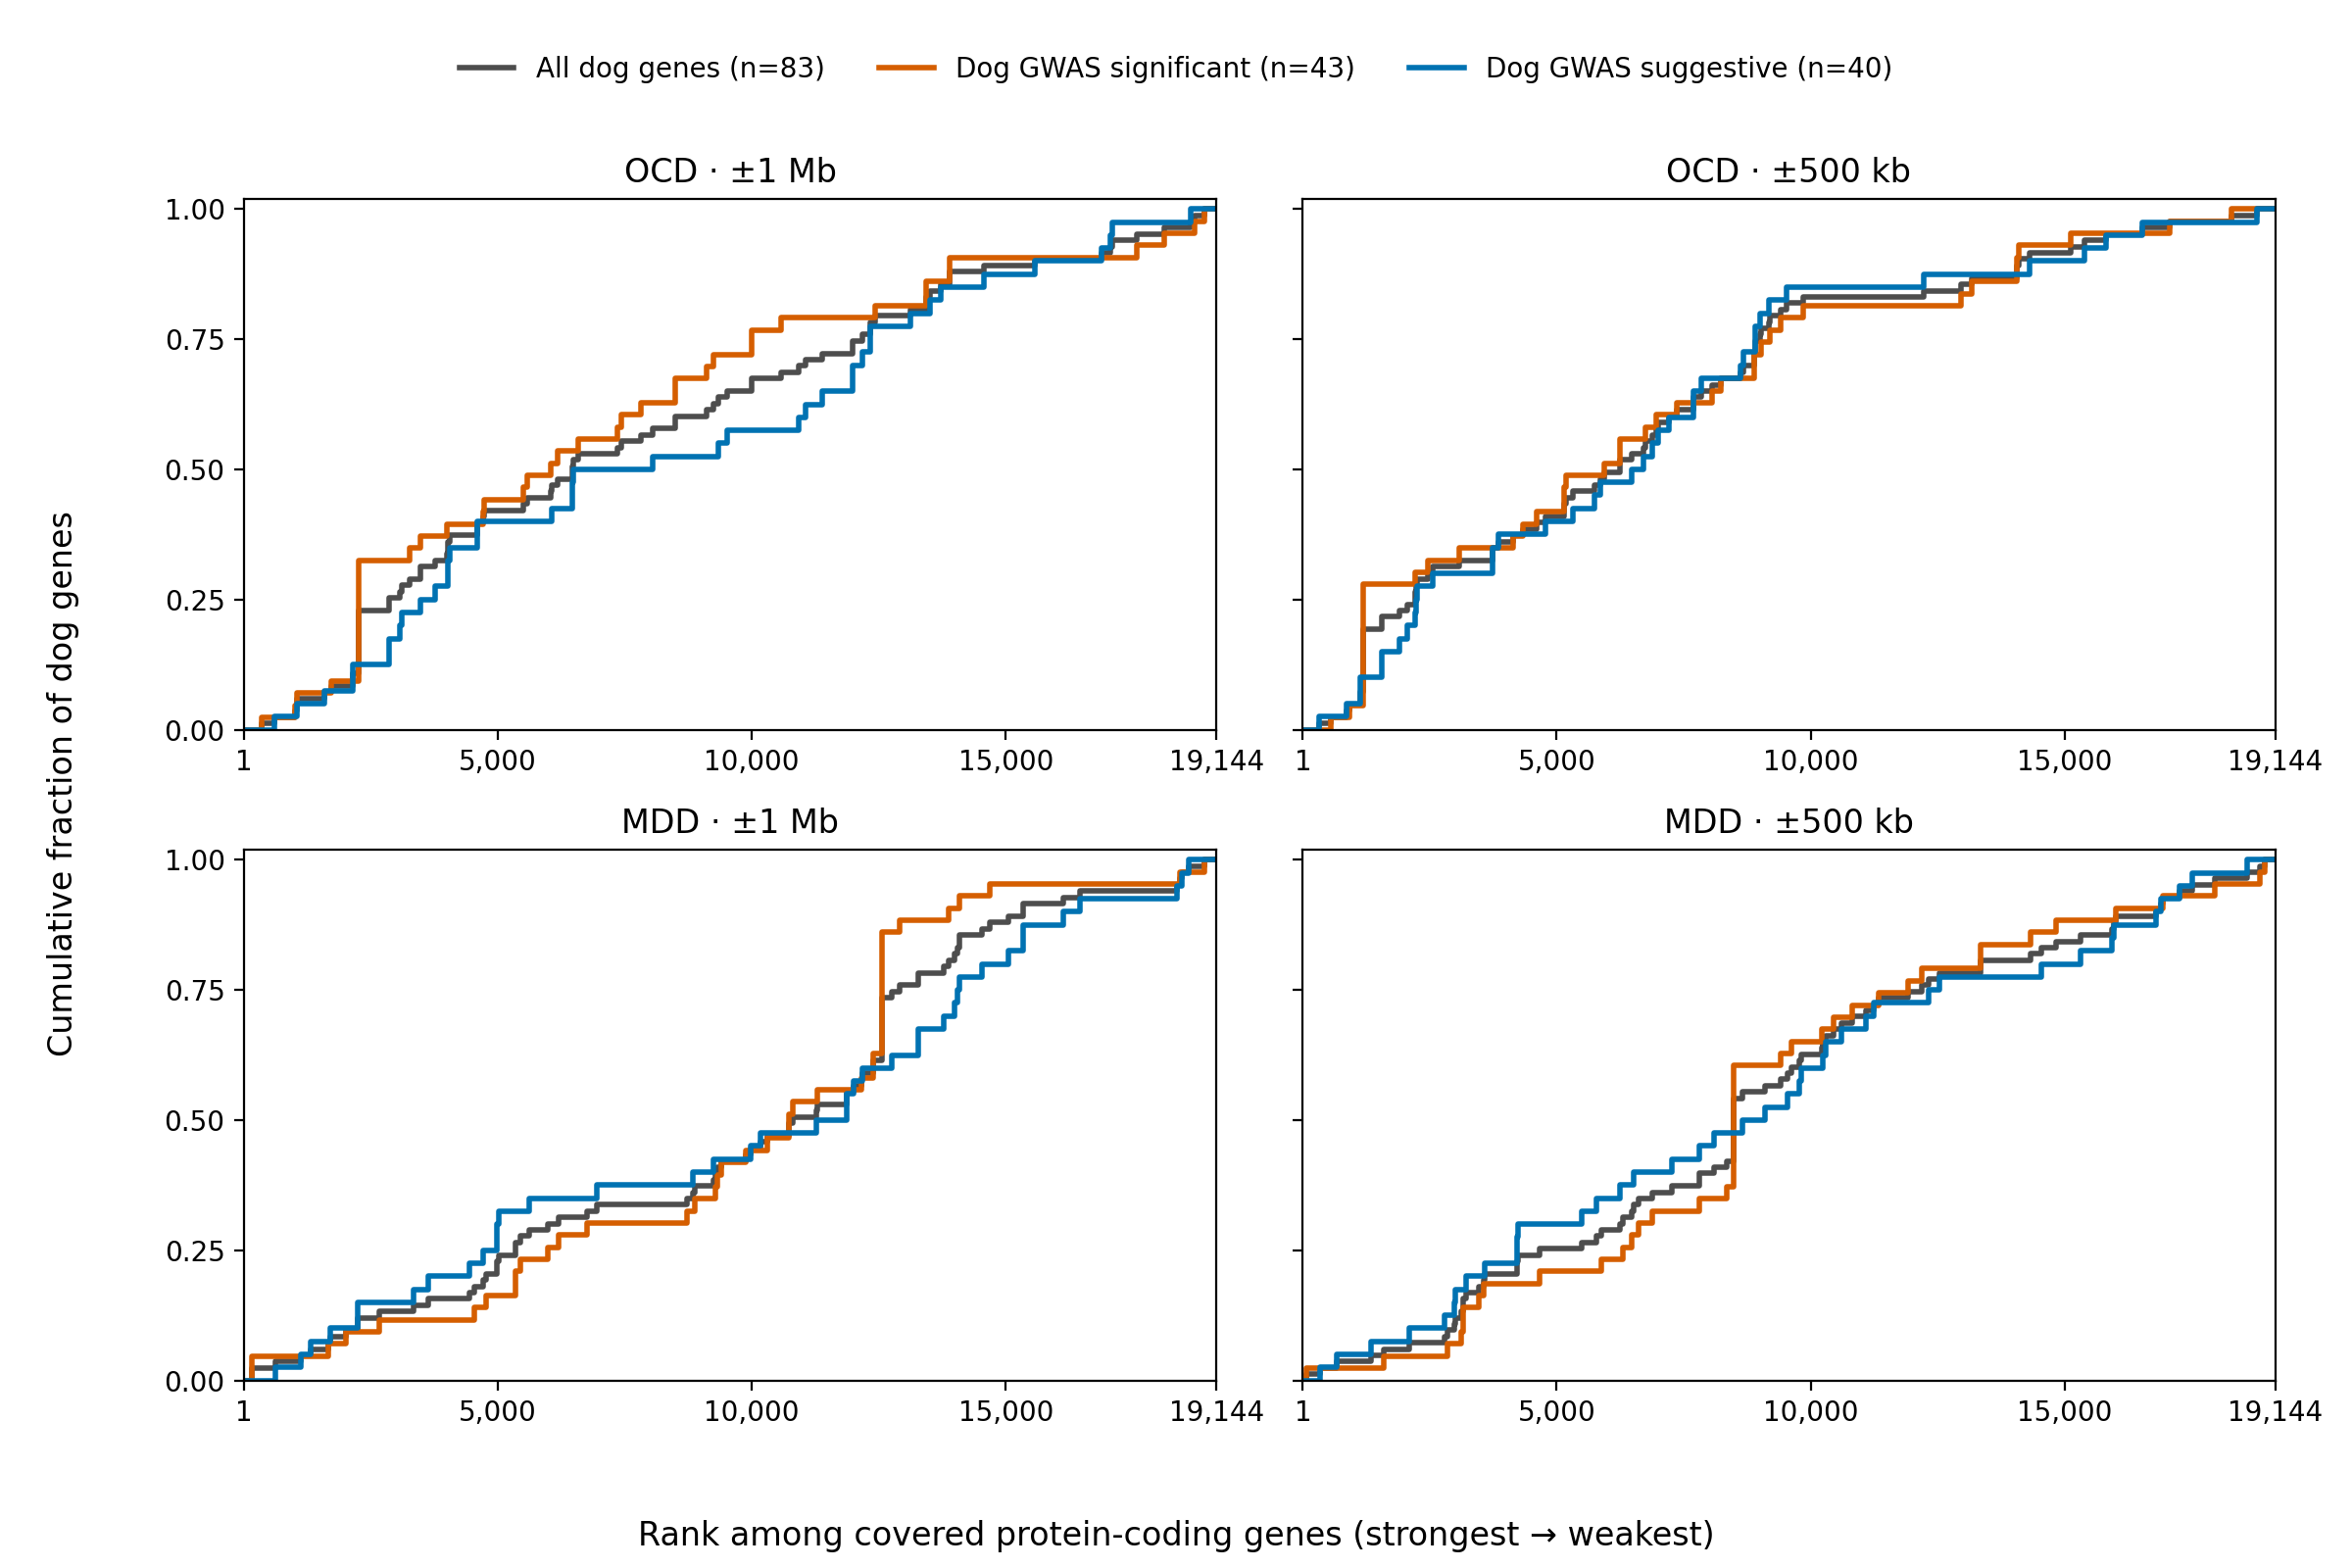

In [48]:
show_additional_comparison('MDD')

### H. OCD vs. schizophrenia (SCZ)

Repeat the CAD analysis with the same 83 TOGA dog orthologs, non-dog background,
two TSS window widths, three dog sets, one-sided asymptotic Mann–Whitney tests,
rank CDF and 10,000 chromosome-wise circular shifts. Holm correction covers only the six OCD tests; this control trait reports raw p-values. OCD results repeat section A.
Source, file version and coordinate handling are documented in section 2.

#### Mann–Whitney tables

In [49]:
display_mann_whitney('OCD')
display_mann_whitney('SCZ')

Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,061","515,725.5",0.6292,0.00168,0.00337
±1 Mb,suggestive,40,"19,061","429,582.5",0.5634,0.0825,0.0825
±1 Mb,combined,83,"19,061","945,308.0",0.5975,0.00107,0.0032
±500 kb,significant,43,"19,036","540,639.0",0.6605,0.000136,0.000678
±500 kb,suggestive,40,"19,036","496,939.0",0.6526,0.000418,0.00167
±500 kb,combined,83,"19,036","1,037,578.0",0.6567,4.02e-07,2.41e-06


Window,Dog set,Dog genes,Non-dog genes,U,P(dog stronger),One-sided p,Holm p
±1 Mb,significant,43,"19,082","466,126.5",0.5681,0.0612,—
±1 Mb,suggestive,40,"19,082","397,414.5",0.5207,0.326,—
±1 Mb,combined,83,"19,082","863,541.0",0.5452,0.0772,—
±500 kb,significant,43,"19,077","478,774.5",0.5836,0.0289,—
±500 kb,suggestive,40,"19,077","375,213.0",0.4917,0.572,—
±500 kb,combined,83,"19,077","853,987.5",0.5393,0.108,—


#### Cumulative gene-rank distributions: four lines plus diagonal

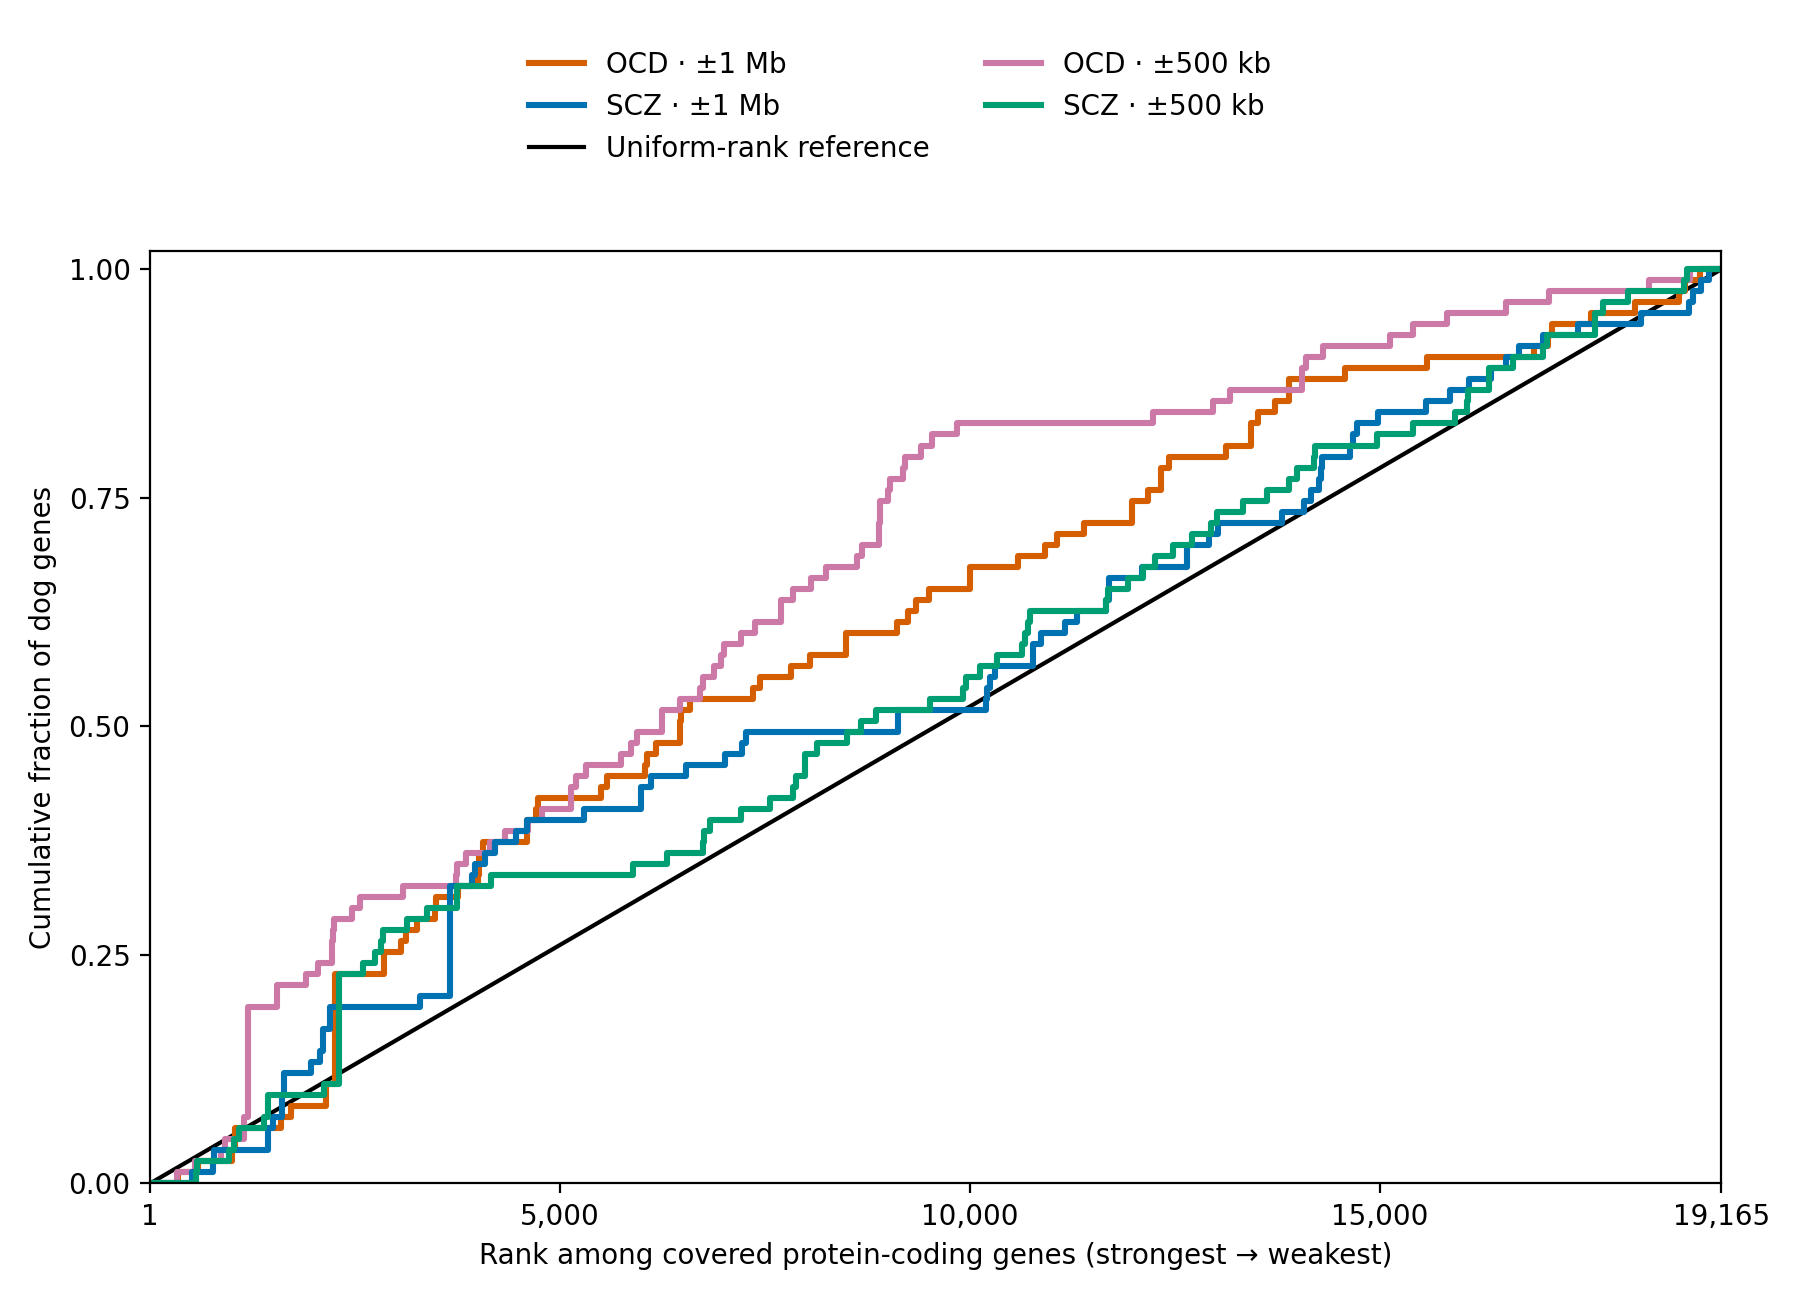

In [50]:
plot_rank_overlay(ranked, comparison_trait='SCZ',
                  filename='dog_gene_rank_overlay_ocd_scz.png')
display(Image(filename=str(NOTEBOOK_OUT / 'dog_gene_rank_overlay_ocd_scz.png'), width=900))

#### Circular-shift results

In [51]:
display_permutations(['OCD', 'SCZ'])

Trait,Window,Dog set,Dog genes,Mean rank,Null mean rank,Empirical p,Permutations
OCD,±1 Mb,combined,83,0.4212,0.5028,0.0391,10000
OCD,±1 Mb,significant,43,0.3968,0.5035,0.0872,10000
OCD,±500 kb,combined,83,0.3548,0.5025,0.0003,10000
OCD,±500 kb,significant,43,0.3465,0.5040,0.0132,10000
SCZ,±1 Mb,combined,83,0.4523,0.5032,0.155,10000
SCZ,±1 Mb,significant,43,0.4407,0.5044,0.229,10000
SCZ,±500 kb,combined,83,0.4669,0.5034,0.232,10000
SCZ,±500 kb,significant,43,0.4358,0.5038,0.204,10000


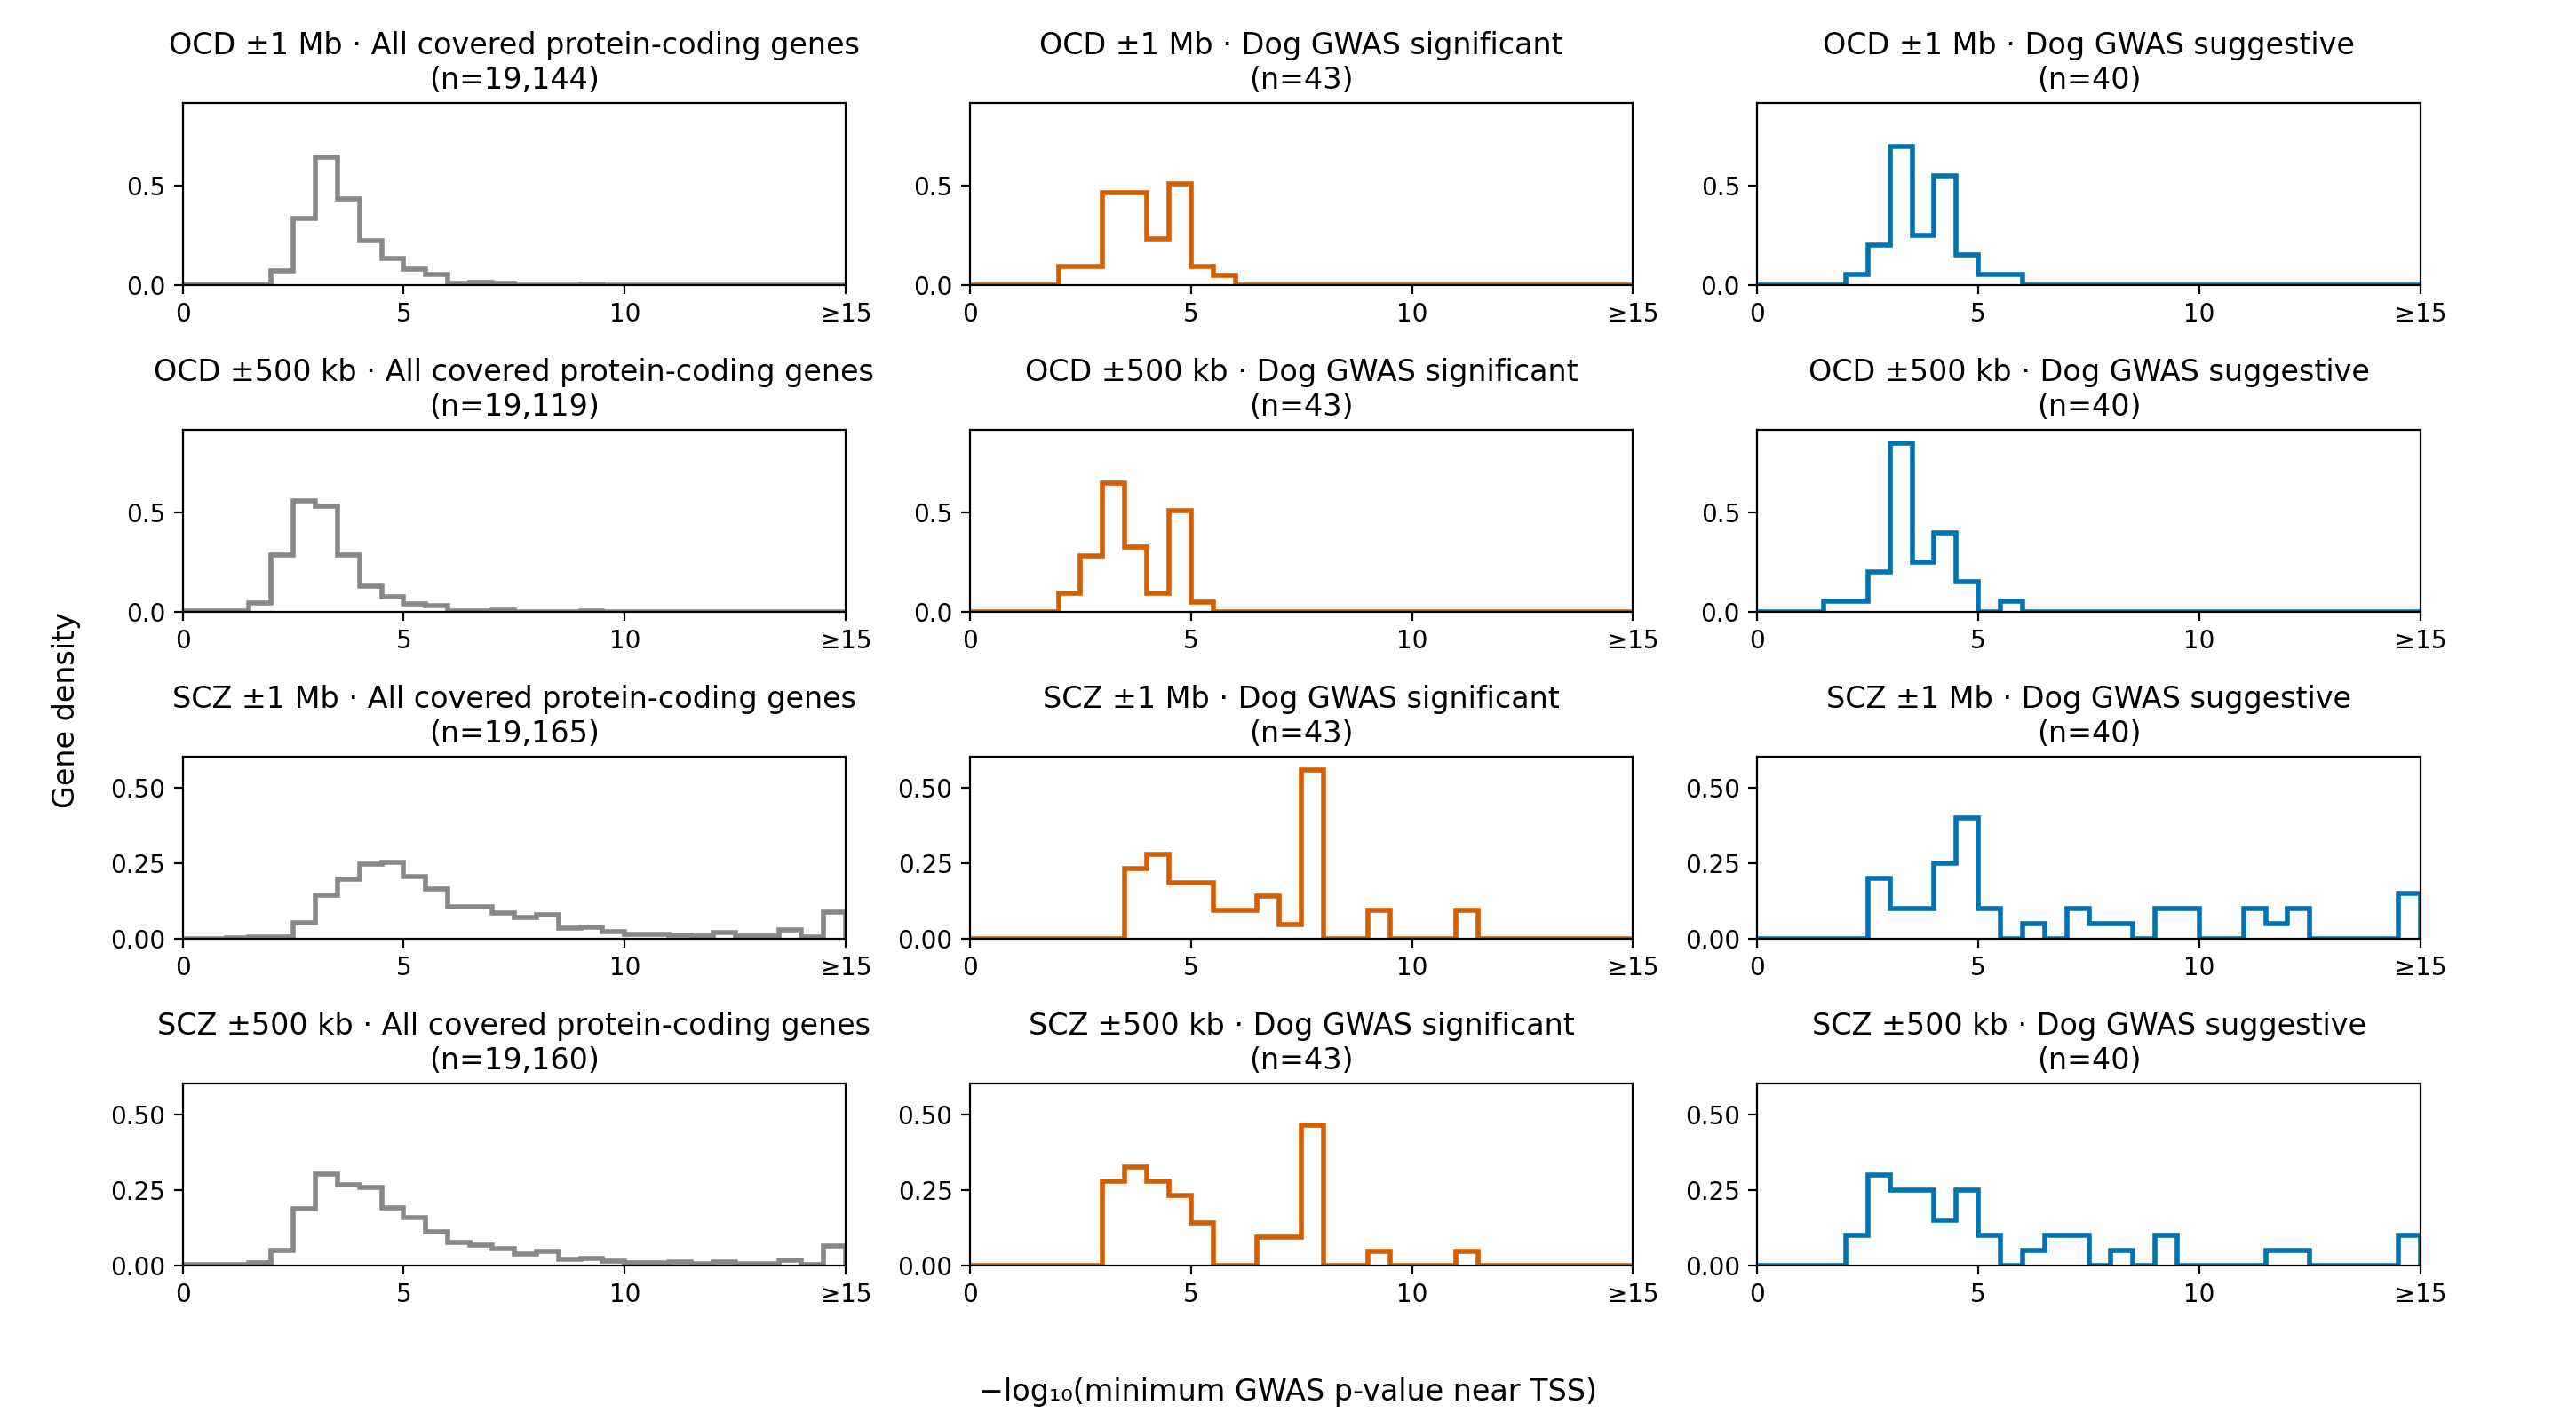

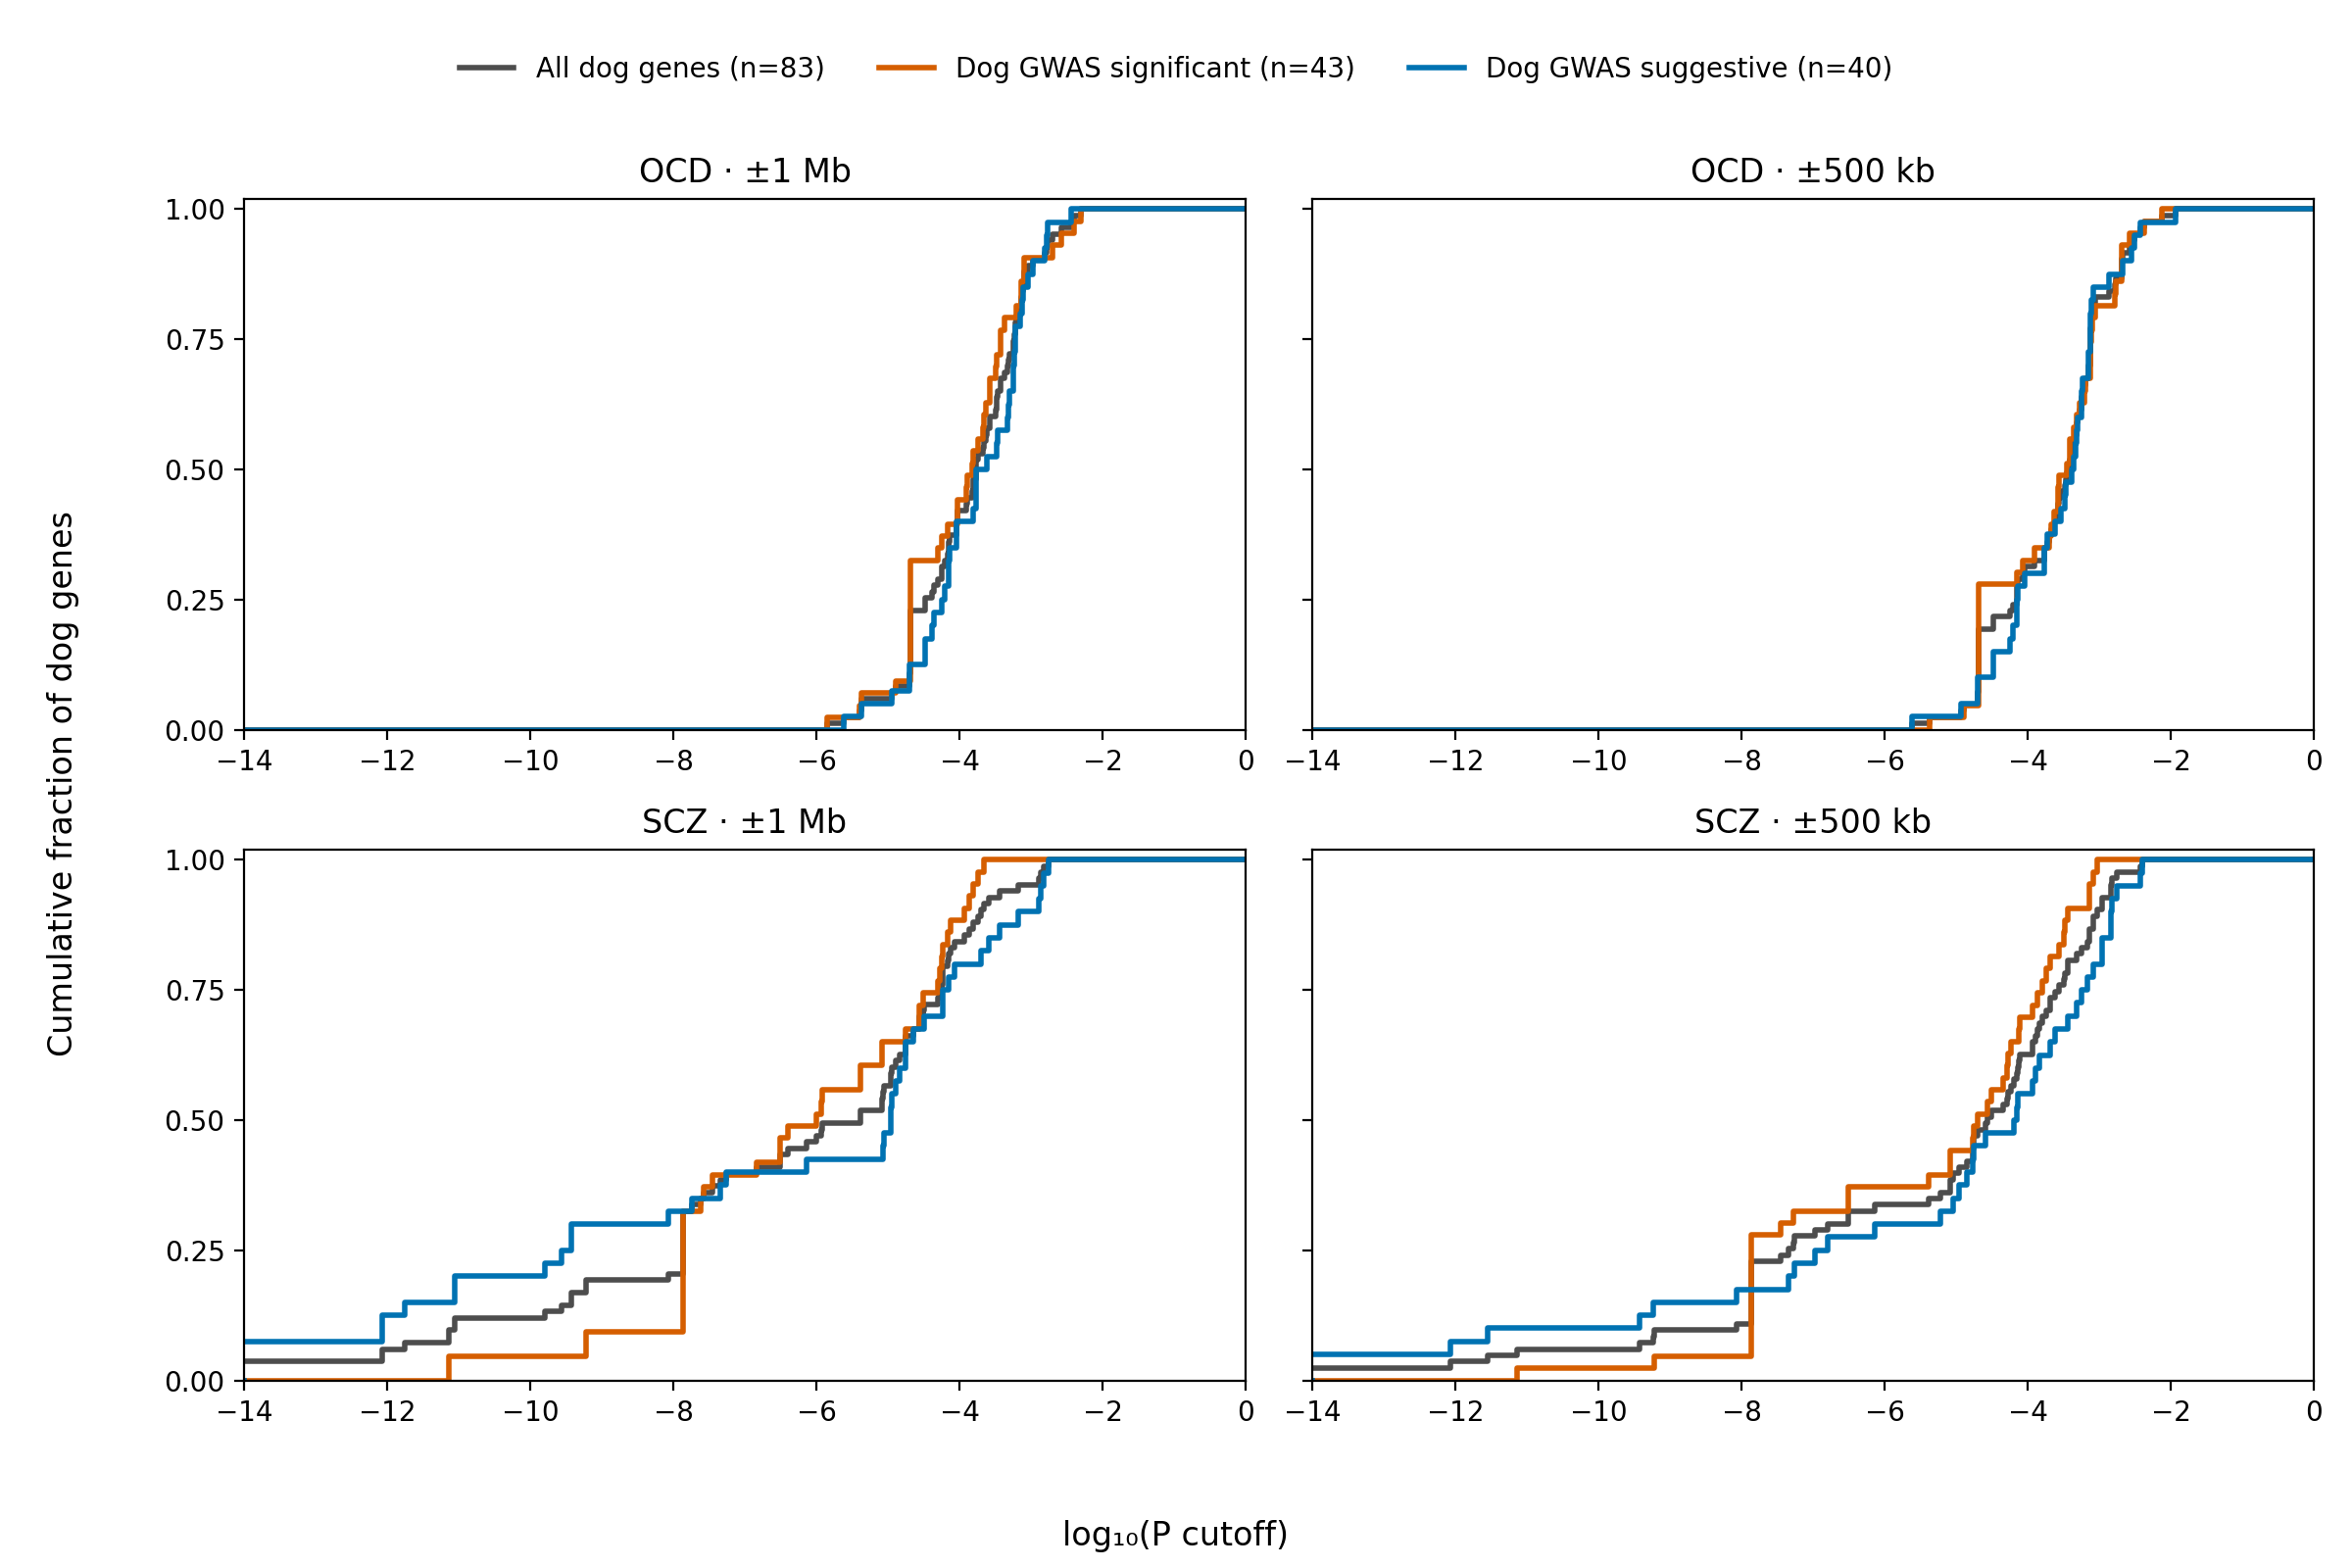

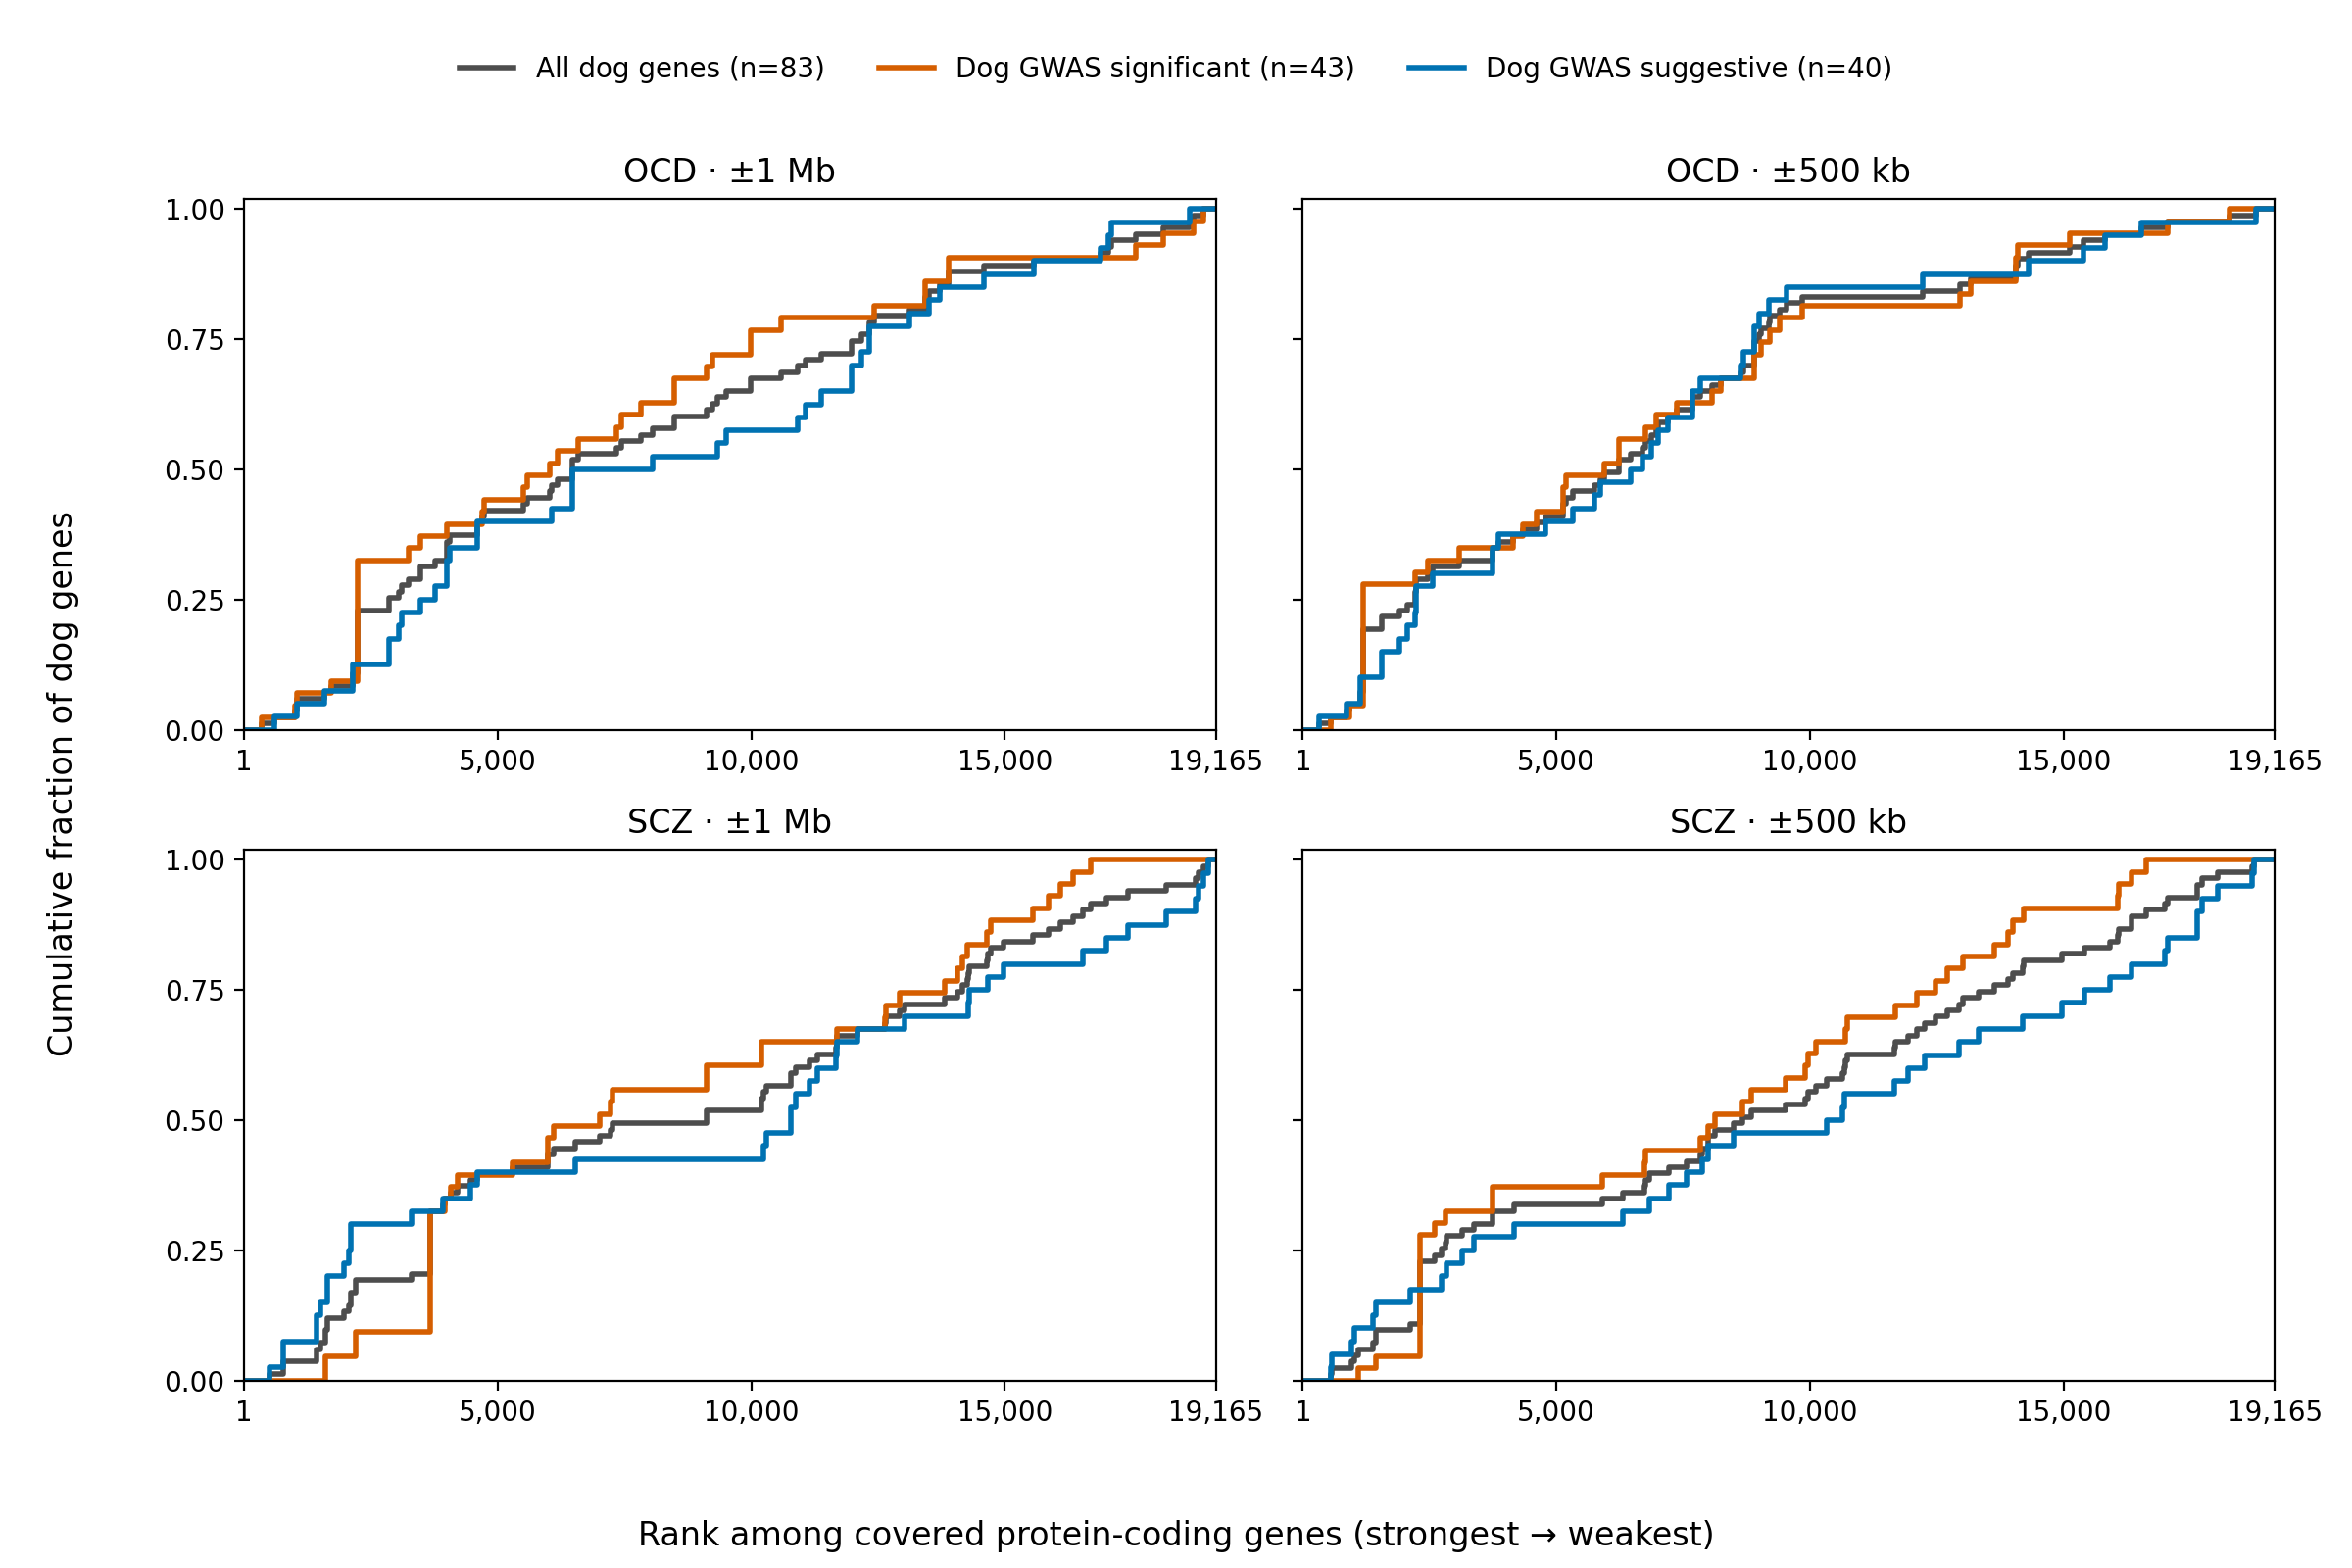

In [52]:
show_additional_comparison('SCZ')

## 5. Constraint of dog and human OCD genes

Use all **87 dog and 48 human genes** in supplementary table ST6. These labels
identify the source gene set; both groups use **human** Agarwal s_het estimates.
The 83-gene TOGA restriction used in the GWAS enrichment sections is not applied here.
COL6A5 has no Agarwal posterior and remains missing, leaving 86 dog and 48 human genes.

The [Agarwal source repository](https://github.com/agarwal-i/loss-of-function-fitness-effects)
provides densities on a grid in x = log10(s_het). Approximate each posterior mean
as ∫10^x f(x) dx / ∫f(x) dx using trapezoidal integration over the supplied grid
[-7, 0]. Rank all available genes together by this mean, with rank 1 highest
and average ranks for ties. The single two-sided asymptotic Mann–Whitney test
uses tie and continuity corrections. Posterior uncertainty is not propagated
through this comparison of point estimates.

The plot uses log10 of the posterior mean on the y-axis and the existing
minimum OCD p-value in the inclusive ±500 kb TSS window on the x-axis.
The reproducible script and mapping audit are in `src/compare_shet.py` and
`notebook/results/shet/`. Input posteriors are read from
`~/data/constraint/shet/agarwal/`.

Blue and orange squares mark the dog and human group medians. Medians are computed from the raw window p-values and posterior mean s_het estimates among plotted genes, then transformed to the displayed axes.

Dog points are dark blue for significant and light blue for suggestive dog
GWAS genes, using the ST6 `dogCD significance` column; human points are orange.
The dog median square summarizes both dog categories. The pooled best-fit
line uses ordinary least squares with an intercept across all 134 individual
genes in the displayed log-transformed coordinates. The median squares are
not additional observations. Its slope is printed on the plot, and full
regression coefficients are saved in `notebook/results/shet/shet_pooled_regression.csv`.


Marginal density panels compare all plotted dog genes combined (blue, n = 86)
against human genes (orange, n = 48). The upper panel shares the scatter
plot's -log10(P) axis; the right panel shares its log10(s_het) axis. Gaussian
kernel density estimates use Scott's bandwidth rule separately for each
group, with equal weight per gene in the displayed transformed coordinates.
They describe the distribution of gene-level point estimates, not pooled
posterior densities. Curves are saved in `shet_marginal_densities.csv`.


In [53]:
from src.compare_shet import main as compare_shet

shet_genes, shet_statistics = compare_shet(
    pdf_path=PLOTS_DIR / 'shet_vs_ocd_500kb.pdf')
write_plot_explanation(PLOTS_DIR / 'shet_vs_ocd_500kb.pdf')
for csv_path in sorted((OUT / 'shet').glob('*.csv')):
    export_table(pd.read_csv(csv_path), PLOTS_DIR, csv_path.stem,
                 saved_table_explanation(csv_path.stem))


Pooled OLS: slope = -0.031298; intercept = -1.504288; n = 134


All ST6 genes: 87 Dog + 48 Human; human s_het estimates for both groups.
Rank 1 = highest posterior mean s_het; average ranks for ties.
 n_dog  n_human  U_dog  p_two_sided  probability_dog_greater  median_shet_dog  median_shet_human  median_rank_dog  median_rank_human                                                             method  n_plotted missing_shet_genes
    86       48 2268.0     0.345007                 0.549419         0.041542           0.011433             64.5               78.5 two-sided asymptotic Mann-Whitney U; tie and continuity correction        134           [COL6A5]

Ranked genes:
 shet_rank st6_symbol group  shet_posterior_mean  log10_shet  min_p_500kb
       1.0      GRIA1   Dog             0.364472   -0.438336 7.006000e-04
       2.0      NTRK2   Dog             0.362153   -0.441108 8.391000e-05
       3.0     ZDHHC5 Human             0.359525   -0.444271 2.807000e-07
       4.0      ARIH2 Human             0.343398   -0.464202 1.927000e-05
       5.0       CD

In [54]:
display_export(pd.DataFrame([shet_statistics]), 'shet_statistics_display', 'Constraint-analysis statistics comparing all ST6 Dog and Human genes using human Agarwal posterior mean s_het. COL6A5 lacks an estimate, leaving 86 Dog and 48 Human genes. The group test is two-sided asymptotic Mann–Whitney with tie and continuity corrections. Posterior uncertainty is not propagated. Nested statistics, when present, are serialized in individual cells.')
display_export(shet_genes[["shet_rank", "st6_symbol", "group", "shet_posterior_mean",
                    "log10_shet", "min_p_500kb", "shet_status"]], 'shet_gene_ranks_display', 'ST6 genes ranked together by human Agarwal posterior mean s_het, highest first with average ties. All 87 Dog and 48 Human genes are retained; COL6A5 lacks an estimate. min_p_500kb is the minimum human OCD SNP p-value within ±500 kb of the TSS. Both groups use human constraint estimates, before the dog-set TOGA restriction.')

,n_dog,n_human,U_dog,p_two_sided,probability_dog_greater,median_shet_dog,median_shet_human,median_rank_dog,median_rank_human,method,n_plotted,missing_shet_genes
0,86,48,2268.0,0.345007,0.549419,0.041542,0.011433,64.5,78.5,two-sided asymptotic Mann-Whitney U; tie and c...,134,[COL6A5]


,shet_rank,st6_symbol,group,shet_posterior_mean,log10_shet,min_p_500kb,shet_status
47,1.0,GRIA1,Dog,0.364472,-0.438336,7.006000e-04,available
79,2.0,NTRK2,Dog,0.362153,-0.441108,8.391000e-05,available
128,3.0,ZDHHC5,Human,0.359525,-0.444271,2.807000e-07,available
9,4.0,ARIH2,Human,0.343398,-0.464202,1.927000e-05,available
23,5.0,CDH8,Dog,0.323967,-0.489499,4.280000e-06,available
...,...,...,...,...,...,...,...
21,131.0,CD34,Dog,0.001212,-2.916332,7.387000e-04,available
134,132.0,ZWINT,Dog,0.001000,-2.999912,4.801000e-04,available
28,133.0,CNGB1,Dog,0.000855,-3.067983,5.802000e-04,available
125,134.0,XPNPEP3,Human,0.000790,-3.102177,1.645000e-06,available


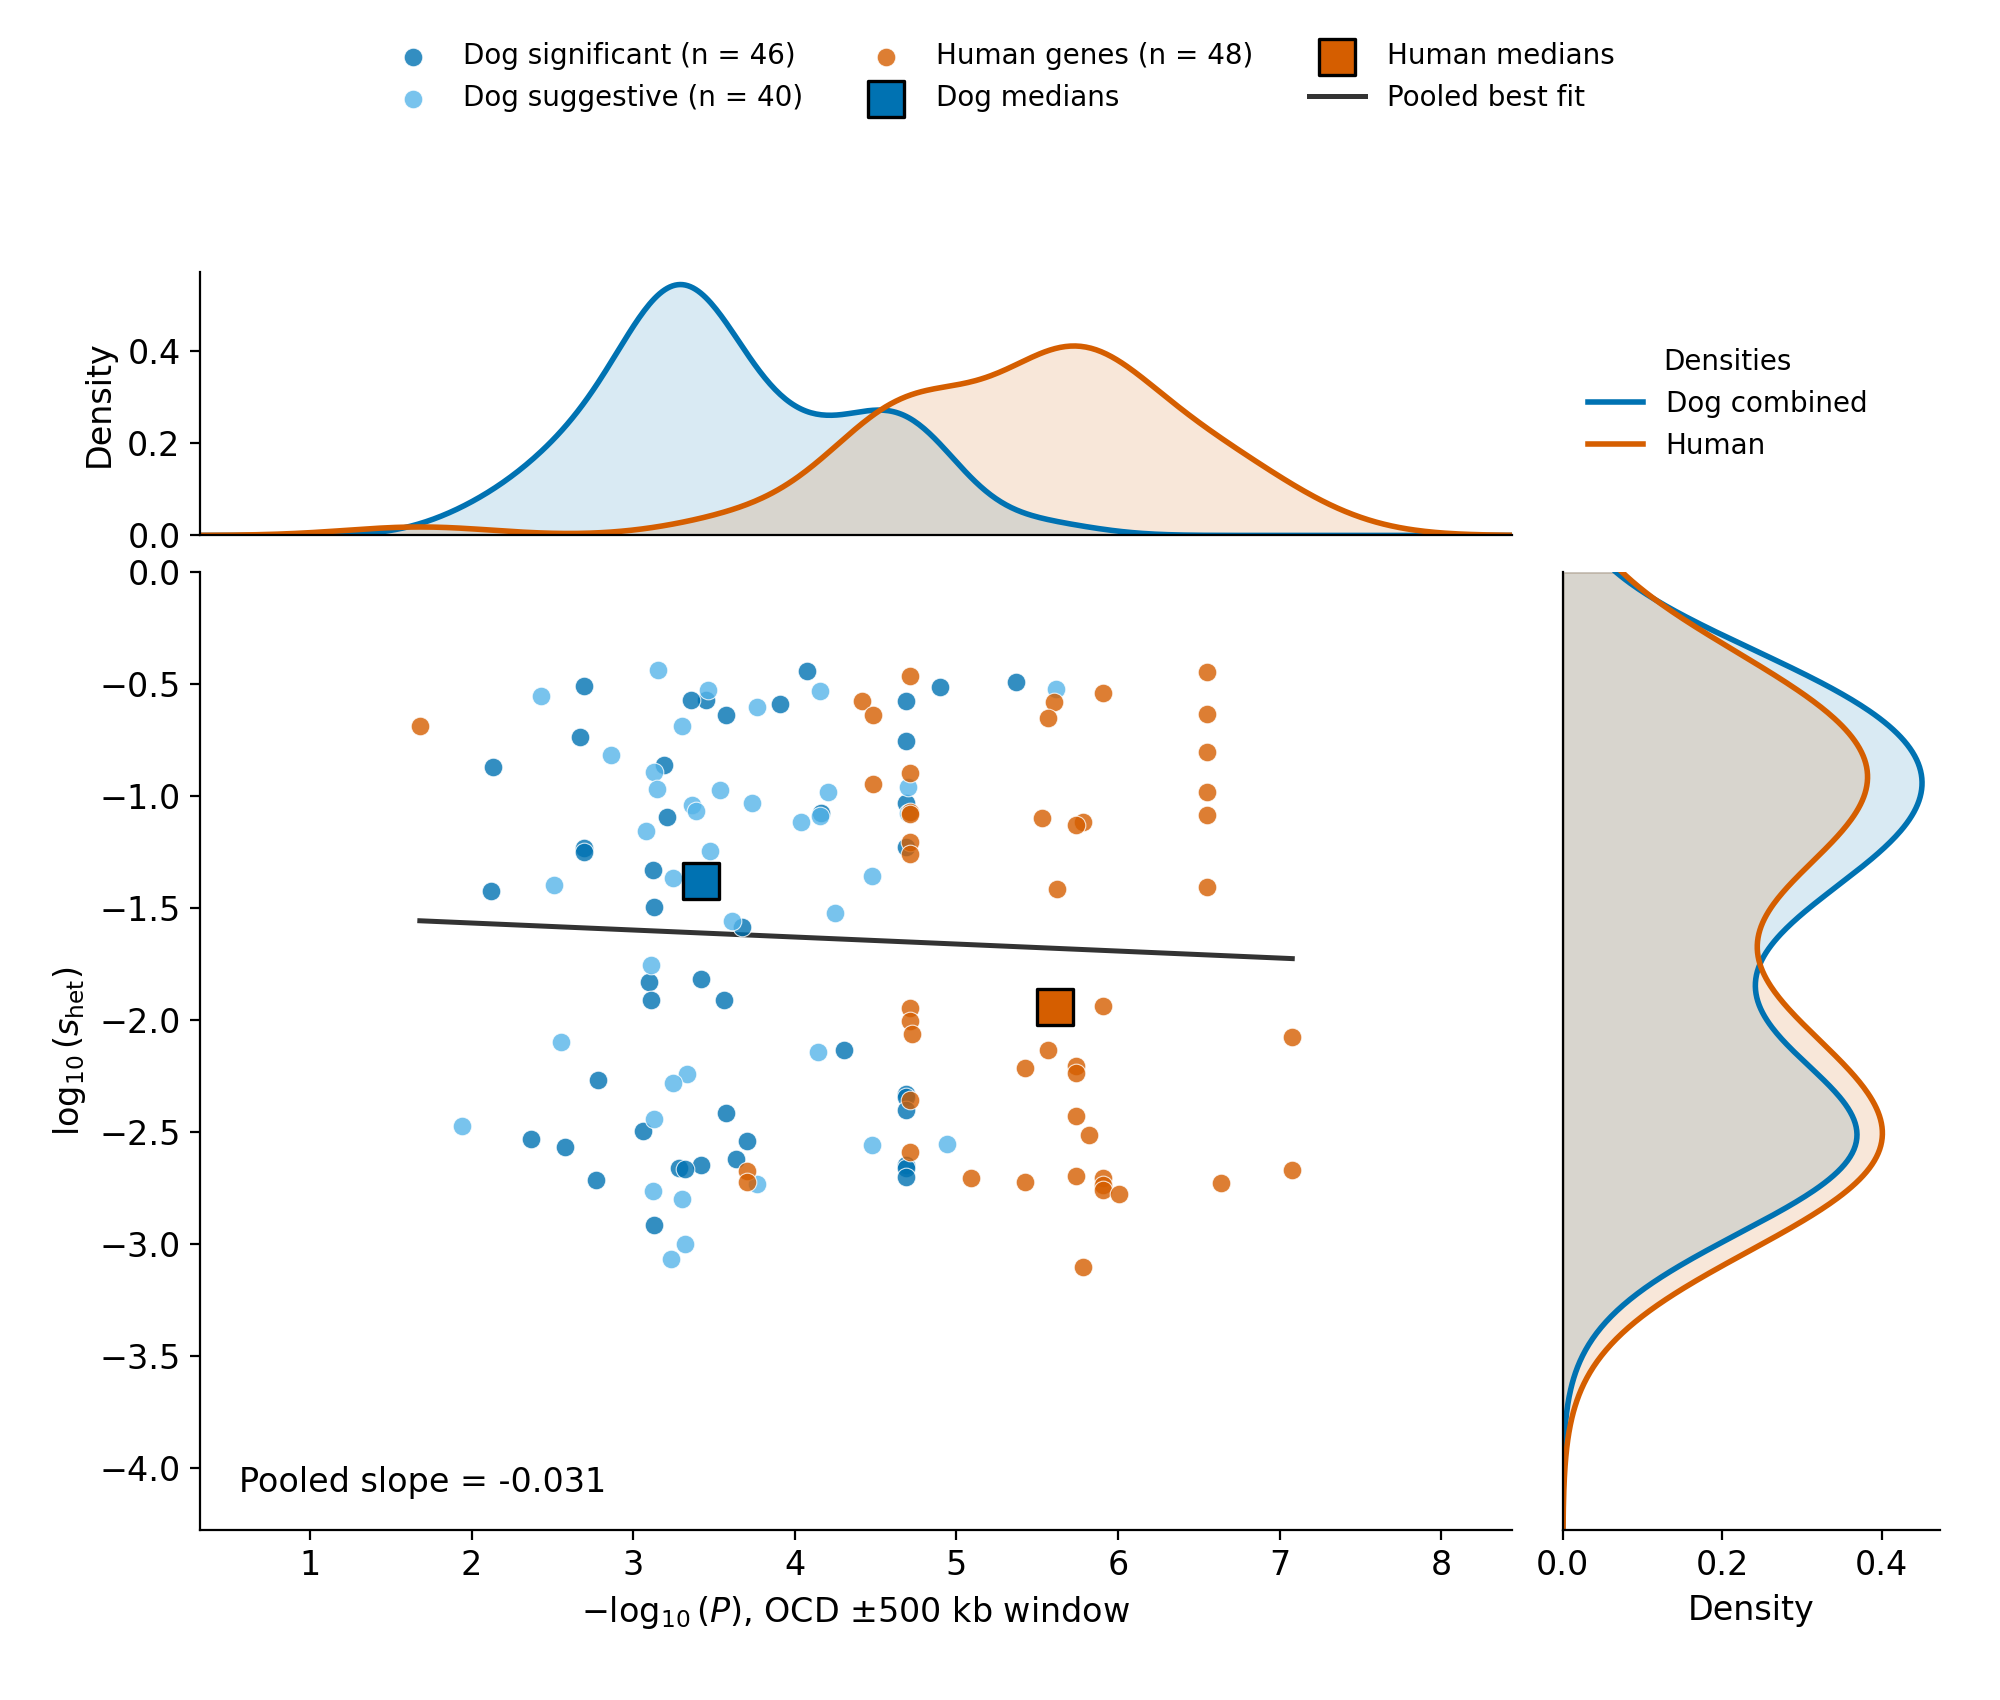

In [55]:
from IPython.display import Image

display(Image(filename=str(ROOT / "notebook/results/shet/shet_vs_ocd_500kb.png")))